<a href="https://colab.research.google.com/github/nischalbhandari1822-bit/ngc7039-open-cluster-analysis-/blob/main/notebooks/ngc7039_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install astroquery -q

from astroquery.vizier import Vizier

# Remove row limit (default is 50)
Vizier.ROW_LIMIT = -1

# Query the main clusters table from Hunt & Reffert 2023 (Paper III)
catalog_id = "J/A+A/686/A42/clusters"
result = Vizier.get_catalogs(catalog_id)

clusters = result[0]  # this is an astropy Table
print(len(clusters))
clusters

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 62.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 54.1 MB/s eta 0:00:00
7167


Name,ID,Type,N,RA_ICRS,DE_ICRS,r50,pmRA,pmDE,Plx,dist50,X,Y,Z,RV,isMerged,isGMMMemb,_RA.icrs,_DE.icrs
,,,,deg,deg,deg,mas / yr,mas / yr,mas,pc,pc,pc,pc,km / s,,,deg,deg
str20,int16,str1,int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,uint8,uint8,float64,float64
ADS_16795,1,m,41,352.59216492,58.55341329,2.65315906,18.65660390,2.84661253,4.75961052,206.45788462,-8200.94946741,190.52326760,11.39159669,-13.35774436,0,0,352.59200598,58.55340064
AH03_J0748-26.9,2,o,68,117.15588690,-26.97267949,0.03410633,-2.46548955,3.18503456,0.20935812,3979.06488330,-9916.03213687,-3551.44898508,-18.19460187,79.36052331,0,0,117.15589920,-26.97269365
ASCC_5,3,o,25,14.46908222,55.82917381,0.05449062,-2.40663082,-1.91881768,0.53819722,1740.98320690,-9084.80322366,1435.13376878,-189.84723555,--,0,0,14.46910126,55.82918234
ASCC_6,4,o,209,26.84215882,57.73860678,0.14360169,-0.83414476,0.14917466,0.62966733,1501.88586403,-9092.16756942,1141.10435903,-89.94835549,-28.83784149,0,0,26.84216577,57.73860612
ASCC_9,5,o,136,41.62390108,57.77684685,0.13843873,0.16875807,-1.13867954,0.40228194,2299.27724834,-9824.86028517,1543.56812999,-44.38768079,-23.79108670,0,0,41.62389967,57.77685191
ASCC_11,6,o,315,53.05042398,44.84076681,0.19207440,0.90530141,-3.07237438,1.17058217,825.93527220,-8832.20569243,400.79571103,-109.97428856,-17.28520635,0,0,53.05041831,44.84078046
ASCC_12,7,o,157,72.42059742,41.71429711,0.22342249,-0.67604714,-2.91644873,0.95498910,1014.51750457,-9091.80452938,296.14659945,-10.35242349,-26.14465879,0,0,72.42060145,41.71431007
ASCC_13,8,o,117,78.22066967,44.36502692,0.26536140,-0.54823427,-1.80948014,0.88155036,1076.15264565,-9152.33454102,304.67008894,81.10342370,-17.42266769,0,0,78.22067308,44.36503496


In [2]:
print(clusters.colnames)


['Name', 'ID', 'Type', 'N', 'RA_ICRS', 'DE_ICRS', 'r50', 'pmRA', 'pmDE', 'Plx', 'dist50', 'X', 'Y', 'Z', 'RV', 'isMerged', 'isGMMMemb', '_RA.icrs', '_DE.icrs']


In [3]:
# 'o' classifies the stars as members from open clusters
# N=50 to 2000 (N= no. of stars) is used for standard reason for being statistically correct
#r50< 2000 means < 2kpc is a metric for choosing a highly
#compact star or a dense dwarf galaxy.
mask = (
    (clusters['Type'] == 'o') &
    (clusters['N'] >= 50) & (clusters['N'] <= 300) &
    (clusters['dist50'] <= 2000)   # distance in pc
)

shortlist = clusters[mask]
print(len(shortlist))
shortlist

1214


Name,ID,Type,N,RA_ICRS,DE_ICRS,r50,pmRA,pmDE,Plx,dist50,X,Y,Z,RV,isMerged,isGMMMemb,_RA.icrs,_DE.icrs
,,,,deg,deg,deg,mas / yr,mas / yr,mas,pc,pc,pc,pc,km / s,,,deg,deg
str20,int16,str1,int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,uint8,uint8,float64,float64
ASCC_6,4,o,209,26.84215882,57.73860678,0.14360169,-0.83414476,0.14917466,0.62966733,1501.88586403,-9092.16756942,1141.10435903,-89.94835549,-28.83784149,0,0,26.84216577,57.73860612
ASCC_12,7,o,157,72.42059742,41.71429711,0.22342249,-0.67604714,-2.91644873,0.95498910,1014.51750457,-9091.80452938,296.14659945,-10.35242349,-26.14465879,0,0,72.42060145,41.71431007
ASCC_13,8,o,117,78.22066967,44.36502692,0.26536140,-0.54823427,-1.80948014,0.88155036,1076.15264565,-9152.33454102,304.67008894,81.10342370,-17.42266769,0,0,78.22067308,44.36503496
ASCC_19,11,o,61,81.97812989,-1.85602240,0.32300055,1.16771674,-1.18247821,2.80542177,352.07912043,-8423.79916201,-139.25454135,-95.25631690,11.65061088,0,0,81.97812470,-1.85601714
ASCC_20,12,o,194,82.19355425,1.72130405,0.65332128,-0.56909510,0.75899004,2.73024842,361.20759548,-8442.61793005,-126.77889871,-86.83410936,27.88555658,0,0,82.19355678,1.72130068
ASCC_21,13,o,116,82.21204038,3.60658547,0.46182925,1.53235340,-0.57628365,2.90244259,340.73440964,-8429.40083388,-111.09328447,-75.35909798,10.16829406,0,0,82.21203356,3.60658803
ASCC_23,14,o,194,95.02982828,46.68569526,0.31459874,1.07858876,-0.63605991,1.60932656,603.67282762,-8692.42582683,126.65644259,172.33553521,-13.25086514,0,0,95.02982129,46.68569809
ASCC_29,18,o,91,103.58953286,-1.66867729,0.12916020,-0.99378007,-1.05053240,0.97071031,993.44651786,-8938.23819814,-566.25761179,20.95797936,12.10932459,0,0,103.58953728,-1.66867262


In [4]:
import numpy as np


In [5]:
# Exclude famous/overstudied clusters by name pattern
# Also narrow N and distance further to keep it manageable, and prefer moderate age (avoids trivial/very young sparse clusters)

exclude_keywords = ['Melotte_22', 'NGC_2632', 'NGC_752', 'NGC_2168',
                     'NGC_869', 'NGC_884', 'NGC_6791', 'IC_4665']
# add more famous ones as needed - Pleiades=Melotte_22, Praesepe=NGC_2632, M67=NGC_2682 etc.

exclude_mask = ~np.isin(shortlist['Name'], exclude_keywords)

shortlist2 = shortlist[exclude_mask]

# Tighten N and distance to get a smaller, more workable batch
mask2 = (
    (shortlist2['N'] >= 80) & (shortlist2['N'] <= 200) &
    (shortlist2['dist50'] >= 300) & (shortlist2['dist50'] <= 1200)
)

shortlist3 = shortlist2[mask2]
print(len(shortlist3))
shortlist3

303


Name,ID,Type,N,RA_ICRS,DE_ICRS,r50,pmRA,pmDE,Plx,dist50,X,Y,Z,RV,isMerged,isGMMMemb,_RA.icrs,_DE.icrs
,,,,deg,deg,deg,mas / yr,mas / yr,mas,pc,pc,pc,pc,km / s,,,deg,deg
str20,int16,str1,int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,uint8,uint8,float64,float64
ASCC_12,7,o,157,72.42059742,41.71429711,0.22342249,-0.67604714,-2.91644873,0.95498910,1014.51750457,-9091.80452938,296.14659945,-10.35242349,-26.14465879,0,0,72.42060145,41.71431007
ASCC_13,8,o,117,78.22066967,44.36502692,0.26536140,-0.54823427,-1.80948014,0.88155036,1076.15264565,-9152.33454102,304.67008894,81.10342370,-17.42266769,0,0,78.22067308,44.36503496
ASCC_20,12,o,194,82.19355425,1.72130405,0.65332128,-0.56909510,0.75899004,2.73024842,361.20759548,-8442.61793005,-126.77889871,-86.83410936,27.88555658,0,0,82.19355678,1.72130068
ASCC_21,13,o,116,82.21204038,3.60658547,0.46182925,1.53235340,-0.57628365,2.90244259,340.73440964,-8429.40083388,-111.09328447,-75.35909798,10.16829406,0,0,82.21203356,3.60658803
ASCC_23,14,o,194,95.02982828,46.68569526,0.31459874,1.07858876,-0.63605991,1.60932656,603.67282762,-8692.42582683,126.65644259,172.33553521,-13.25086514,0,0,95.02982129,46.68569809
ASCC_29,18,o,91,103.58953286,-1.66867729,0.12916020,-0.99378007,-1.05053240,0.97071031,993.44651786,-8938.23819814,-566.25761179,20.95797936,12.10932459,0,0,103.58953728,-1.66867262
ASCC_30,19,o,88,104.23729253,-6.21213759,0.19396602,-1.57923518,-0.15666855,0.88755763,1060.38401827,-8944.76344474,-668.33060656,-6.85778488,15.53417802,0,0,104.23729959,-6.21213689
ASCC_51,23,o,172,140.39672670,-69.85529430,0.54756228,-7.61303782,7.96359467,1.81832702,544.83474207,-7971.36750979,-506.72556458,-111.07863513,8.73466910,0,0,140.39682495,-69.85532969


In [6]:
mask3 = (
    (shortlist3['N'] >= 120) & (shortlist3['N'] <= 200) &
    (shortlist3['dist50'] >= 500) & (shortlist3['dist50'] <= 900)
)
# focusing on
shortlist4 = shortlist3[mask3]
print(len(shortlist4))
shortlist4

66


Name,ID,Type,N,RA_ICRS,DE_ICRS,r50,pmRA,pmDE,Plx,dist50,X,Y,Z,RV,isMerged,isGMMMemb,_RA.icrs,_DE.icrs
,,,,deg,deg,deg,mas / yr,mas / yr,mas,pc,pc,pc,pc,km / s,,,deg,deg
str20,int16,str1,int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,uint8,uint8,float64,float64
ASCC_23,14,o,194,95.02982828,46.68569526,0.31459874,1.07858876,-0.63605991,1.60932656,603.67282762,-8692.42582683,126.65644259,172.33553521,-13.25086514,0,0,95.02982129,46.68569809
ASCC_51,23,o,172,140.39672670,-69.85529430,0.54756228,-7.61303782,7.96359467,1.81832702,544.83474207,-7971.36750979,-506.72556458,-111.07863513,8.73466910,0,0,140.39682495,-69.85532969
ASCC_90,45,o,184,264.76196704,-34.81736389,0.94492222,-1.52864961,-2.65506629,1.70642716,571.03444960,-7554.16392820,-57.02549432,0.28469280,6.27788425,0,0,264.76197532,-34.81735209
ASCC_105,53,o,173,295.47160222,27.38609425,0.47671482,1.36975029,-1.61801442,1.77588144,553.35901037,-7869.22837856,491.86248384,40.73646454,-16.19158851,0,0,295.47159536,27.38610144
ASCC_111,58,o,163,302.96058097,37.53095892,0.23850381,-1.14612856,-1.57601198,1.15987112,843.97450001,-7900.14595779,813.77846677,49.95758228,-14.19964618,0,0,302.96058739,37.53096592
Alessi_19,78,o,164,274.53414341,11.89734723,0.66767579,-1.00949089,-7.07447577,1.70890607,574.55640179,-7691.87811768,359.74683359,146.16088634,-7.86598280,0,0,274.53414800,11.89737867
Alessi_33,84,o,194,105.70988129,-26.36541844,0.33166502,-3.21772184,3.48827087,1.24872351,778.58715185,-8531.18574394,-650.33199532,-104.94370257,34.10693915,0,0,105.70989725,-26.36543394
Alessi_190,104,o,166,238.74766950,-47.61920524,0.38366435,-6.63206353,-4.15203178,1.75393213,553.92953729,-7634.45678626,-259.37483019,64.27659253,-17.93801112,0,0,238.74771323,-47.61918679


In [7]:
shortlist4.sort('N')
print(list(shortlist4['Name']))

[np.str_('Theia_850'), np.str_('UPK_445'), np.str_('Theia_980'), np.str_('UPK_436'), np.str_('UPK_644'), np.str_('HXHWL_29'), np.str_('CWNU_338'), np.str_('UPK_29'), np.str_('ESO_130-06'), np.str_('OC_0367'), np.str_('Theia_643'), np.str_('UPK_4'), np.str_('Alessi-Teutsch_3'), np.str_('UPK_567'), np.str_('UPK_51'), np.str_('Theia_986'), np.str_('FSR_1197'), np.str_('HSC_2865'), np.str_('Theia_12'), np.str_('UPK_82'), np.str_('OC_0395'), np.str_('UPK_17'), np.str_('IC_5146'), np.str_('UPK_143'), np.str_('Theia_759'), np.str_('Theia_1408'), np.str_('UPK_599'), np.str_('NGC_7160'), np.str_('Theia_420'), np.str_('LDN_988e'), np.str_('OC_0370'), np.str_('UPK_5'), np.str_('COIN-Gaia_25'), np.str_('Casado-Alessi_1'), np.str_('NGC_1579'), np.str_('UPK_560'), np.str_('ASCC_111'), np.str_('Alessi_19'), np.str_('UPK_42'), np.str_('Alessi_190'), np.str_('NGC_2358'), np.str_('NGC_7039'), np.str_('Ferrero_1'), np.str_('ASCC_51'), np.str_('ASCC_105'), np.str_('HSC_764'), np.str_('Theia_862'), np.str_

After these I got 66 stars , among them I neglected the stars with no prior work. I then selected the stars which has gaia records (to be sure that they were not just asterism) I short listed 5: NGC 7160, IC 5146(Coccon Nebula),NGC 1579, NGC 2358, NGC 7039.

I considered NGC 2358 as my primary choice and NGC 7039 as my secondary choice. NGC 2358 became first choice since, it had fewer records, especially none dedicated to GAIA-era membership. CMD study existed so I thought my work will also have a small contribution. Previously I thought NGC 7039  having a high citation rate despite having fewer records might be because one paper is doing heavy lifting. I further checked in records of NGC 2358 that any of those is dedicated to GAIA DR3 membership + CMD + age of NGC 2358. Or either it has been flaged as a possible asterism or non real cluster anywhere.

I further went to SIMBAD and searched NGC 2358 and checked either that resolves to an object classified as "Cluster of stars" or "Open Cluster". I found it has been flagged as "As*" meaning asterism, not a physical cluster. Even though I had already used the code Type=='o' in code during masking, I decided to play safe. So, I dropped the idea of choosing it as my cluster.
 I did same checks for NGC 7039.

Then I pulled its row from the table with all  its information.

In [8]:
target = clusters[clusters['Name'] == 'NGC_7039']
target

Name,ID,Type,N,RA_ICRS,DE_ICRS,r50,pmRA,pmDE,Plx,dist50,X,Y,Z,RV,isMerged,isGMMMemb,_RA.icrs,_DE.icrs
,,,,deg,deg,deg,mas / yr,mas / yr,mas,pc,pc,pc,pc,km / s,,,deg,deg
str20,int16,str1,int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,uint8,uint8,float64,float64
NGC_7039,4838,o,170,317.65270046,45.58245926,0.13762011,-0.23972969,-2.62634737,1.31799000,742.59518945,-8093.94504805,741.73525799,-1.35481504,-7.44241036,0,0,317.65270198,45.58247093


In [9]:
import glob
from astropy.io import fits
from astropy.table import Table

# Find the uploaded file (Colab shows it as "asu (3).fit", with a space)
files = glob.glob("/content/asu*.fit*")
print("Found:", files)
fn = files[0]

# Check what is inside
with fits.open(fn) as hdul:
    hdul.info()
    n_ext = len(hdul)

if n_ext < 2:
    print("\nThis file has NO table inside (header only), so it is empty.")
    print("Download it again from VizieR: clear the cone/target box,")
    print("put 4838 in the ID box (leave Name empty), tick all columns,")
    print("choose FITS (binary), and check the file is larger than a few KB.")
else:
    t = Table.read(fn, hdu=1)
    print("\nRows:", len(t))
    print("Columns:", t.colnames)
    t.write("ngc7039_members.fits", overwrite=True)
    print("Saved: ngc7039_members.fits")

Found: ['/content/asu (3).fit']
Filename: /content/asu (3).fit
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      55   ()      
  1  J_A_A_686_A42_members    1 BinTableHDU    110   1291929R x 19C   [D, D, 20A, I, K, B, D, D, D, D, D, D, D, D, D, D, D, D, J]   

Rows: 1291929
Columns: ['_RAJ2000', '_DEJ2000', 'Name', 'ID', 'GaiaDR3', 'inrt', 'Prob', 'RA_ICRS', 'DE_ICRS', 'pmRA', 'pmDE', 'Plx', 'Gmag', 'BPmag', 'RPmag', 'RV', '_RA_icrs', '_DE_icrs', 'recno']
Saved: ngc7039_members.fits


In [36]:
from google.colab import files

files.download('final_members_tier1.csv')
files.download('final_members_tier2.csv')
files.download('parsec_gaiaEDR3.csv')
files.download('step3c_membership.csv')






<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Rows in full table: 1291929
Rows with ID 4838 and Name NGC_7039: 170 (expected about 170)

Column ranges:
         count      min      50%      max    std
Prob     170.0    0.552    0.712    1.000  0.149
RA_ICRS  170.0  317.178  317.675  319.018  0.276
DE_ICRS  170.0   45.045   45.576   46.665  0.224
pmRA     170.0   -0.647   -0.232    0.194  0.153
pmDE     170.0   -3.146   -2.598   -2.151  0.185
Plx      170.0    1.172    1.321    1.441  0.050
Gmag     170.0    8.603   17.628   20.020  2.345
BP_RP    170.0   -0.085    2.619    3.434  0.874

Median proper motion: pmRA = -0.232, pmDE = -2.598 mas/yr
Median parallax: 1.321 mas (distance about 757 pc, no zero-point correction)
G range: 8.60 to 20.02
Probability: min 0.55, median 0.71, stars with Prob < 0.7: 81
Stars with Gaia RV: 27


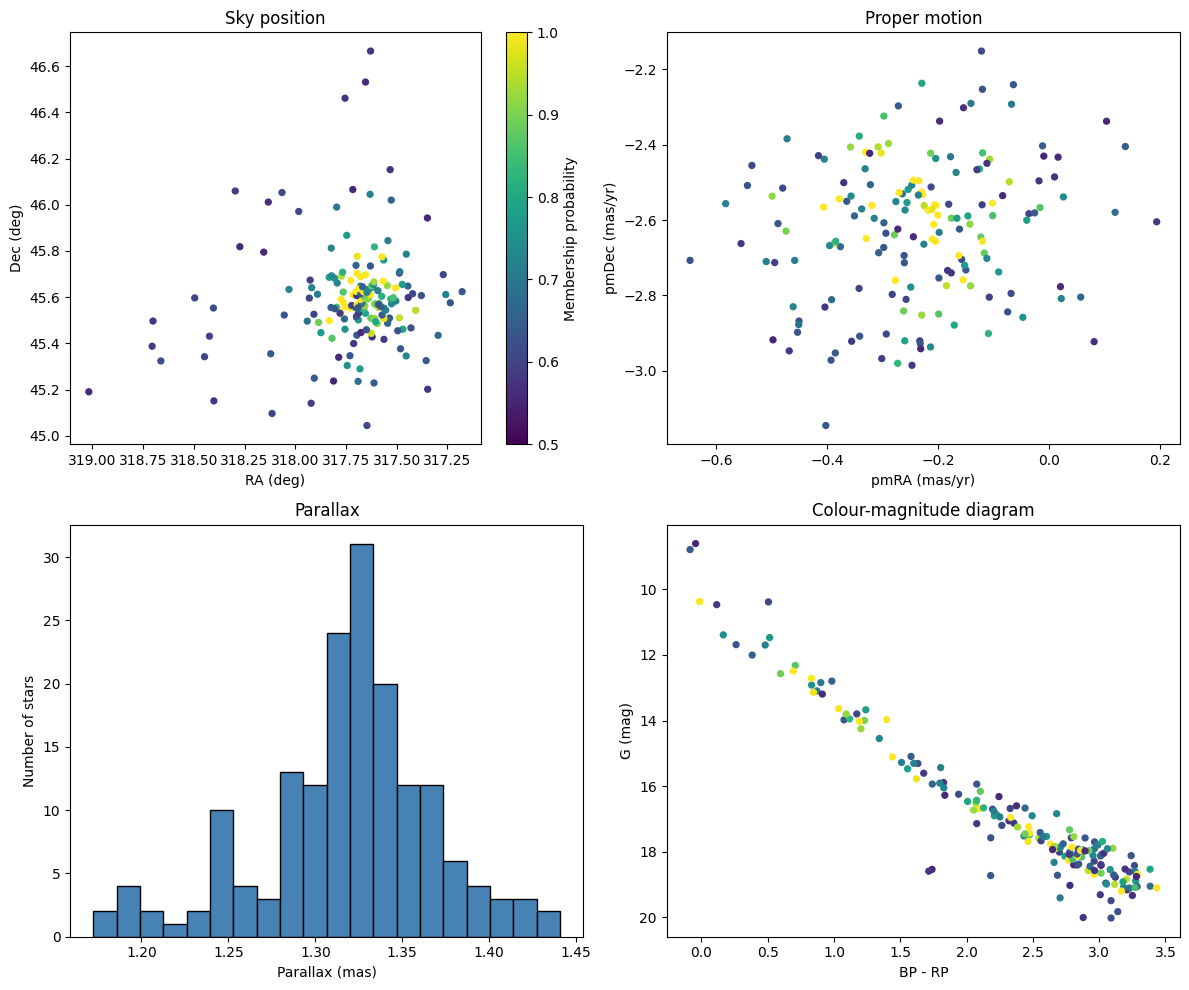


Saved: hr24_ngc7039_members.csv (download it from the Files panel to keep it)


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table

# ---------- 1. Read the full table ----------
t = Table.read("/content/ngc7039_members.fits")
print("Rows in full table:", len(t))

# ---------- 2. Keep only NGC 7039 (ID 4838) ----------
names = np.char.strip(np.asarray(t["Name"]).astype(str))
sel = (np.asarray(t["ID"]) == 4838) & (names == "NGC_7039")
print("Rows with ID 4838 and Name NGC_7039:", sel.sum(), "(expected about 170)")
t = t[sel]

# ---------- 3. Convert to pandas (native byte order, masked values -> NaN) ----------
def to_float(col):
    arr = col.filled(np.nan) if hasattr(col, "filled") else col
    return np.asarray(arr, dtype=np.float64)      # forces native byte order

members = pd.DataFrame({"GaiaDR3": np.asarray(t["GaiaDR3"], dtype=np.int64)})
for c in ["Prob", "RA_ICRS", "DE_ICRS", "pmRA", "pmDE", "Plx",
          "Gmag", "BPmag", "RPmag", "RV"]:
    members[c] = to_float(t[c])
members["BP_RP"] = members["BPmag"] - members["RPmag"]

# ---------- 4. Summary numbers ----------
print("\nColumn ranges:")
print(members[["Prob", "RA_ICRS", "DE_ICRS", "pmRA", "pmDE", "Plx", "Gmag", "BP_RP"]]
      .describe().T[["count", "min", "50%", "max", "std"]].round(3))

print("\nMedian proper motion: pmRA = %.3f, pmDE = %.3f mas/yr"
      % (members["pmRA"].median(), members["pmDE"].median()))
print("Median parallax: %.3f mas (distance about %.0f pc, no zero-point correction)"
      % (members["Plx"].median(), 1000 / members["Plx"].median()))
print("G range: %.2f to %.2f" % (members["Gmag"].min(), members["Gmag"].max()))
print("Probability: min %.2f, median %.2f, stars with Prob < 0.7: %d"
      % (members["Prob"].min(), members["Prob"].median(), (members["Prob"] < 0.7).sum()))
print("Stars with Gaia RV:", members["RV"].notna().sum())

# ---------- 5. Four diagnostic panels, coloured by probability ----------
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

sc = ax[0, 0].scatter(members["RA_ICRS"], members["DE_ICRS"], c=members["Prob"],
                      s=18, cmap="viridis", vmin=0.5, vmax=1)
ax[0, 0].invert_xaxis()
ax[0, 0].set(xlabel="RA (deg)", ylabel="Dec (deg)", title="Sky position")
plt.colorbar(sc, ax=ax[0, 0], label="Membership probability")

ax[0, 1].scatter(members["pmRA"], members["pmDE"], c=members["Prob"],
                 s=18, cmap="viridis", vmin=0.5, vmax=1)
ax[0, 1].set(xlabel="pmRA (mas/yr)", ylabel="pmDec (mas/yr)", title="Proper motion")

ax[1, 0].hist(members["Plx"].dropna(), bins=20, color="steelblue", edgecolor="k")
ax[1, 0].set(xlabel="Parallax (mas)", ylabel="Number of stars", title="Parallax")

ax[1, 1].scatter(members["BP_RP"], members["Gmag"], c=members["Prob"],
                 s=18, cmap="viridis", vmin=0.5, vmax=1)
ax[1, 1].invert_yaxis()
ax[1, 1].set(xlabel="BP - RP", ylabel="G (mag)", title="Colour-magnitude diagram")

plt.tight_layout()
plt.show()

# ---------- 6. Save for Step 4 ----------
members.to_csv("hr24_ngc7039_members.csv", index=False)
print("\nSaved: hr24_ngc7039_members.csv (download it from the Files panel to keep it)")

In [12]:
!pip install -q --upgrade astroquery pyvo

import time
import astroquery, pyvo
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.gaia import Gaia
from astroquery.vizier import Vizier, conf as vconf

print("astroquery", astroquery.__version__, "| pyvo", pyvo.__version__, "\n")

def attempt(label, fn):
    t0 = time.time()
    try:
        out = fn()
        print(f"[OK]   {label}: {out}  ({time.time()-t0:.0f}s)")
    except Exception as e:
        print(f"[FAIL] {label}: {str(e)[:160]}")

SQL = "SELECT TOP 5 source_id, ra, dec, phot_g_mean_mag FROM gaiadr3.gaia_source"

# --- Gaia ESA archive through astroquery ---
attempt("Gaia astroquery, synchronous",
        lambda: len(Gaia.launch_job(SQL).get_results()))
attempt("Gaia astroquery, asynchronous",
        lambda: len(Gaia.launch_job_async(SQL).get_results()))

# --- Gaia ESA archive through pyvo, bypassing astroquery ---
ESA = "https://gea.esac.esa.int/tap-server/tap"
attempt("Gaia ESA TAP via pyvo, synchronous",
        lambda: len(pyvo.dal.TAPService(ESA).run_sync(SQL).to_table()))
attempt("Gaia ESA TAP via pyvo, asynchronous",
        lambda: len(pyvo.dal.TAPService(ESA).run_async(SQL).to_table()))

# --- Another Gaia data centre (ARI Heidelberg; I have not verified this address) ---
ARI = "https://gaia.ari.uni-heidelberg.de/tap"
attempt("Gaia ARI Heidelberg TAP, synchronous",
        lambda: len(pyvo.dal.TAPService(ARI).run_sync(SQL).to_table()))

# --- Gaia DR3 copy in VizieR (catalogue I/355/gaiadr3) on three servers ---
pos = SkyCoord(317.663 * u.deg, 45.597 * u.deg)
for server in ["vizier.cds.unistra.fr", "vizier.cfa.harvard.edu", "vizier.nao.ac.jp"]:
    def test(server=server):
        vconf.server, vconf.timeout = server, 60
        r = Vizier(columns=["Source", "Gmag"], row_limit=5).query_region(
            pos, radius=0.05 * u.deg, catalog="I/355/gaiadr3")
        return len(r[0])
    attempt(f"VizieR Gaia DR3 on {server}", test)

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.
astroquery 0.4.11 | pyvo 1.9.1 

[OK]   Gaia astroquery, synchronous: 5  (1s)


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
[OK]   Gaia astroquery, asynchronous: 5  (3s)
[OK]   Gaia ESA TAP via pyvo, synchronous: 5  (1s)
[OK]   Gaia ESA TAP via pyvo, asynchronous: 5  (2s)
[OK]   Gaia ARI Heidelberg TAP, synchronous: 5  (1s)
[OK]   VizieR Gaia DR3 on vizier.cds.unistra.fr: 5  (1s)
[OK]   VizieR Gaia DR3 on vizier.cfa.harvard.edu: 5  (0s)
[OK]   VizieR Gaia DR3 on vizier.nao.ac.jp: 5  (0s)


G 6.000-19.000: 433256 stars -> too many, splitting
G 6.000-12.500: 2954 stars -> downloaded 2954 rows from ARI Heidelberg
G 12.500-19.000: 430302 stars -> too many, splitting
G 12.500-15.750: 47195 stars -> too many, splitting
G 15.750-19.000: 383107 stars -> too many, splitting
G 12.500-14.125: 10368 stars -> downloaded 10368 rows from ARI Heidelberg
G 14.125-15.750: 36827 stars -> too many, splitting
G 15.750-17.375: 111620 stars -> too many, splitting
G 17.375-19.000: 271487 stars -> too many, splitting
G 14.125-14.938: 12824 stars -> downloaded 12824 rows from ARI Heidelberg
G 14.938-15.750: 24003 stars -> too many, splitting
G 15.750-16.562: 42562 stars -> too many, splitting
G 16.562-17.375: 69058 stars -> too many, splitting
G 17.375-18.188: 106753 stars -> too many, splitting
G 18.188-19.000: 164734 stars -> too many, splitting
G 14.938-15.344: 10248 stars -> downloaded 10248 rows from ARI Heidelberg
G 15.344-15.750: 13755 stars -> downloaded 13755 rows from ARI Heidelberg
G 1

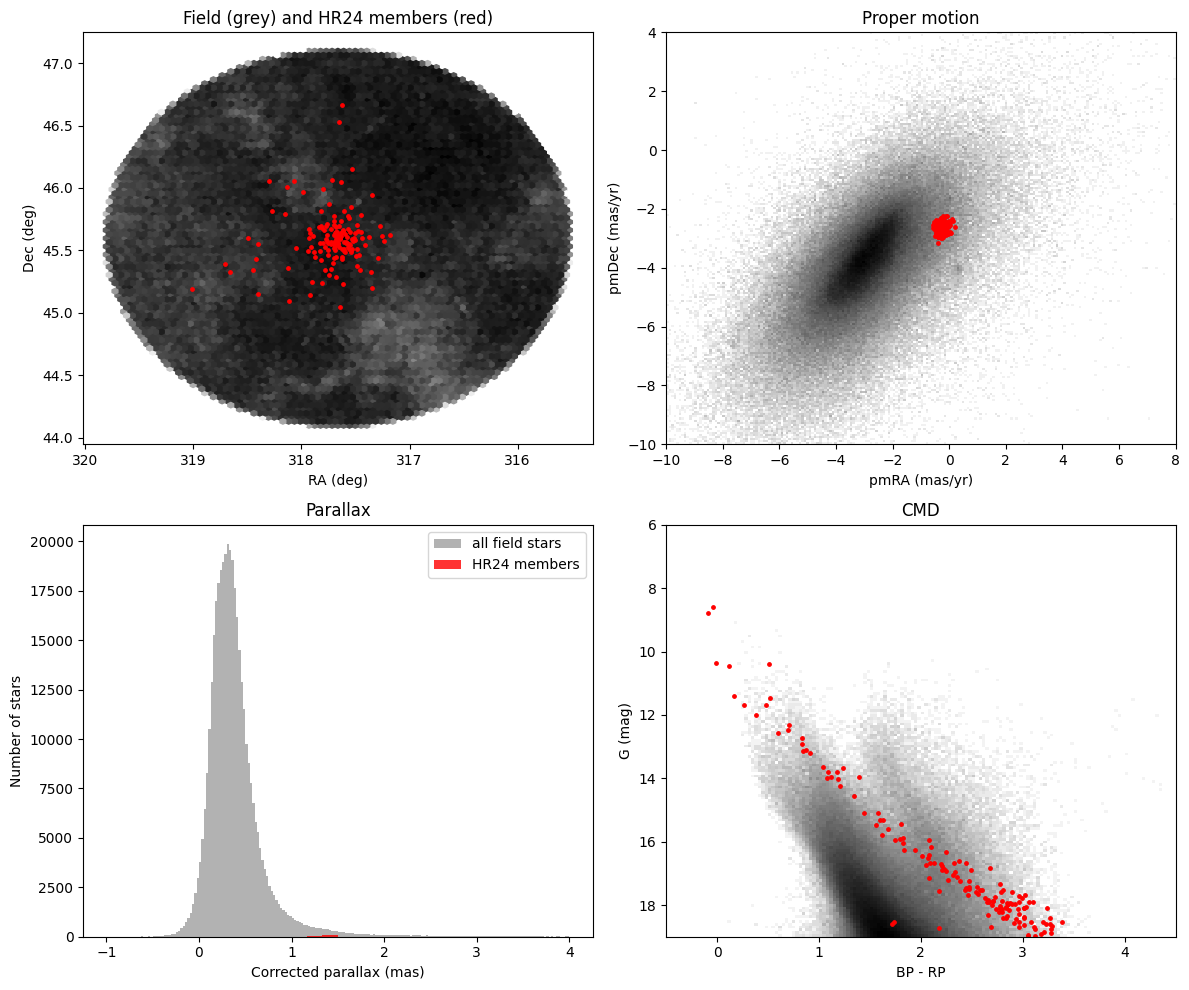


Saved: gaia_field_ngc7039.csv and gaia_field_raw.csv
Download both from the Files panel now: Colab deletes files when the session ends.


In [13]:
!pip install -q gaiadr3-zeropoint pyvo

import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import pyvo
from zero_point import zpt

RA0, DEC0, RADIUS = 317.663, 45.597, 1.5      # degrees (SIMBAD centre of NGC 7039)
G_MIN, G_MAX = 6.0, 19.0                       # zero-point correction is valid for G > 6
ROW_CAP = 20000                                # small slices are safer on a flaky server
os.makedirs("slices", exist_ok=True)

SERVICES = [("ARI Heidelberg", "https://gaia.ari.uni-heidelberg.de/tap"),
            ("ESA archive",    "https://gea.esac.esa.int/tap-server/tap")]
tap = {name: pyvo.dal.TAPService(url) for name, url in SERVICES}

WHERE = f"""1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {RA0}, {DEC0}, {RADIUS}))
  AND parallax IS NOT NULL AND pmra IS NOT NULL
  AND astrometric_params_solved IN (31, 95)"""

def sync_query(adql):
    errors = []
    for name, _ in SERVICES:
        try:
            return tap[name].run_sync(adql, timeout=120).to_table(), name
        except Exception as e:
            errors.append(f"{name}: {str(e)[:70]}")
    raise RuntimeError(" | ".join(errors))

def count_stars(lo, hi):
    q = (f"SELECT COUNT(*) AS n FROM gaiadr3.gaia_source WHERE {WHERE} "
         f"AND phot_g_mean_mag >= {lo} AND phot_g_mean_mag < {hi}")
    for k in range(4):
        try:
            t, _ = sync_query(q)
            return int(t[t.colnames[0]][0])
        except Exception as e:
            print(f"   count attempt {k+1} failed: {str(e)[:100]}")
            time.sleep(5 * (k + 1))
    raise RuntimeError("Could not count stars. Wait a few minutes and run the cell again.")

COLS = ["source_id", "ra", "dec", "parallax", "parallax_error", "pmra", "pmra_error",
        "pmdec", "pmdec_error", "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag",
        "ruwe", "radial_velocity", "radial_velocity_error",
        "nu_eff_used_in_astrometry", "pseudocolour", "ecl_lat", "astrometric_params_solved"]
INT_COLS = {"source_id", "astrometric_params_solved"}

def fetch_stars(lo, hi):
    q = (f"SELECT {', '.join(COLS)} FROM gaiadr3.gaia_source WHERE {WHERE} "
         f"AND phot_g_mean_mag >= {lo} AND phot_g_mean_mag < {hi}")
    t, name = sync_query(q)
    low = {c.lower(): c for c in t.colnames}
    df = pd.DataFrame({
        c: (np.asarray(t[low[c]], dtype=np.int64) if c in INT_COLS else
            np.asarray(t[low[c]].filled(np.nan) if hasattr(t[low[c]], "filled") else t[low[c]],
                       dtype=np.float64))
        for c in COLS})
    return df, name

# ---------- 1. Download in magnitude slices (finished slices are cached on disk) ----------
todo, pieces = [(G_MIN, G_MAX)], []
while todo:
    lo, hi = todo.pop(0)
    cache = f"slices/slice_{lo:.4f}_{hi:.4f}.csv"
    if os.path.exists(cache):
        pieces.append(pd.read_csv(cache))
        print(f"G {lo:.3f}-{hi:.3f}: loaded from cache ({len(pieces[-1])} rows)")
        continue
    n = count_stars(lo, hi)
    print(f"G {lo:.3f}-{hi:.3f}: {n} stars", end="")
    if n == 0:
        print(" (skipped)")
        continue
    df = None
    if n <= ROW_CAP:
        try:
            df, name = fetch_stars(lo, hi)
        except Exception as e:
            print(f" -> download failed ({str(e)[:70]})", end="")
    if df is not None and len(df) == n:
        print(f" -> downloaded {len(df)} rows from {name}")
        df.to_csv(cache, index=False)
        pieces.append(df)
    elif (hi - lo) > 0.005:
        why = "too many" if n > ROW_CAP else ("rows missing" if df is not None else "failed")
        print(f" -> {why}, splitting")
        mid = (lo + hi) / 2
        todo += [(lo, mid), (mid, hi)]
    else:
        raise RuntimeError(f"Slice G {lo}-{hi} cannot be downloaded completely. Send me this message.")

# ---------- 2. Combine ----------
gaia = pd.concat(pieces, ignore_index=True).drop_duplicates(subset="source_id").reset_index(drop=True)
print("\nTotal stars downloaded:", len(gaia))
gaia.to_csv("gaia_field_raw.csv", index=False)     # backup before cleaning

# ---------- 3. Cleaning, with a count at every step ----------
n0 = len(gaia)
gaia = gaia[gaia["ruwe"] < 1.4]
print(f"After RUWE < 1.4:            {len(gaia)}  (removed {n0 - len(gaia)})")
n1 = len(gaia)
gaia = gaia.dropna(subset=["phot_bp_mean_mag", "phot_rp_mean_mag", "parallax_error",
                           "pmra_error", "pmdec_error"])
print(f"After requiring BP and RP:   {len(gaia)}  (removed {n1 - len(gaia)})")
gaia = gaia.reset_index(drop=True)

# ---------- 4. Parallax zero-point correction (Lindegren et al. 2021) ----------
zpt.load_tables()
gaia["zp"] = zpt.get_zpt(gaia["phot_g_mean_mag"].values,
                         gaia["nu_eff_used_in_astrometry"].values,
                         gaia["pseudocolour"].values,
                         gaia["ecl_lat"].values,
                         gaia["astrometric_params_solved"].values,
                         _warnings=False)
gaia["parallax_corr"] = gaia["parallax"] - gaia["zp"]
gaia["BP_RP"] = gaia["phot_bp_mean_mag"] - gaia["phot_rp_mean_mag"]
print("Median zero-point: %.4f mas" % np.nanmedian(gaia["zp"]))

# ---------- 5. Check the HR24 members against the cleaned field ----------
if not os.path.exists("hr24_ngc7039_members.csv"):
    raise FileNotFoundError("hr24_ngc7039_members.csv is missing. Re-run the Step 1 cell first.")
hr24 = pd.read_csv("hr24_ngc7039_members.csv")
hr24["GaiaDR3"] = hr24["GaiaDR3"].astype("int64")
gaia["in_HR24"] = gaia["source_id"].isin(set(hr24["GaiaDR3"]))
print(f"\nHR24 members found in cleaned Gaia field: {gaia['in_HR24'].sum()} of {len(hr24)}")
missing = hr24[~hr24["GaiaDR3"].isin(set(gaia["source_id"]))]
print(f"HR24 members NOT in the cleaned field: {len(missing)} "
      f"(RUWE >= 1.4, G outside {G_MIN}-{G_MAX}, or no 5/6-parameter solution)")
if len(missing):
    print(missing[["GaiaDR3", "Prob", "Gmag", "BP_RP"]].round(3).to_string(index=False))

# ---------- 6. Diagnostic plots: field in grey, HR24 members in red ----------
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
m = gaia["in_HR24"]

ax[0, 0].hexbin(gaia["ra"], gaia["dec"], gridsize=80, cmap="Greys", norm=LogNorm())
ax[0, 0].scatter(gaia.loc[m, "ra"], gaia.loc[m, "dec"], s=6, c="red")
ax[0, 0].invert_xaxis()
ax[0, 0].set(xlabel="RA (deg)", ylabel="Dec (deg)", title="Field (grey) and HR24 members (red)")

ax[0, 1].hist2d(gaia["pmra"], gaia["pmdec"], bins=200, range=[[-10, 8], [-10, 4]],
                cmap="Greys", norm=LogNorm())
ax[0, 1].scatter(gaia.loc[m, "pmra"], gaia.loc[m, "pmdec"], s=6, c="red")
ax[0, 1].set(xlabel="pmRA (mas/yr)", ylabel="pmDec (mas/yr)", title="Proper motion")

ax[1, 0].hist(gaia["parallax_corr"], bins=200, range=(-1, 4), color="grey", alpha=0.6,
              label="all field stars")
ax[1, 0].hist(gaia.loc[m, "parallax_corr"], bins=30, range=(-1, 4), color="red", alpha=0.8,
              label="HR24 members")
ax[1, 0].set(xlabel="Corrected parallax (mas)", ylabel="Number of stars", title="Parallax")
ax[1, 0].legend()

ax[1, 1].hist2d(gaia["BP_RP"], gaia["phot_g_mean_mag"], bins=150,
                range=[[-0.5, 4.5], [G_MIN, G_MAX]], cmap="Greys", norm=LogNorm())
ax[1, 1].scatter(gaia.loc[m, "BP_RP"], gaia.loc[m, "phot_g_mean_mag"], s=6, c="red")
ax[1, 1].invert_yaxis()
ax[1, 1].set(xlabel="BP - RP", ylabel="G (mag)", title="CMD")

plt.tight_layout()
plt.show()

# ---------- 7. Save for Step 3 ----------
gaia.to_csv("gaia_field_ngc7039.csv", index=False)
print("\nSaved: gaia_field_ngc7039.csv and gaia_field_raw.csv")
print("Download both from the Files panel now: Colab deletes files when the session ends.")

In [14]:
import pandas as pd

raw = pd.read_csv("gaia_field_raw.csv")
clean = pd.read_csv("gaia_field_ngc7039.csv")
hr24 = pd.read_csv("hr24_ngc7039_members.csv")
hr24["GaiaDR3"] = hr24["GaiaDR3"].astype("int64")

missing = hr24[~hr24["GaiaDR3"].isin(set(clean["source_id"]))]
faint = missing[missing["Gmag"] >= 19]
bright = missing[missing["Gmag"] < 19]
print(f"HR24 stars missing: {len(missing)} | fainter than G=19: {len(faint)} "
      f"| brighter than G=19: {len(bright)}")
print(f"HR24 stars brighter than G=19: {(hr24['Gmag'] < 19).sum()}")

info = bright.merge(raw[["source_id", "ruwe", "astrometric_params_solved"]],
                    left_on="GaiaDR3", right_on="source_id", how="left")
print("\nThe bright missing stars, with their RUWE from the raw download:")
print(info[["GaiaDR3", "Prob", "Gmag", "BP_RP", "ruwe", "astrometric_params_solved"]]
      .round(3).to_string(index=False))
print("\n(ruwe = NaN means the star is not in the raw download at all)")

HR24 stars missing: 20 | fainter than G=19: 16 | brighter than G=19: 4
HR24 stars brighter than G=19: 154

The bright missing stars, with their RUWE from the raw download:
            GaiaDR3  Prob   Gmag  BP_RP  ruwe  astrometric_params_solved
2164053636148456448 0.712 15.278  1.510 2.159                         31
2164055044897699072 0.896 13.996  1.231 1.485                         31
2164069269829511424 0.698 12.842  0.901 1.696                         31
2164270063825325440 0.656 12.798  0.984 2.591                         31

(ruwe = NaN means the star is not in the raw download at all)


Stars with G < 18.0, RUWE < 1.4: 217183
Stars inside the PM/parallax window: 4909
Window median (pmra, pmdec, plx): [-0.224 -2.668  0.864]

Converged: True | iterations: 34

Components (sigma = square root of the covariance diagonal):
  0: N =      214  mean (pmra, pmdec, plx) = [-0.201 -2.637  1.37 ]  sigma = [0.162 0.265 0.054]  <-- cluster
  1: N =     2876  mean (pmra, pmdec, plx) = [-0.383 -2.72   0.801]  sigma = [1.195 1.246 0.074]
  2: N =     1820  mean (pmra, pmdec, plx) = [-0.154 -2.725  1.124]  sigma = [1.14  1.189 0.247]

Stars with P > 0.5: 236 | P > 0.7: 202 | P > 0.9: 110 | sum of P: 214

HR24 members inside this sample: 99
  of those, with our P > 0.5: 97
  our P > 0.5 stars that are not in HR24: 139
HR24 median (pmRA, pmDE, Plx): -0.232, -2.598, 1.321


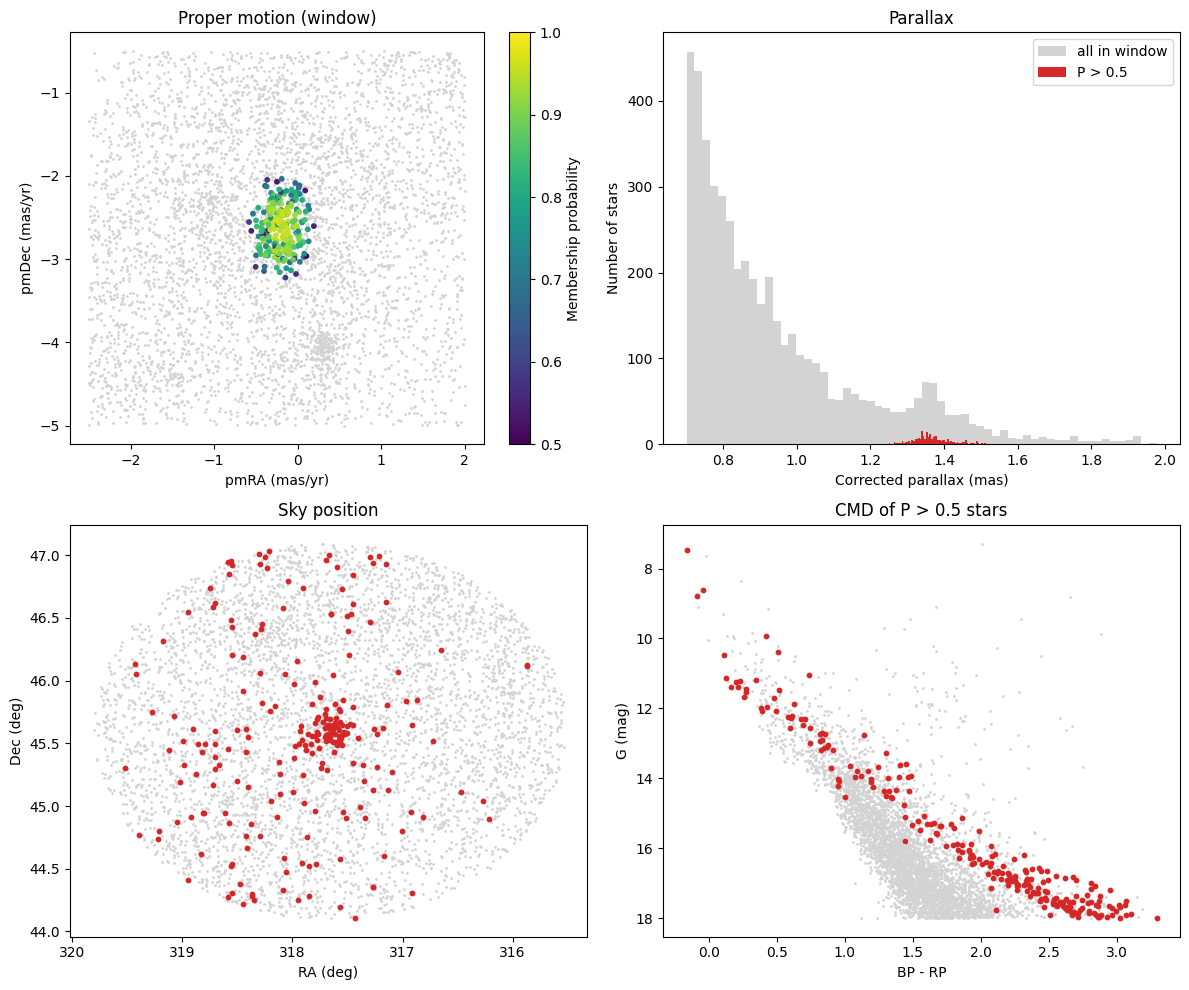


Saved: step3_gmm_membership.csv (download it from the Files panel)


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture

# ---------- 1. Load ----------
gaia = pd.read_csv("gaia_field_ngc7039.csv")
hr24 = pd.read_csv("hr24_ngc7039_members.csv")
hr24["GaiaDR3"] = hr24["GaiaDR3"].astype("int64")

# ---------- 2. Select the sample: G < 18 and a window around the cluster ----------
G_LIM = 18.0
PMRA_BOX, PMDEC_BOX, PLX_BOX = (-2.5, 2.0), (-5.0, -0.5), (0.7, 2.0)

df = gaia[(gaia["phot_g_mean_mag"] < G_LIM)
          & gaia["pmra"].between(*PMRA_BOX)
          & gaia["pmdec"].between(*PMDEC_BOX)
          & gaia["parallax_corr"].between(*PLX_BOX)].copy().reset_index(drop=True)
print(f"Stars with G < {G_LIM}, RUWE < 1.4: {(gaia['phot_g_mean_mag'] < G_LIM).sum()}")
print(f"Stars inside the PM/parallax window: {len(df)}")

X = df[["pmra", "pmdec", "parallax_corr"]].values
med = np.median(X, axis=0)
print("Window median (pmra, pmdec, plx):", np.round(med, 3))

# ---------- 3. Fit a 3-component Gaussian mixture ----------
means_init = np.array([[-0.25, -2.55, 1.33],              # cluster (literature values)
                       med + [-0.6, 0.0, 0.0],             # field 1
                       med + [+0.6, 0.0, 0.0]])            # field 2
prec_init = np.array([np.diag([1 / 0.15**2, 1 / 0.15**2, 1 / 0.08**2]),
                      np.diag([1 / 1.0**2, 1 / 1.0**2, 1 / 0.3**2]),
                      np.diag([1 / 1.0**2, 1 / 1.0**2, 1 / 0.3**2])])
gmm = GaussianMixture(n_components=3, covariance_type="full",
                      means_init=means_init, precisions_init=prec_init,
                      weights_init=[0.01, 0.5, 0.49],
                      max_iter=1000, tol=1e-6, random_state=0).fit(X)
print("\nConverged:", gmm.converged_, "| iterations:", gmm.n_iter_)

# Cluster component = the one with the smallest covariance determinant
k = int(np.argmin([np.linalg.det(c) for c in gmm.covariances_]))
print("\nComponents (sigma = square root of the covariance diagonal):")
for i in range(3):
    sig = np.sqrt(np.diag(gmm.covariances_[i]))
    tag = "  <-- cluster" if i == k else ""
    print(f"  {i}: N = {gmm.weights_[i] * len(df):8.0f}  mean (pmra, pmdec, plx) = "
          f"{np.round(gmm.means_[i], 3)}  sigma = {np.round(sig, 3)}{tag}")

df["P"] = gmm.predict_proba(X)[:, k]
print(f"\nStars with P > 0.5: {(df['P'] > 0.5).sum()} | P > 0.7: {(df['P'] > 0.7).sum()} "
      f"| P > 0.9: {(df['P'] > 0.9).sum()} | sum of P: {df['P'].sum():.0f}")

# ---------- 4. Sanity check against HR24 (not used in the fit) ----------
df["in_HR24"] = df["source_id"].isin(set(hr24["GaiaDR3"]))
n_hr = df["in_HR24"].sum()
print(f"\nHR24 members inside this sample: {n_hr}")
print(f"  of those, with our P > 0.5: {((df['P'] > 0.5) & df['in_HR24']).sum()}")
print(f"  our P > 0.5 stars that are not in HR24: {((df['P'] > 0.5) & ~df['in_HR24']).sum()}")
print("HR24 median (pmRA, pmDE, Plx): "
      f"{hr24['pmRA'].median():.3f}, {hr24['pmDE'].median():.3f}, {hr24['Plx'].median():.3f}")

# ---------- 5. Plots ----------
good = df[df["P"] > 0.5]
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

ax[0, 0].scatter(df["pmra"], df["pmdec"], s=1, c="lightgrey")
sc = ax[0, 0].scatter(good["pmra"], good["pmdec"], s=10, c=good["P"], cmap="viridis", vmin=0.5, vmax=1)
plt.colorbar(sc, ax=ax[0, 0], label="Membership probability")
ax[0, 0].set(xlabel="pmRA (mas/yr)", ylabel="pmDec (mas/yr)", title="Proper motion (window)")

ax[0, 1].hist(df["parallax_corr"], bins=60, color="lightgrey", label="all in window")
ax[0, 1].hist(good["parallax_corr"], bins=60, color="tab:red", label="P > 0.5")
ax[0, 1].set(xlabel="Corrected parallax (mas)", ylabel="Number of stars", title="Parallax")
ax[0, 1].legend()

ax[1, 0].scatter(df["ra"], df["dec"], s=1, c="lightgrey")
ax[1, 0].scatter(good["ra"], good["dec"], s=10, c="tab:red")
ax[1, 0].invert_xaxis()
ax[1, 0].set(xlabel="RA (deg)", ylabel="Dec (deg)", title="Sky position")

ax[1, 1].scatter(df["BP_RP"], df["phot_g_mean_mag"], s=1, c="lightgrey")
ax[1, 1].scatter(good["BP_RP"], good["phot_g_mean_mag"], s=10, c="tab:red")
ax[1, 1].invert_yaxis()
ax[1, 1].set(xlabel="BP - RP", ylabel="G (mag)", title="CMD of P > 0.5 stars")

plt.tight_layout()
plt.show()

# ---------- 6. Save ----------
df.to_csv("step3_gmm_membership.csv", index=False)
print("\nSaved: step3_gmm_membership.csv (download it from the Files panel)")

Cluster centre from P > 0.9 stars: RA = 317.696, Dec = 45.595

P > 0.5 within 80 arcmin: 205 (in HR24: 97, not in HR24: 108)

Radial profile (densities are stars per 1000 arcmin^2):
 ring  area  N_P05  N_shared  N_extra  dens_P05_per_1000  dens_extra_per_1000
  0-5    79     26        26        0             331.04                 0.00
 5-10   236     32        29        3             135.81                12.73
10-15   393     15        14        1              38.20                 2.55
15-20   550      9         8        1              16.37                 1.82
20-30  1571     15        11        4               9.55                 2.55
30-40  2199     24         5       19              10.91                 8.64
40-60  6283     41         3       38               6.53                 6.05
60-80  8796     43         1       42               4.89                 4.77

Outer ring 60-80 arcmin holds 43 stars with P > 0.5.
If that density applied everywhere, the whole field would cont

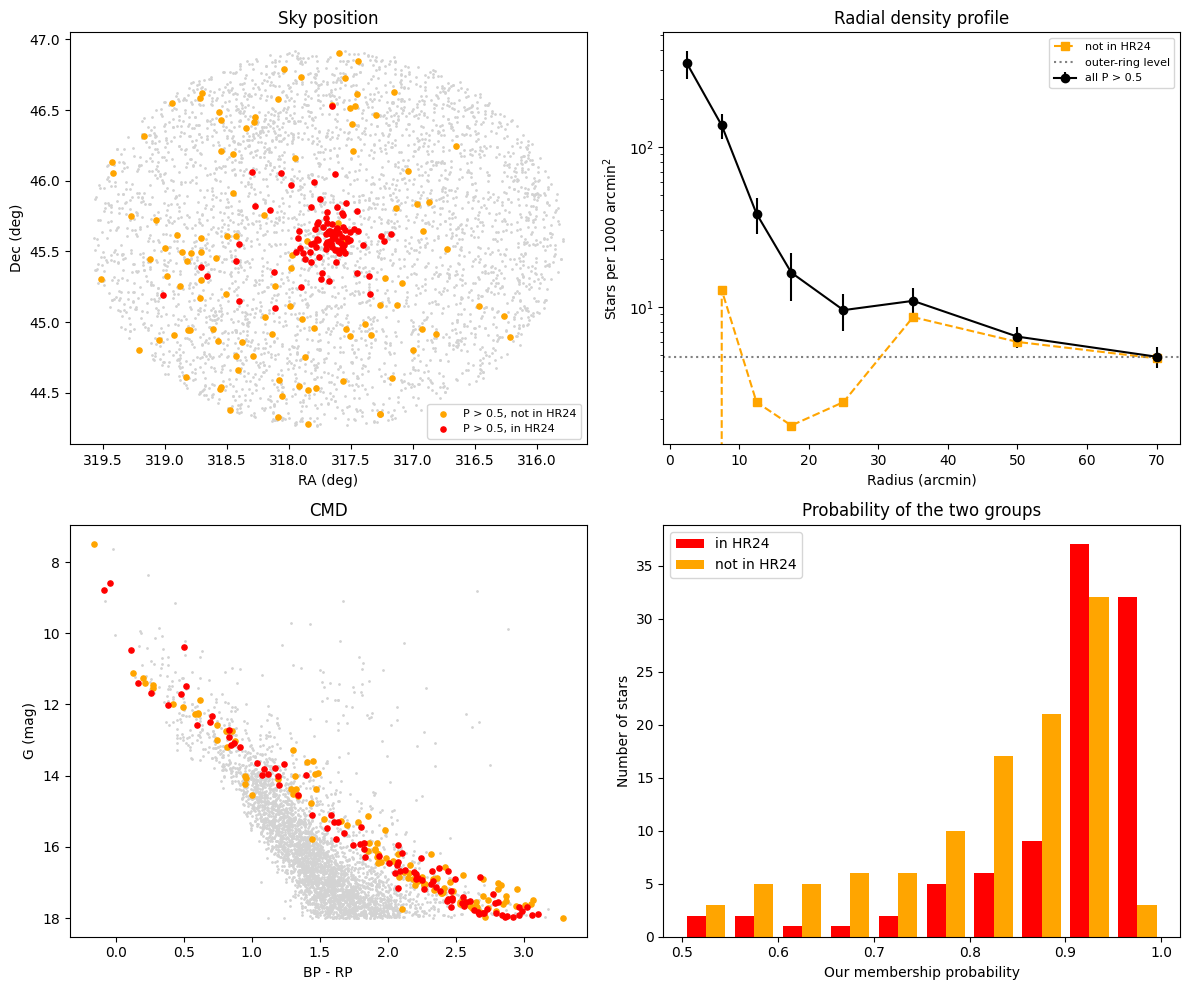

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------- 1. Load and compute distance from the cluster centre ----------
df = pd.read_csv("step3_gmm_membership.csv")
core = df[df["P"] > 0.9]
ra0, dec0 = core["ra"].median(), core["dec"].median()
print(f"Cluster centre from P > 0.9 stars: RA = {ra0:.3f}, Dec = {dec0:.3f}")
c0 = SkyCoord(ra0 * u.deg, dec0 * u.deg)
df["r"] = c0.separation(SkyCoord(df["ra"].values * u.deg, df["dec"].values * u.deg)).arcmin

R_MAX = 80.0                       # stay inside the 90-arcmin cone
d = df[df["r"] < R_MAX]
sel = d[d["P"] > 0.5]
shared = sel[sel["in_HR24"]]
extra = sel[~sel["in_HR24"]]
print(f"\nP > 0.5 within {R_MAX:.0f} arcmin: {len(sel)} "
      f"(in HR24: {len(shared)}, not in HR24: {len(extra)})")

# ---------- 2. Radial profile ----------
edges = np.array([0, 5, 10, 15, 20, 30, 40, 60, 80])
rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    area = np.pi * (hi**2 - lo**2)
    f = lambda s: ((s["r"] >= lo) & (s["r"] < hi)).sum()
    rows.append(dict(ring=f"{lo}-{hi}", area=round(area), N_P05=f(sel), N_shared=f(shared),
                     N_extra=f(extra), dens_P05_per_1000=1000 * f(sel) / area,
                     dens_extra_per_1000=1000 * f(extra) / area))
prof = pd.DataFrame(rows)
print("\nRadial profile (densities are stars per 1000 arcmin^2):")
print(prof.round(2).to_string(index=False))

# ---------- 3. Contamination estimate from the outer ring ----------
outer = sel[(sel["r"] >= 60) & (sel["r"] < R_MAX)]
dens_out = len(outer) / (np.pi * (R_MAX**2 - 60**2))
expected = dens_out * np.pi * R_MAX**2
print(f"\nOuter ring 60-80 arcmin holds {len(outer)} stars with P > 0.5.")
print(f"If that density applied everywhere, the whole field would contain about "
      f"{expected:.0f} such stars, out of {len(sel)} selected.")
print("(This is an UPPER limit on contamination, because real halo members also sit out there.)")

frac_uniform = (20 / R_MAX) ** 2
for name, s in [("shared with HR24", shared), ("not in HR24", extra)]:
    print(f"{name:18s}: median radius = {s['r'].median():5.1f} arcmin | "
          f"within 20 arcmin: {(s['r'] < 20).mean():.0%} "
          f"(a uniform field would give {frac_uniform:.0%})")

# ---------- 4. Plots ----------
fig, ax = plt.subplots(2, 2, figsize=(12, 10))

ax[0, 0].scatter(d["ra"], d["dec"], s=1, c="lightgrey")
ax[0, 0].scatter(extra["ra"], extra["dec"], s=14, c="orange", label="P > 0.5, not in HR24")
ax[0, 0].scatter(shared["ra"], shared["dec"], s=14, c="red", label="P > 0.5, in HR24")
ax[0, 0].invert_xaxis(); ax[0, 0].legend(fontsize=8)
ax[0, 0].set(xlabel="RA (deg)", ylabel="Dec (deg)", title="Sky position")

mid = 0.5 * (edges[:-1] + edges[1:])
ax[0, 1].errorbar(mid, prof["dens_P05_per_1000"],
                  yerr=1000 * np.sqrt(prof["N_P05"].clip(lower=1)) / prof["area"],
                  fmt="o-", c="k", label="all P > 0.5")
ax[0, 1].plot(mid, prof["dens_extra_per_1000"], "s--", c="orange", label="not in HR24")
ax[0, 1].axhline(1000 * dens_out, c="grey", ls=":", label="outer-ring level")
ax[0, 1].set_yscale("log"); ax[0, 1].legend(fontsize=8)
ax[0, 1].set(xlabel="Radius (arcmin)", ylabel="Stars per 1000 arcmin$^2$",
             title="Radial density profile")

ax[1, 0].scatter(d["BP_RP"], d["phot_g_mean_mag"], s=1, c="lightgrey")
ax[1, 0].scatter(extra["BP_RP"], extra["phot_g_mean_mag"], s=14, c="orange")
ax[1, 0].scatter(shared["BP_RP"], shared["phot_g_mean_mag"], s=14, c="red")
ax[1, 0].invert_yaxis()
ax[1, 0].set(xlabel="BP - RP", ylabel="G (mag)", title="CMD")

ax[1, 1].hist([shared["P"], extra["P"]], bins=10, range=(0.5, 1), color=["red", "orange"],
              label=["in HR24", "not in HR24"])
ax[1, 1].legend()
ax[1, 1].set(xlabel="Our membership probability", ylabel="Number of stars",
             title="Probability of the two groups")

plt.tight_layout()
plt.show()

Centre: RA = 317.696, Dec = 45.595 | stars inside 80 arcmin: 3949

Fit converged: True | cluster fraction f = 0.0417 (about 165 stars) | Plummer scale a = 16.80 arcmin

Stars with P2 > 0.5: 169 | > 0.7: 143 | > 0.9: 110 | sum of P2: 165
Expected field stars among the P2 > 0.5 sample (model estimate): 19.9

HR24 members inside this sample (G < 18.0, r < 80'): 99
  with P2 > 0.5: 99
  with P2 < 0.5 (HR24 members our model rejects): 0
P2 > 0.5 stars not in HR24: 70

HR24 members with P2 < 0.5:
Empty DataFrame
Columns: [source_id, r, pmra, pmdec, parallax_corr, phot_g_mean_mag, P2]
Index: []

P2 > 0.5 stars not in HR24:
          source_id      r   pmra  pmdec  parallax_corr  phot_g_mean_mag    P2
2164053941074729216  3.391 -0.173 -2.882          1.526           17.870 0.947
2164051845122743168  3.569 -0.238 -2.450          1.530           17.859 0.900
2164057205242417664  4.186 -0.300 -2.543          1.566           17.987 0.579
2164056071369409536  5.283 -0.140 -1.889          1.386     

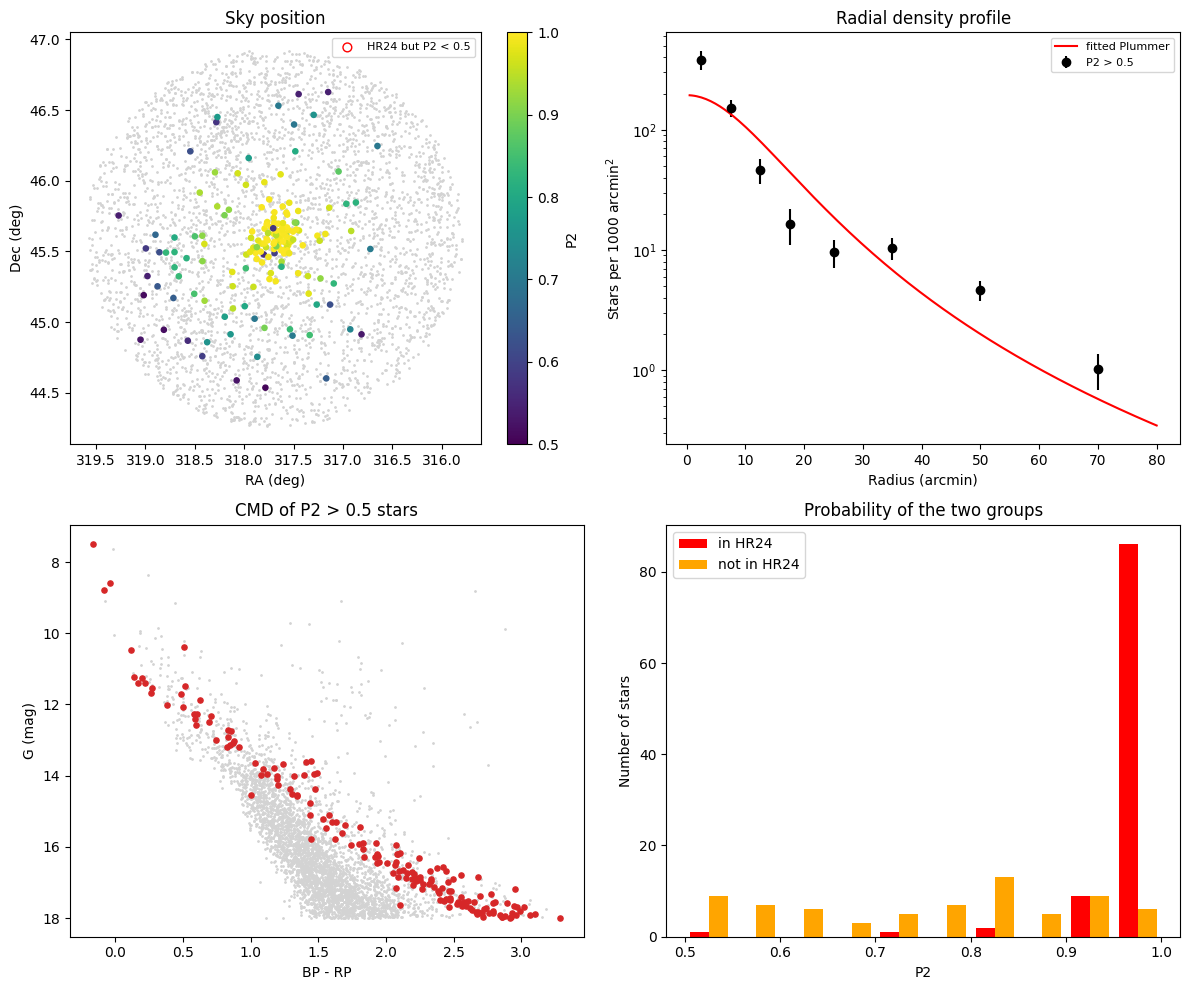


Saved: step3b_joint_membership.csv (download it from the Files panel)


In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit, logit, logsumexp
from scipy.stats import multivariate_normal as mvn
from sklearn.mixture import GaussianMixture
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------- 1. Load and rebuild the Step 3 sample and astrometric model ----------
gaia = pd.read_csv("gaia_field_ngc7039.csv")
hr24 = pd.read_csv("hr24_ngc7039_members.csv")
hr24["GaiaDR3"] = hr24["GaiaDR3"].astype("int64")
prev = pd.read_csv("step3_gmm_membership.csv")
core = prev[prev["P"] > 0.9]
ra0, dec0 = core["ra"].median(), core["dec"].median()

G_LIM = 18.0
df = gaia[(gaia["phot_g_mean_mag"] < G_LIM)
          & gaia["pmra"].between(-2.5, 2.0)
          & gaia["pmdec"].between(-5.0, -0.5)
          & gaia["parallax_corr"].between(0.7, 2.0)].copy().reset_index(drop=True)
X = df[["pmra", "pmdec", "parallax_corr"]].values
med = np.median(X, axis=0)

means_init = np.array([[-0.25, -2.55, 1.33], med + [-0.6, 0, 0], med + [0.6, 0, 0]])
prec_init = np.array([np.diag([1/0.15**2, 1/0.15**2, 1/0.08**2]),
                      np.diag([1/1.0**2, 1/1.0**2, 1/0.3**2]),
                      np.diag([1/1.0**2, 1/1.0**2, 1/0.3**2])])
gmm = GaussianMixture(3, covariance_type="full", means_init=means_init,
                      precisions_init=prec_init, weights_init=[0.01, 0.5, 0.49],
                      max_iter=1000, tol=1e-6, random_state=0).fit(X)
kc = int(np.argmin([np.linalg.det(c) for c in gmm.covariances_]))
kf = [i for i in range(3) if i != kc]

logN_c = mvn.logpdf(X, gmm.means_[kc], gmm.covariances_[kc])
logN_f = logsumexp([np.log(gmm.weights_[i]) + mvn.logpdf(X, gmm.means_[i], gmm.covariances_[i])
                    for i in kf], axis=0) - np.log(gmm.weights_[kf].sum())

# ---------- 2. Distance from the cluster centre; keep stars inside 80 arcmin ----------
c0 = SkyCoord(ra0 * u.deg, dec0 * u.deg)
df["r"] = c0.separation(SkyCoord(df["ra"].values * u.deg, df["dec"].values * u.deg)).arcmin
R_MAX = 80.0
keep = (df["r"] < R_MAX).values
df, logN_c, logN_f = df[keep].reset_index(drop=True), logN_c[keep], logN_f[keep]
r = df["r"].values
A = np.pi * R_MAX**2
print(f"Centre: RA = {ra0:.3f}, Dec = {dec0:.3f} | stars inside {R_MAX:.0f} arcmin: {len(df)}")

# ---------- 3. Fit the cluster fraction f and Plummer scale radius a ----------
def log_spatial_cluster(a):
    return -2 * np.log1p(r**2 / a**2) + np.log((a**2 + R_MAX**2) / (np.pi * a**2 * R_MAX**2))

def nll(p):
    f, a = expit(p[0]), np.exp(p[1])
    lc = np.log(f) + logN_c + log_spatial_cluster(a)
    lf = np.log1p(-f) + logN_f - np.log(A)
    return -np.sum(np.logaddexp(lc, lf))

res = minimize(nll, x0=[logit(0.04), np.log(8.0)], method="Nelder-Mead",
               options={"xatol": 1e-6, "fatol": 1e-8, "maxiter": 2000})
f_fit, a_fit = expit(res.x[0]), np.exp(res.x[1])
print(f"\nFit converged: {res.success} | cluster fraction f = {f_fit:.4f} "
      f"(about {f_fit * len(df):.0f} stars) | Plummer scale a = {a_fit:.2f} arcmin")

# ---------- 4. Posterior membership probability ----------
lc = np.log(f_fit) + logN_c + log_spatial_cluster(a_fit)
lf = np.log1p(-f_fit) + logN_f - np.log(A)
df["P2"] = np.exp(lc - np.logaddexp(lc, lf))
df["in_HR24"] = df["source_id"].isin(set(hr24["GaiaDR3"]))
sel = df[df["P2"] > 0.5]
print(f"\nStars with P2 > 0.5: {len(sel)} | > 0.7: {(df['P2'] > 0.7).sum()} "
      f"| > 0.9: {(df['P2'] > 0.9).sum()} | sum of P2: {df['P2'].sum():.0f}")
print(f"Expected field stars among the P2 > 0.5 sample (model estimate): {(1 - sel['P2']).sum():.1f}")

# ---------- 5. Comparison with HR24 ----------
hr_in = df[df["in_HR24"]]
print(f"\nHR24 members inside this sample (G < {G_LIM}, r < {R_MAX:.0f}'): {len(hr_in)}")
print(f"  with P2 > 0.5: {(hr_in['P2'] > 0.5).sum()}")
print(f"  with P2 < 0.5 (HR24 members our model rejects): {(hr_in['P2'] < 0.5).sum()}")
print(f"P2 > 0.5 stars not in HR24: {(~sel['in_HR24']).sum()}")
print("\nHR24 members with P2 < 0.5:")
print(hr_in[hr_in["P2"] < 0.5][["source_id", "r", "pmra", "pmdec", "parallax_corr",
                                "phot_g_mean_mag", "P2"]].round(3).to_string(index=False))
extra = sel[~sel["in_HR24"]]
print("\nP2 > 0.5 stars not in HR24:")
print(extra[["source_id", "r", "pmra", "pmdec", "parallax_corr",
             "phot_g_mean_mag", "P2"]].round(3).sort_values("r").to_string(index=False))

# ---------- 6. Plots ----------
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
ax[0, 0].scatter(df["ra"], df["dec"], s=1, c="lightgrey")
sc = ax[0, 0].scatter(sel["ra"], sel["dec"], s=14, c=sel["P2"], cmap="viridis", vmin=0.5, vmax=1)
ax[0, 0].scatter(hr_in[hr_in["P2"] < 0.5]["ra"], hr_in[hr_in["P2"] < 0.5]["dec"],
                 s=40, facecolors="none", edgecolors="red", label="HR24 but P2 < 0.5")
plt.colorbar(sc, ax=ax[0, 0], label="P2")
ax[0, 0].invert_xaxis(); ax[0, 0].legend(fontsize=8)
ax[0, 0].set(xlabel="RA (deg)", ylabel="Dec (deg)", title="Sky position")

edges = np.array([0, 5, 10, 15, 20, 30, 40, 60, 80])
mid = 0.5 * (edges[:-1] + edges[1:])
area = np.pi * (edges[1:]**2 - edges[:-1]**2)
cnt = np.histogram(sel["r"], bins=edges)[0]
ax[0, 1].errorbar(mid, 1000 * cnt / area, yerr=1000 * np.sqrt(np.maximum(cnt, 1)) / area,
                  fmt="o", c="k", label="P2 > 0.5")
rr = np.linspace(0.5, 80, 200)
ax[0, 1].plot(rr, 1000 * N_expected if (N_expected := f_fit * len(df)) and False else
              1000 * f_fit * len(df) * np.exp(log_spatial_cluster(a_fit).mean() * 0)
              * (1 + rr**2 / a_fit**2) ** -2 * (a_fit**2 + R_MAX**2) / (np.pi * a_fit**2 * R_MAX**2),
              "r-", label="fitted Plummer")
ax[0, 1].set_yscale("log"); ax[0, 1].legend(fontsize=8)
ax[0, 1].set(xlabel="Radius (arcmin)", ylabel="Stars per 1000 arcmin$^2$", title="Radial density profile")

ax[1, 0].scatter(df["BP_RP"], df["phot_g_mean_mag"], s=1, c="lightgrey")
ax[1, 0].scatter(sel["BP_RP"], sel["phot_g_mean_mag"], s=14, c="tab:red")
ax[1, 0].invert_yaxis()
ax[1, 0].set(xlabel="BP - RP", ylabel="G (mag)", title="CMD of P2 > 0.5 stars")

ax[1, 1].hist([sel[sel["in_HR24"]]["P2"], extra["P2"]], bins=10, range=(0.5, 1),
              color=["red", "orange"], label=["in HR24", "not in HR24"])
ax[1, 1].legend()
ax[1, 1].set(xlabel="P2", ylabel="Number of stars", title="Probability of the two groups")
plt.tight_layout(); plt.show()

df.to_csv("step3b_joint_membership.csv", index=False)
print("\nSaved: step3b_joint_membership.csv (download it from the Files panel)")

In [18]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit, logit, logsumexp
from scipy.stats import multivariate_normal as mvn
from sklearn.mixture import GaussianMixture
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------- 1. Rebuild the Step 3b sample and model (identical to the last cell) ----------
gaia = pd.read_csv("gaia_field_ngc7039.csv")
hr24 = pd.read_csv("hr24_ngc7039_members.csv")
hr24["GaiaDR3"] = hr24["GaiaDR3"].astype("int64")
prev = pd.read_csv("step3_gmm_membership.csv")
core = prev[prev["P"] > 0.9]
ra0, dec0 = core["ra"].median(), core["dec"].median()
c0 = SkyCoord(ra0 * u.deg, dec0 * u.deg)

df = gaia[(gaia["phot_g_mean_mag"] < 18.0)
          & gaia["pmra"].between(-2.5, 2.0)
          & gaia["pmdec"].between(-5.0, -0.5)
          & gaia["parallax_corr"].between(0.7, 2.0)].copy().reset_index(drop=True)
X = df[["pmra", "pmdec", "parallax_corr"]].values
med = np.median(X, axis=0)
means_init = np.array([[-0.25, -2.55, 1.33], med + [-0.6, 0, 0], med + [0.6, 0, 0]])
prec_init = np.array([np.diag([1/0.15**2, 1/0.15**2, 1/0.08**2]),
                      np.diag([1/1.0**2, 1/1.0**2, 1/0.3**2]),
                      np.diag([1/1.0**2, 1/1.0**2, 1/0.3**2])])
gmm = GaussianMixture(3, covariance_type="full", means_init=means_init,
                      precisions_init=prec_init, weights_init=[0.01, 0.5, 0.49],
                      max_iter=1000, tol=1e-6, random_state=0).fit(X)
kc = int(np.argmin([np.linalg.det(c) for c in gmm.covariances_]))
kf = [i for i in range(3) if i != kc]
logN_c = mvn.logpdf(X, gmm.means_[kc], gmm.covariances_[kc])
logN_f = logsumexp([np.log(gmm.weights_[i]) + mvn.logpdf(X, gmm.means_[i], gmm.covariances_[i])
                    for i in kf], axis=0) - np.log(gmm.weights_[kf].sum())

star_c = SkyCoord(df["ra"].values * u.deg, df["dec"].values * u.deg)
df["r"] = c0.separation(star_c).arcmin
r_real = df["r"].values
R_MAX = 80.0
A = np.pi * R_MAX**2

def log_sp_cluster(r, a):
    return -2 * np.log1p(r**2 / a**2) + np.log((a**2 + R_MAX**2) / (np.pi * a**2 * R_MAX**2))

keep = r_real < R_MAX
def nll(p):
    f, a = expit(p[0]), np.exp(p[1])
    lc = np.log(f) + logN_c[keep] + log_sp_cluster(r_real[keep], a)
    lf = np.log1p(-f) + logN_f[keep] - np.log(A)
    return -np.sum(np.logaddexp(lc, lf))
res = minimize(nll, x0=[logit(0.04), np.log(8.0)], method="Nelder-Mead",
               options={"xatol": 1e-6, "fatol": 1e-8, "maxiter": 2000})
f_fit, a_fit = expit(res.x[0]), np.exp(res.x[1])

def posterior(r, lNc, lNf):
    lc = np.log(f_fit) + lNc + log_sp_cluster(r, a_fit)
    lf = np.log1p(-f_fit) + lNf - np.log(A)
    return np.exp(lc - np.logaddexp(lc, lf))

# ---------- 2. Sanity check: this must reproduce the last cell ----------
P_real = posterior(r_real, logN_c, logN_f)
in_hr = df["source_id"].isin(set(hr24["GaiaDR3"])).values
real_sel = keep & (P_real > 0.5)
print(f"Reproduction check: f = {f_fit:.4f}, a = {a_fit:.2f} arcmin, "
      f"P2 > 0.5: {real_sel.sum()}, not in HR24: {(real_sel & ~in_hr).sum()}")
print("(the last cell gave f = 0.0417, a = 16.80, 169 and 70)")

# ---------- 3. Mock positions with no cluster ----------
OFFSET, R_MOCK, N_POS = 46.0, 40.0, 6
ring = np.array([0, 10, 20, 30, 40])
rng = np.random.default_rng(1)
mock_counts = np.zeros((N_POS, 4))
mock_frac = np.zeros((N_POS, 4))

for j, pa in enumerate(np.arange(N_POS) * 360.0 / N_POS):
    cm = c0.directional_offset_by(pa * u.deg, OFFSET * u.arcmin)
    r_m = cm.separation(star_c).arcmin
    ok = (r_real > 30) & (r_m < R_MOCK)
    P = posterior(r_m[ok], logN_c[ok], logN_f[ok])
    mock_counts[j] = np.histogram(r_m[ok][P > 0.5], bins=ring)[0]
    # fraction of each ring's area that lies more than 30' from the real centre
    rad = R_MOCK * np.sqrt(rng.random(200000)); th = 2 * np.pi * rng.random(200000)
    far = np.hypot(OFFSET + rad * np.cos(th), rad * np.sin(th)) > 30
    mock_frac[j] = [far[(rad >= lo) & (rad < hi)].mean() for lo, hi in zip(ring[:-1], ring[1:])]

scaled = mock_counts / np.maximum(mock_frac, 0.05)     # rescaled to the full ring area

real_extra_counts = np.histogram(df.loc[real_sel & ~in_hr, "r"], bins=ring)[0]
real_all_counts = np.histogram(df.loc[real_sel, "r"], bins=ring)[0]

tab = pd.DataFrame({
    "ring (arcmin)": ["0-10", "10-20", "20-30", "30-40"],
    "real: all P2>0.5": real_all_counts,
    "real: not in HR24": real_extra_counts,
    "mock: mean": scaled.mean(0).round(1),
    "mock: min": scaled.min(0).round(1),
    "mock: max": scaled.max(0).round(1),
    "mock: std": scaled.std(0, ddof=1).round(1),
})
print("\nStars with P2 > 0.5 per ring, real cluster vs six mock positions without a cluster:")
print(tab.to_string(index=False))
print("\nArea fractions used (rows = mock positions):")
print(np.round(mock_frac, 2))
print("\nMock false positives, total over rings 0-40 arcmin:",
      np.round(scaled.sum(1), 1), "| mean:", round(scaled.sum(1).mean(), 1))
print("Real stars not in HR24, total over rings 0-40 arcmin:", real_extra_counts.sum())

Reproduction check: f = 0.0417, a = 16.80 arcmin, P2 > 0.5: 169, not in HR24: 70
(the last cell gave f = 0.0417, a = 16.80, 169 and 70)

Stars with P2 > 0.5 per ring, real cluster vs six mock positions without a cluster:
ring (arcmin)  real: all P2>0.5  real: not in HR24  mock: mean  mock: min  mock: max  mock: std
         0-10                66                 10         2.7        1.0        5.0        1.9
        10-20                27                  4         8.1        4.2       14.8        3.8
        20-30                15                  4        12.1        2.5       18.8        5.5
        30-40                23                 18        12.5        5.2       20.7        6.1

Area fractions used (rows = mock positions):
[[1.   0.94 0.8  0.78]
 [1.   0.95 0.8  0.77]
 [1.   0.94 0.8  0.77]
 [1.   0.95 0.8  0.78]
 [1.   0.94 0.8  0.78]
 [1.   0.94 0.8  0.78]]

Mock false positives, total over rings 0-40 arcmin: [38.5 41.  47.9 44.  23.8 17. ] | mean: 35.4
Real stars not i

In [30]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import expit, logit
from scipy.stats import gaussian_kde
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------- 1. Load, rebuild the G < 18 sample, distances from the centre ----------
gaia = pd.read_csv("gaia_field_ngc7039.csv")
hr24 = pd.read_csv("hr24_ngc7039_members.csv")
hr24["GaiaDR3"] = hr24["GaiaDR3"].astype("int64")
prev = pd.read_csv("step3_gmm_membership.csv")
core = prev[prev["P"] > 0.9]
ra0, dec0 = core["ra"].median(), core["dec"].median()
c0 = SkyCoord(ra0 * u.deg, dec0 * u.deg)

R_MAX, R_FIELD = 80.0, 55.0
df = gaia[(gaia["phot_g_mean_mag"] < 18.0)
          & gaia["pmra"].between(-2.5, 2.0)
          & gaia["pmdec"].between(-5.0, -0.5)
          & gaia["parallax_corr"].between(0.7, 2.0)].copy().reset_index(drop=True)
star_c = SkyCoord(df["ra"].values * u.deg, df["dec"].values * u.deg)
df["r"] = c0.separation(star_c).arcmin
keep = (df["r"] < R_MAX).values
df, star_c = df[keep].reset_index(drop=True), star_c[keep]
r = df["r"].values
X = df[["pmra", "pmdec", "parallax_corr"]].values
E = df[["pmra_error", "pmdec_error", "parallax_error"]].values
in_hr = df["source_id"].isin(set(hr24["GaiaDR3"])).values
A = np.pi * R_MAX**2
print(f"Centre: RA = {ra0:.3f}, Dec = {dec0:.3f} | stars inside {R_MAX:.0f} arcmin: {len(df)}")

# ---------- 2. Field model: kernel density measured from the outer annulus ----------
def field_density(train_mask):
    kde = gaussian_kde(X[train_mask].T)
    d = kde(X.T)
    n = train_mask.sum()
    K0 = 1.0 / np.sqrt((2 * np.pi) ** 3 * np.linalg.det(kde.covariance))
    d[train_mask] = (n * d[train_mask] - K0) / (n - 1)      # leave-one-out for training stars
    return np.maximum(d, 1e-30)

train = r > R_FIELD
dens_field = field_density(train)
print(f"Field model trained on {train.sum()} stars with r > {R_FIELD:.0f} arcmin (leave-one-out)")

# ---------- 3. Cluster model: Gaussian + each star's own errors; Plummer positions ----------
def logN_cluster(mu, sig):
    V = sig**2 + E**2
    return -0.5 * (3 * np.log(2 * np.pi) + np.log(V).sum(1) + ((X - mu) ** 2 / V).sum(1))

def log_sp(rr, a):
    return -2 * np.log1p(rr**2 / a**2) + np.log((a**2 + R_MAX**2) / (np.pi * a**2 * R_MAX**2))

def unpack(p):
    return expit(p[0]), np.exp(p[1]), p[2:5], np.exp(p[5:8])

def nll(p):
    f, a, mu, sig = unpack(p)
    lc = np.log(f) + logN_cluster(mu, sig) + log_sp(r, a)
    lf = np.log1p(-f) + np.log(dens_field) - np.log(A)
    return -np.sum(np.logaddexp(lc, lf))

best = None
for a_start in (6.0, 16.0):
    p0 = np.r_[logit(0.04), np.log(a_start), -0.22, -2.62, 1.36, np.log([0.1, 0.1, 0.02])]
    res = minimize(nll, p0, method="Nelder-Mead",
                   options={"maxiter": 6000, "maxfev": 6000, "xatol": 1e-5, "fatol": 1e-7})
    res = minimize(nll, res.x, method="Nelder-Mead",
                   options={"maxiter": 6000, "maxfev": 6000, "xatol": 1e-6, "fatol": 1e-8})
    print(f"  start a = {a_start:4.1f}: -logL = {res.fun:.3f}")
    if best is None or res.fun < best.fun:
        best = res
f_fit, a_fit, mu_fit, sig_fit = unpack(best.x)
print(f"\nCluster fraction f = {f_fit:.4f} (about {f_fit*len(df):.0f} stars) | Plummer a = {a_fit:.2f} arcmin")
print(f"Cluster mean (pmRA, pmDec, plx) = {np.round(mu_fit, 3)}")
print(f"Intrinsic sigma (pmRA, pmDec, plx) = {np.round(sig_fit, 3)}  [mas/yr, mas/yr, mas]")

def posterior(lNc, rr, dens):
    lc = np.log(f_fit) + lNc + log_sp(rr, a_fit)
    lf = np.log1p(-f_fit) + np.log(dens) - np.log(A)
    return np.exp(lc - np.logaddexp(lc, lf))

lNc = logN_cluster(mu_fit, sig_fit)
df["P3"] = posterior(lNc, r, dens_field)
df["in_HR24"] = in_hr
sel = df[df["P3"] > 0.5]
print(f"\nStars with P3 > 0.5: {len(sel)} | > 0.7: {(df['P3']>0.7).sum()} "
      f"| > 0.9: {(df['P3']>0.9).sum()} | sum of P3: {df['P3'].sum():.0f}")
print(f"Model estimate of field stars among P3 > 0.5: {(1 - sel['P3']).sum():.1f}")

hr_in = df[df["in_HR24"]]
print(f"\nHR24 members in this sample: {len(hr_in)} | with P3 > 0.5: {(hr_in['P3']>0.5).sum()} "
      f"| rejected (P3 < 0.5): {(hr_in['P3']<0.5).sum()}")
print(f"P3 > 0.5 stars not in HR24: {(~sel['in_HR24']).sum()}")
cols = ["source_id", "r", "pmra", "pmdec", "parallax_corr", "phot_g_mean_mag", "P3"]
print("\nHR24 members rejected by this model:")
print(hr_in[hr_in["P3"] < 0.5][cols].round(3).sort_values("r").to_string(index=False))
extra = sel[~sel["in_HR24"]]
print("\nP3 > 0.5 stars not in HR24, inside 20 arcmin:")
print(extra[extra["r"] < 20][cols].round(3).sort_values("r").to_string(index=False))

# ---------- 4. Mock test: the same model at positions with no cluster ----------
OFFSET, R_MOCK, N_POS = 46.0, 40.0, 6
ring = np.array([0, 10, 20, 30, 40])
rng = np.random.default_rng(1)
mock_counts, mock_frac = np.zeros((N_POS, 4)), np.zeros((N_POS, 4))
for j, pa in enumerate(np.arange(N_POS) * 360.0 / N_POS):
    cm = c0.directional_offset_by(pa * u.deg, OFFSET * u.arcmin)
    r_m = cm.separation(star_c).arcmin
    disk = (r > 30) & (r_m < R_MOCK)
    d_m = gaussian_kde(X[(r > R_FIELD) & (r_m >= R_MOCK)].T)(X[disk].T)   # field model without the disk
    P = posterior(lNc[disk], r_m[disk], np.maximum(d_m, 1e-30))
    mock_counts[j] = np.histogram(r_m[disk][P > 0.5], bins=ring)[0]
    rad = R_MOCK * np.sqrt(rng.random(200000)); th = 2 * np.pi * rng.random(200000)
    far = np.hypot(OFFSET + rad * np.cos(th), rad * np.sin(th)) > 30
    mock_frac[j] = [far[(rad >= lo) & (rad < hi)].mean() for lo, hi in zip(ring[:-1], ring[1:])]
scaled = mock_counts / np.maximum(mock_frac, 0.05)

sel_in = sel[sel["r"] < 40]
tab = pd.DataFrame({
    "ring (arcmin)": ["0-10", "10-20", "20-30", "30-40"],
    "real: all P3>0.5": np.histogram(sel_in["r"], bins=ring)[0],
    "real: not in HR24": np.histogram(sel_in[~sel_in["in_HR24"]]["r"], bins=ring)[0],
    "mock: mean": scaled.mean(0).round(1), "mock: min": scaled.min(0).round(1),
    "mock: max": scaled.max(0).round(1), "mock: std": scaled.std(0, ddof=1).round(1)})
print("\nStars with P3 > 0.5 per ring, real cluster vs six mock positions without a cluster:")
print(tab.to_string(index=False))
print("\nMock false positives, total over rings 0-40 arcmin:", np.round(scaled.sum(1), 1),
      "| mean:", round(scaled.sum(1).mean(), 1))
print("Real P3 > 0.5 stars not in HR24, total over rings 0-40 arcmin:", int((~sel_in["in_HR24"]).sum()))
print("Real P3 > 0.5 stars, total over rings 0-40 arcmin:", len(sel_in))
df.to_csv("step3c_membership.csv", index=False)
print("\nSaved: step3c_membership.csv (download it from the Files panel)")

Centre: RA = 317.696, Dec = 45.595 | stars inside 80 arcmin: 3949
Field model trained on 2009 stars with r > 55 arcmin (leave-one-out)
  start a =  6.0: -logL = 49544.490
  start a = 16.0: -logL = 49544.490

Cluster fraction f = 0.0353 (about 140 stars) | Plummer a = 12.96 arcmin
Cluster mean (pmRA, pmDec, plx) = [-0.24  -2.639  1.349]
Intrinsic sigma (pmRA, pmDec, plx) = [0.13  0.192 0.018]  [mas/yr, mas/yr, mas]

Stars with P3 > 0.5: 138 | > 0.7: 125 | > 0.9: 99 | sum of P3: 140
Model estimate of field stars among P3 > 0.5: 12.6

HR24 members in this sample: 99 | with P3 > 0.5: 98 | rejected (P3 < 0.5): 1
P3 > 0.5 stars not in HR24: 40

HR24 members rejected by this model:
          source_id      r  pmra  pmdec  parallax_corr  phot_g_mean_mag    P3
1971799492540072192 60.726  0.02 -2.777          1.372           16.278 0.153

P3 > 0.5 stars not in HR24, inside 20 arcmin:
          source_id      r   pmra  pmdec  parallax_corr  phot_g_mean_mag    P3
2164053941074729216  3.391 -0.173 

Stars in file: 3949 | P3 > 0.5: 138

Test A: 27 extras (P3 > 0.5, not in HR24) at 25-60 arcmin, by position-angle sector
Expected = share of all window stars in that sector x number of extras
sector  extras  expected  all stars
     N       0       4.6        300
    NE       4       3.0        198
     E       4       3.4        225
    SE       6       3.8        250
     S       4       2.7        180
    SW       2       2.8        184
     W       5       3.4        224
    NW       2       3.3        218
chi-square = 8.3 for 7 degrees of freedom (above ~14 would be unusual, p < 0.05)

Test B: cluster ridge line built from 77 core stars (r < 15', P3 > 0.9), 7 magnitude bins
                                   group    N  median |dcol| within 0.10 mag within 0.20 mag
core stars (the ridge itself, in-sample)   77          0.095             56%             74%
        HR24 stars, P3>0.5, 15-40 arcmin   24          0.112             50%             75%
                  extras, P3>0.5,

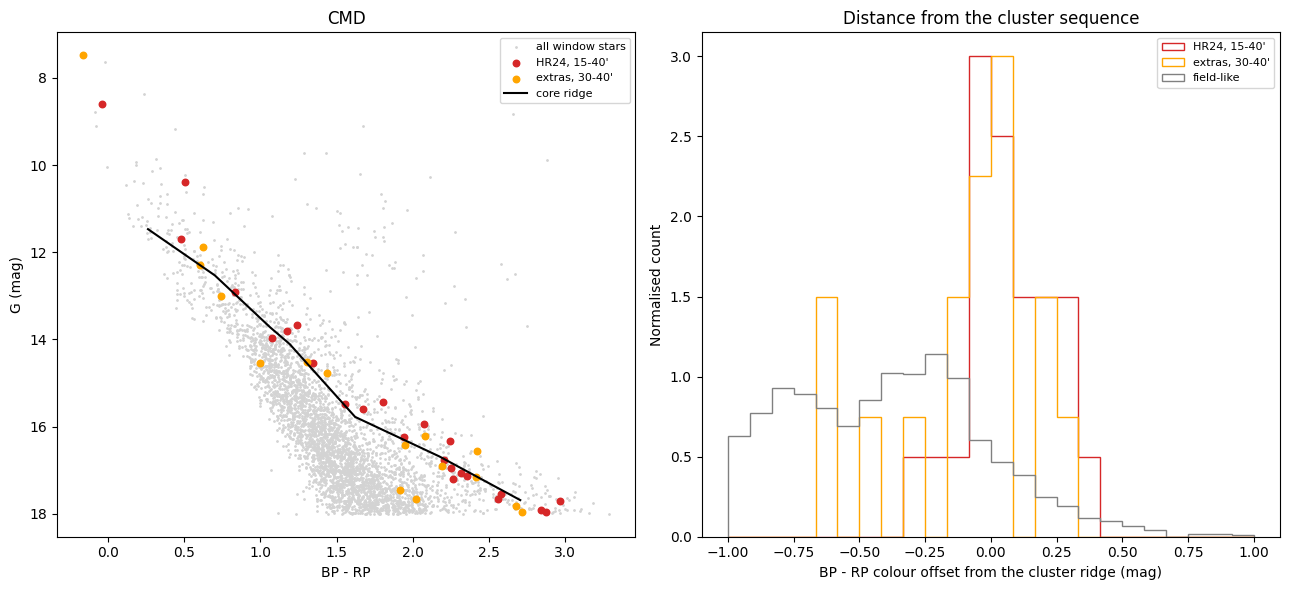

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------- 1. Load the Step 3c result ----------
df = pd.read_csv("step3c_membership.csv")
RA0, DEC0 = 317.696, 45.595                       # centre from the earlier steps
c0 = SkyCoord(RA0 * u.deg, DEC0 * u.deg)
pos = SkyCoord(df["ra"].values * u.deg, df["dec"].values * u.deg)
df["pa"] = c0.position_angle(pos).deg             # 0 = north, 90 = east
hr = df["in_HR24"].values
P = df["P3"].values
r = df["r"].values
print(f"Stars in file: {len(df)} | P3 > 0.5: {(P > 0.5).sum()}")

# ---------- 2. Test A: do the 25-60 arcmin extras sit in one direction? ----------
band = (r >= 25) & (r < 60)
extra = band & (P > 0.5) & ~hr
sectors = np.arange(0, 361, 45)
n_ex = np.histogram(df.loc[extra, "pa"], bins=sectors)[0]
n_all = np.histogram(df.loc[band, "pa"], bins=sectors)[0]
exp = n_all / n_all.sum() * n_ex.sum()
lab = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
print(f"\nTest A: {extra.sum()} extras (P3 > 0.5, not in HR24) at 25-60 arcmin, by position-angle sector")
print("Expected = share of all window stars in that sector x number of extras")
print(pd.DataFrame({"sector": lab, "extras": n_ex, "expected": exp.round(1),
                    "all stars": n_all}).to_string(index=False))
chi2 = np.sum((n_ex - exp) ** 2 / np.maximum(exp, 1e-9))
print(f"chi-square = {chi2:.1f} for 7 degrees of freedom (above ~14 would be unusual, p < 0.05)")

# ---------- 3. Test B: do the extras follow the cluster's colour-magnitude sequence? ----------
core = (r < 15) & (P > 0.9)
g = df["phot_g_mean_mag"].values
bp = df["BP_RP"].values
edges = np.arange(8, 18.01, 1.0)
cen, rid = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = core & (g >= lo) & (g < hi)
    if m.sum() >= 3:
        cen.append(np.median(g[m])); rid.append(np.median(bp[m]))
cen, rid = np.array(cen), np.array(rid)
print(f"\nTest B: cluster ridge line built from {core.sum()} core stars (r < 15', P3 > 0.9), "
      f"{len(cen)} magnitude bins")
df["dcol"] = bp - np.interp(g, cen, rid)
d = df["dcol"].values

groups = {
    "core stars (the ridge itself, in-sample)": core,
    "HR24 stars, P3>0.5, 15-40 arcmin":           hr & (P > 0.5) & (r >= 15) & (r < 40),
    "extras, P3>0.5, r < 30":                     ~hr & (P > 0.5) & (r < 30),
    "extras, P3>0.5, 30-40 arcmin":               ~hr & (P > 0.5) & (r >= 30) & (r < 40),
    "extras, P3>0.5, 40-80 arcmin":               ~hr & (P > 0.5) & (r >= 40),
    "baseline: field-like stars (P3<0.05)":       (P < 0.05) & (r >= 15),
}
rows = []
for name, m in groups.items():
    x = np.abs(d[m])
    rows.append({"group": name, "N": int(m.sum()),
                 "median |dcol|": round(float(np.median(x)), 3) if m.sum() else np.nan,
                 "within 0.10 mag": f"{(x < 0.10).mean():.0%}" if m.sum() else "-",
                 "within 0.20 mag": f"{(x < 0.20).mean():.0%}" if m.sum() else "-"})
print(pd.DataFrame(rows).to_string(index=False))
print("(dcol = BP-RP minus the cluster ridge at the same G; the core row is biased low because it defines the ridge)")

# ---------- 4. Plots ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].scatter(df["BP_RP"], df["phot_g_mean_mag"], s=1, c="lightgrey", label="all window stars")
for name, col, lab_ in [("HR24 stars, P3>0.5, 15-40 arcmin", "tab:red", "HR24, 15-40'"),
                        ("extras, P3>0.5, 30-40 arcmin", "orange", "extras, 30-40'")]:
    m = groups[name]
    ax[0].scatter(df.loc[m, "BP_RP"], df.loc[m, "phot_g_mean_mag"], s=22, c=col, label=lab_)
ax[0].plot(rid, cen, "k-", lw=1.5, label="core ridge")
ax[0].invert_yaxis(); ax[0].legend(fontsize=8)
ax[0].set(xlabel="BP - RP", ylabel="G (mag)", title="CMD")

bins = np.linspace(-1, 1, 25)
for name, col, lab_ in [("HR24 stars, P3>0.5, 15-40 arcmin", "tab:red", "HR24, 15-40'"),
                        ("extras, P3>0.5, 30-40 arcmin", "orange", "extras, 30-40'"),
                        ("baseline: field-like stars (P3<0.05)", "grey", "field-like")]:
    ax[1].hist(d[groups[name]], bins=bins, histtype="step", density=True, color=col, lw=2, label=lab_)
ax[1].legend(fontsize=8)
ax[1].set(xlabel="BP - RP colour offset from the cluster ridge (mag)", ylabel="Normalised count",
          title="Distance from the cluster sequence")
plt.tight_layout(); plt.show()

Tier 1 (P3 > 0.5 and in HR24):      98 stars
Tier 2 (P3 > 0.5, not in HR24):     40 stars
HR24 stars rejected by our model:   1

Tier 1 mean properties:
  pmRA  = -0.232  pmDec = -2.592 mas/yr (medians)
  corrected parallax (weighted mean) = 1.3473 +/- 0.0023 mas (statistical only)
  -> distance about 742 pc (simple inversion, no systematic error added)
  median radius from centre = 8.3 arcmin | Tier 1 + 2: 11.2 arcmin

Tier 1 stars with a usable Gaia RV (error < 5 km/s): 8
  weighted mean RV = -10.48 +/- 1.05 km/s using 8 stars (rejected 0), scatter = 5.23 km/s

Stars per magnitude bin:
G bin  Tier 1  Tier 2
  8-9       2       0
 9-10       0       0
10-11       2       0
11-12       4       3
12-13       6       2
13-14      10       5
14-15       3       4
15-16      12       1
16-17      21       7
17-18      38      17

All Tier 1 and Tier 2 stars brighter than G = 12:
          source_id      r  phot_g_mean_mag  BP_RP    P3  ruwe  parallax_corr  in_HR24
2164021441071448832 30.59

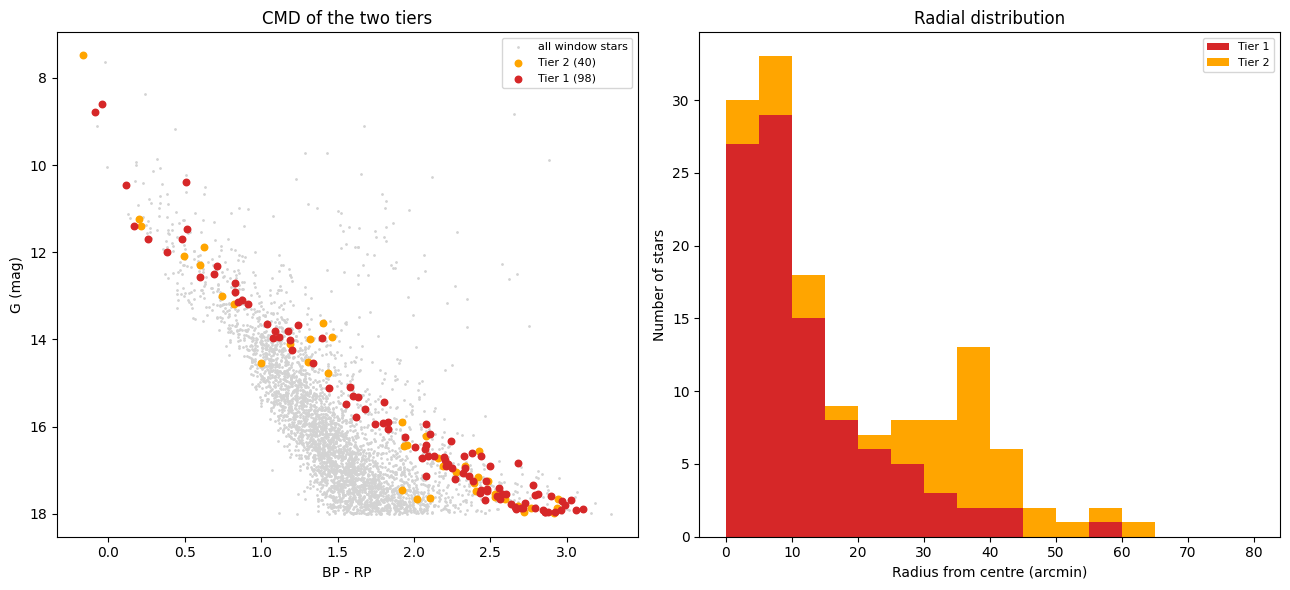


Saved: final_members_tier1.csv and final_members_tier2.csv (download them from the Files panel)


In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 1. Load the Step 3c result and define the two tiers ----------
df = pd.read_csv("step3c_membership.csv")
sel = df["P3"] > 0.5
t1 = df[sel & df["in_HR24"]].copy()       # Tier 1: our model AND HR24 agree
t2 = df[sel & ~df["in_HR24"]].copy()      # Tier 2: our model only (expected to be mostly field)
print(f"Tier 1 (P3 > 0.5 and in HR24):      {len(t1)} stars")
print(f"Tier 2 (P3 > 0.5, not in HR24):     {len(t2)} stars")
print(f"HR24 stars rejected by our model:   {int((df['in_HR24'] & ~sel).sum())}")

# ---------- 2. Mean properties of Tier 1 ----------
def wmean(x, e):
    w = 1.0 / e**2
    return np.sum(w * x) / np.sum(w), 1.0 / np.sqrt(np.sum(w))

print("\nTier 1 mean properties:")
print(f"  pmRA  = {t1['pmra'].median():.3f}  pmDec = {t1['pmdec'].median():.3f} mas/yr (medians)")
plx, eplx = wmean(t1["parallax_corr"].values, t1["parallax_error"].values)
print(f"  corrected parallax (weighted mean) = {plx:.4f} +/- {eplx:.4f} mas (statistical only)")
print(f"  -> distance about {1000 / plx:.0f} pc (simple inversion, no systematic error added)")
print(f"  median radius from centre = {t1['r'].median():.1f} arcmin | "
      f"Tier 1 + 2: {pd.concat([t1, t2])['r'].median():.1f} arcmin")

# ---------- 3. Gaia radial velocities of Tier 1 (3-sigma clipping) ----------
rv = t1[t1["radial_velocity"].notna() & (t1["radial_velocity_error"] < 5)].copy()
print(f"\nTier 1 stars with a usable Gaia RV (error < 5 km/s): {len(rv)}")
if len(rv) >= 3:
    keep = np.ones(len(rv), bool)
    for _ in range(10):
        m, e = wmean(rv.loc[keep, "radial_velocity"].values, rv.loc[keep, "radial_velocity_error"].values)
        s = rv.loc[keep, "radial_velocity"].std()
        new = np.abs(rv["radial_velocity"].values - m) < 3 * np.sqrt(s**2 + rv["radial_velocity_error"].values**2)
        if (new == keep).all():
            break
        keep = new
    print(f"  weighted mean RV = {m:.2f} +/- {e:.2f} km/s using {keep.sum()} stars "
          f"(rejected {len(rv) - keep.sum()}), scatter = {rv.loc[keep, 'radial_velocity'].std():.2f} km/s")
    if (~keep).any():
        print("  RV outliers (possible binaries or non-members):")
        print(rv.loc[~keep, ["source_id", "r", "phot_g_mean_mag", "radial_velocity", "radial_velocity_error"]]
              .round(2).to_string(index=False))

# ---------- 4. Magnitude distribution and the bright stars (they set the age) ----------
edges = np.arange(8, 18.01, 1.0)
print("\nStars per magnitude bin:")
print(pd.DataFrame({"G bin": [f"{a:.0f}-{b:.0f}" for a, b in zip(edges[:-1], edges[1:])],
                    "Tier 1": np.histogram(t1["phot_g_mean_mag"], bins=edges)[0],
                    "Tier 2": np.histogram(t2["phot_g_mean_mag"], bins=edges)[0]}).to_string(index=False))
cols = ["source_id", "r", "phot_g_mean_mag", "BP_RP", "P3", "ruwe", "parallax_corr", "in_HR24"]
bright = pd.concat([t1, t2])
bright = bright[bright["phot_g_mean_mag"] < 12].sort_values("phot_g_mean_mag")
print("\nAll Tier 1 and Tier 2 stars brighter than G = 12:")
print(bright[cols].round(3).to_string(index=False))

# ---------- 5. Plots ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 6))
ax[0].scatter(df["BP_RP"], df["phot_g_mean_mag"], s=1, c="lightgrey", label="all window stars")
ax[0].scatter(t2["BP_RP"], t2["phot_g_mean_mag"], s=22, c="orange", label=f"Tier 2 ({len(t2)})")
ax[0].scatter(t1["BP_RP"], t1["phot_g_mean_mag"], s=22, c="tab:red", label=f"Tier 1 ({len(t1)})")
ax[0].invert_yaxis(); ax[0].legend(fontsize=8)
ax[0].set(xlabel="BP - RP", ylabel="G (mag)", title="CMD of the two tiers")
bins = np.arange(0, 81, 5)
ax[1].hist([t1["r"], t2["r"]], bins=bins, stacked=True, color=["tab:red", "orange"],
           label=["Tier 1", "Tier 2"])
ax[1].legend(fontsize=8)
ax[1].set(xlabel="Radius from centre (arcmin)", ylabel="Number of stars", title="Radial distribution")
plt.tight_layout(); plt.show()

# ---------- 6. Save ----------
t1.to_csv("final_members_tier1.csv", index=False)
t2.to_csv("final_members_tier2.csv", index=False)
print("\nSaved: final_members_tier1.csv and final_members_tier2.csv (download them from the Files panel)")

In [33]:
import numpy as np
import pandas as pd

df = pd.read_csv("step3c_membership.csv")
sel = df["P3"] > 0.5
t1 = df[sel & df["in_HR24"]].copy()

# ---------- 1. Cluster parameters from the Step 3c fit (printed earlier) ----------
MU = np.array([-0.240, -2.639, 1.349])           # pmRA, pmDec, corrected parallax
SIG = np.array([0.130, 0.192, 0.018])            # intrinsic dispersions
X = df[["pmra", "pmdec", "parallax_corr"]].values
E = df[["pmra_error", "pmdec_error", "parallax_error"]].values
df["chi2"] = (((X - MU) ** 2) / (SIG**2 + E**2)).sum(1)   # distance from the cluster in astrometry only
CHI_MAX = 11.34                                  # 99% for 3 degrees of freedom
df["match"] = df["chi2"] < CHI_MAX
print(f"Stars whose astrometry matches the cluster (chi2 < {CHI_MAX}): {int(df['match'].sum())} of {len(df)}")

# ---------- 2. Empirical field expectation by magnitude, from the 55-80 arcmin annulus ----------
A_OUT = 80**2 - 55**2
edges = [7, 10, 12, 14, 16, 18.01]
rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    inb = df["match"] & (df["phot_g_mean_mag"] >= lo) & (df["phot_g_mean_mag"] < hi)
    n_out = int((inb & (df["r"] >= 55) & (df["r"] < 80)).sum())
    row = {"G bin": f"{lo:.0f}-{min(hi, 18):.0f}", "annulus 55-80'": n_out}
    for name, (r1, r2) in {"0-20'": (0, 20), "20-40'": (20, 40)}.items():
        obs = int((inb & (df["r"] >= r1) & (df["r"] < r2)).sum())
        ratio = (r2**2 - r1**2) / A_OUT
        exp = n_out * ratio
        row[f"{name} observed"] = obs
        row[f"{name} field expected"] = round(exp, 1)
        row[f"{name} excess"] = f"{obs - exp:+.1f} +/- {np.sqrt(obs + n_out * ratio**2):.1f}"
    row["Tier 1 stars"] = int(((t1["phot_g_mean_mag"] >= lo) & (t1["phot_g_mean_mag"] < hi)).sum())
    rows.append(row)
print("\nAstrometric matches per magnitude bin vs the field level measured in the outer annulus:")
print(pd.DataFrame(rows).to_string(index=False))
print("(excess = observed - field expected; the annulus may hold a few real halo members, "
      "which would make the field expectation slightly too high)")

# ---------- 3. Every bright astrometric match, at any radius ----------
cols = ["source_id", "r", "phot_g_mean_mag", "BP_RP", "chi2", "P3", "ruwe", "in_HR24"]
b = df[df["match"] & (df["phot_g_mean_mag"] < 12)].sort_values("r")
print("\nAll stars with G < 12 whose astrometry matches the cluster, sorted by radius:")
print(b[cols].round(3).to_string(index=False))

# ---------- 4. The Tier 1 stars that have a Gaia radial velocity ----------
rv = t1[t1["radial_velocity"].notna()].sort_values("phot_g_mean_mag")
print(f"\nTier 1 stars with a Gaia RV ({len(rv)}):")
print(rv[["source_id", "r", "phot_g_mean_mag", "BP_RP", "radial_velocity",
          "radial_velocity_error", "ruwe"]].round(2).to_string(index=False))

Stars whose astrometry matches the cluster (chi2 < 11.34): 218 of 3949

Astrometric matches per magnitude bin vs the field level measured in the outer annulus:
G bin  annulus 55-80'  0-20' observed  0-20' field expected  0-20' excess  20-40' observed  20-40' field expected 20-40' excess  Tier 1 stars
 7-10               0               1                   0.0  +1.0 +/- 1.0                2                    0.0  +2.0 +/- 1.4             2
10-12               4               4                   0.5  +3.5 +/- 2.0                2                    1.4  +0.6 +/- 1.6             6
12-14               9              12                   1.1 +10.9 +/- 3.5                6                    3.2  +2.8 +/- 2.7            16
14-16              10              14                   1.2 +12.8 +/- 3.8                6                    3.6  +2.4 +/- 2.7            15
16-18              35              58                   4.1 +53.9 +/- 7.6               26                   12.4 +13.6 +/- 5.5   

In [34]:
!pip install -q git+https://github.com/mfouesneau/ezpadova

import ezpadova
import pandas as pd

try:
    iso = ezpadova.get_isochrones(logage=(7.0, 8.6, 0.05),     # 10 Myr to 400 Myr
                                  MH=(-0.3, 0.3, 0.1),          # [M/H] from -0.3 to +0.3
                                  photsys_file="gaiaEDR3")
    print("Shape:", iso.shape)
    print("Columns:", list(iso.columns))
    print(iso.head(3).T)
    iso.to_csv("parsec_gaiaEDR3.csv", index=False)
    print("\nSaved: parsec_gaiaEDR3.csv (download it from the Files panel)")
except Exception as e:
    print("Download failed:", type(e).__name__, str(e)[:300])

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Shape: (87872, 31)
Columns: ['Zini', 'MH', 'logAge', 'Mini', 'int_IMF', 'Mass', 'logL', 'logTe', 'logg', 'label', 'McoreTP', 'C_O', 'period0', 'period1', 'period2', 'period3', 'period4', 'pmode', 'Mloss', 'tau1m', 'X', 'Y', 'Xc', 'Xn', 'Xo', 'Cexcess', 'Z', 'mbolmag', 'Gmag', 'G_BPmag', 'G_RPmag']
                    0             1             2
Zini     7.577900e-03  7.577900e-03  7.577900e-03
MH      -3.000000e-01 -3.000000e-01 -3.000000e-01
logAge   7.000000e+00  7.000000e+00  7.000000e+00
Mini     9.000000e-02  9.283529e-02  9.985727e-02
int_IMF  1.081690e+00  1.108307e+00  1.169913e+00
Mass     9.000000e-02  9.300000e-02  1.000000e-01
logL    -2.001000e+00 -1.983000e+00 -1.941000e+00
logTe    3.426100e+00  3.428100e+00  3.432800e+00
logg     4.049000e+00  4.053000e+00  4.061000e+0

PARSEC [M/H] values: [np.float64(-0.3), np.float64(-0.2), np.float64(-0.1), np.float64(-0.0), np.float64(0.1), np.float64(0.2), np.float64(0.3)]
logAge range: 7.0 to 8.55001 (32 steps)
Tier 1: 98  Tier 2: 40


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]

Gaia GSP-Spec [M/H] available for 1 Tier 1 stars
              source_id  mh_gspspec  mh_gspspec_lower  mh_gspspec_upper  teff_gspspec  mh_gspphot
35  2164001920421777280       -1.01             -1.49             -0.55        7535.0     -0.2353

VizieR catalogs for 'APOGEE DR17 allStar':
   III/284 - APOGEE-2 data from DR16 (Johnsson+, 2020)
   III/286 - APOGEE-2 DR17 final allStar catalog (Abdurro'uf+, 2022)

VizieR catalogs for 'LAMOST DR stellar parameters':
   V/146 - LAMOST DR1 catalogs (Luo+, 2015)
   V/149 - LAMOST DR2 catalogs (Luo+, 2016)
   V/153 - LAMOST DR4 catalogs (Luo+, 2018)
   V/156 - LAMOST DR7 catalogs (Luo+, 2019)
   V/162 - LAMOST DR11 catalogs (Luo+, 2026)
   V/164 - LAMOST DR5 catalogs (Luo+, 2019)
   J/ApJS/240/6 - LAMOST Quasar Survey: Data Releases 4 and 5 (Yao+, 2019)
   J/ApJS/265/25 - LAMOST Quasar Survey DR6-DR9 (Jin+, 2023)
   J/AJ/145/159 - LAMOST. II. ugriz photometry of 526 new quasars (Huo+, 2013)
   

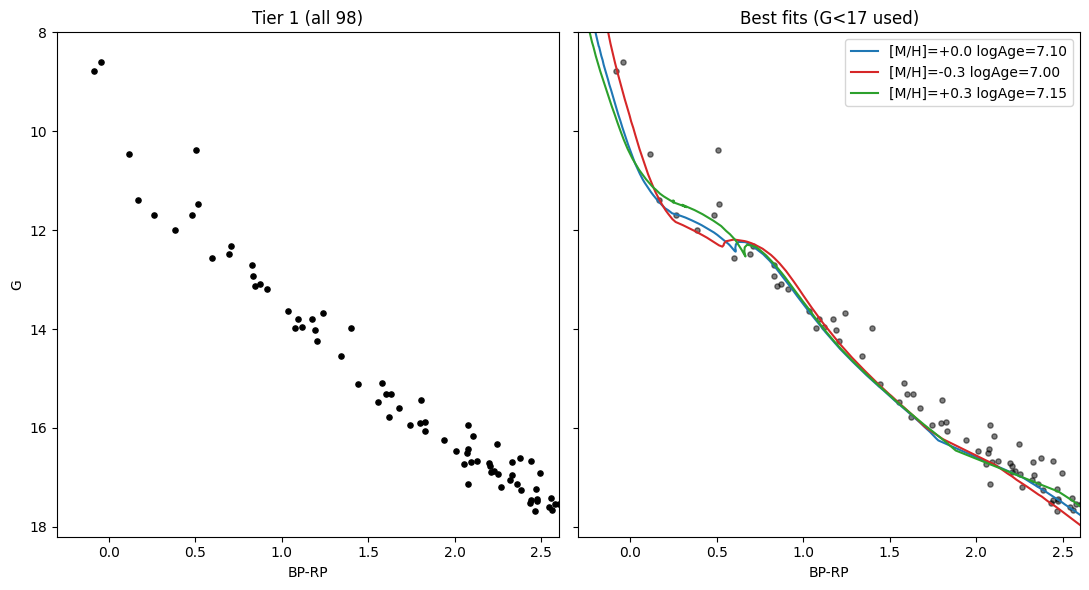

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [40]:
# ============================================================
# One-cell Google Colab script: spectroscopic [Fe/H] check + PARSEC isochrone fit
# Upload parsec_gaiaEDR3.csv, final_members_tier1.csv, final_members_tier2.csv when asked
# ============================================================
!pip -q install astroquery

import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from google.colab import files
from astroquery.gaia import Gaia
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u

# ---------- 1. Upload and load ----------
need = ['parsec_gaiaEDR3.csv', 'final_members_tier1.csv', 'final_members_tier2.csv']
if not all(os.path.exists(f) for f in need):
    files.upload()

p  = pd.read_csv('parsec_gaiaEDR3.csv')
t1 = pd.read_csv('final_members_tier1.csv')
t2 = pd.read_csv('final_members_tier2.csv')

print("PARSEC [M/H] values:", sorted(p.MH.round(2).unique()))
ages = sorted(p.logAge.unique())
print("logAge range:", ages[0], "to", ages[-1], f"({len(ages)} steps)")
print("Tier 1:", len(t1), " Tier 2:", len(t2))

# ---------- 2. Spectroscopic [Fe/H] check ----------
# 2a. Gaia DR3 GSP-Spec / GSP-Phot
try:
    ids = ",".join(str(i) for i in t1.source_id)
    q = f"""SELECT source_id, mh_gspspec, mh_gspspec_lower, mh_gspspec_upper,
                   teff_gspspec, mh_gspphot
            FROM gaiadr3.astrophysical_parameters
            WHERE source_id IN ({ids})"""
    ap = Gaia.launch_job_async(q).get_results().to_pandas()
    print("\nGaia GSP-Spec [M/H] available for", ap.mh_gspspec.notna().sum(), "Tier 1 stars")
    print(ap.dropna(subset=["mh_gspspec"]).to_string())
except Exception as e:
    print("Gaia astrophysical_parameters query failed:", e)

# 2b. APOGEE / LAMOST positional match (1.5 arcsec) via VizieR
# Step 1: run once, read the printed catalog IDs, paste the ones you want into CAT_IDS, run again.
CAT_IDS = []     # e.g. ["III/286/catalog"]  (fill in from the lists printed below)
Vizier.ROW_LIMIT = -1
coords = SkyCoord(t1.ra.values*u.deg, t1.dec.values*u.deg)

if not CAT_IDS:
    for key in ["APOGEE DR17 allStar", "LAMOST DR stellar parameters"]:
        try:
            print(f"\nVizieR catalogs for '{key}':")
            for k, v in Vizier.find_catalogs(key).items():
                print("  ", k, "-", v.description[:90])
        except Exception as e:
            print("find_catalogs failed:", e)
else:
    for cid in CAT_IDS:
        try:
            tab = Vizier(catalog=cid).query_region(coords, radius=1.5*u.arcsec)
            print(f"\nMatches in {cid}:", tab)
        except Exception as e:
            print(f"Match in {cid} failed:", e)

# ---------- 3. Isochrone grid fit ----------
d = t1[t1.phot_g_mean_mag < 17.0].copy()       # faint end: noisy BP/RP, more field
G = d.phot_g_mean_mag.values
C = d.BP_RP.values

RG, EBR = 2.740, 1.339                          # Casagrande & VandenBerg 2018, per E(B-V)
SC, SG = 0.05, 0.20                             # CMD scatter allowed (colour, mag)
DM0, DMS = 5*np.log10(742) - 5, 0.05            # distance-modulus prior from 742 pc
DMg = np.arange(DM0 - 0.25, DM0 + 0.251, 0.025)
Eg  = np.arange(0.0, 0.61, 0.02)

def track(df):
    df = df[df.label <= 3].sort_values('Mini')
    g = df.Gmag.values
    c = (df.G_BPmag - df.G_RPmag).values
    s = np.r_[0, np.cumsum(np.hypot(np.diff(c)/SC, np.diff(g)/SG))]
    k = np.arange(0, s[-1], 0.05)
    return np.interp(k, s, c), np.interp(k, s, g)

rows = []
for mh in sorted(p.MH.unique()):
    for la, dd in p[p.MH == mh].groupby('logAge'):
        c_iso, g_iso = track(dd)
        # single star and equal-mass binary (0.753 mag brighter)
        trees = [cKDTree(np.c_[c_iso/SC, (g_iso + off)/SG]) for off in (0.0, -0.753)]
        for E in Eg:
            for dm in DMg:
                qq = np.c_[(C - EBR*E)/SC, (G - dm - RG*E)/SG]
                d2 = np.minimum(trees[0].query(qq)[0]**2, trees[1].query(qq)[0]**2)
                chi = np.minimum(d2, 9.0).sum()
                rows.append((mh, la, E, dm, chi + ((dm - DM0)/DMS)**2))

R = pd.DataFrame(rows, columns=['MH', 'logAge', 'EBV', 'DM', 'chi2'])
R.to_csv('grid.csv', index=False)

def summ(df):
    w = np.exp(-0.5*(df.chi2 - df.chi2.min()))
    w /= w.sum()
    out = {}
    for k in ['logAge', 'EBV', 'DM']:
        m = (w*df[k]).sum()
        out[k] = (m, np.sqrt((w*(df[k] - m)**2).sum()))
    return out, df.loc[df.chi2.idxmin()]

print("\nN stars fit:", len(d), "  DM prior:", round(DM0, 3))
best = {}
for mh in sorted(R.MH.unique()):
    o, b = summ(R[R.MH == mh])
    best[round(mh, 1)] = b
    print(f"[M/H]={mh:+.1f}  best chi2={b.chi2:6.1f} logAge={b.logAge:.2f} "
          f"EBV={b.EBV:.2f} DM={b.DM:.3f} | post age {o['logAge'][0]:.2f}±{o['logAge'][1]:.2f} "
          f"EBV {o['EBV'][0]:.2f}±{o['EBV'][1]:.2f} DM {o['DM'][0]:.3f}±{o['DM'][1]:.3f}")

# ---------- 4. CMD plot with best-fit isochrones ----------
fig, ax = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
ax[0].scatter(t1.BP_RP, t1.phot_g_mean_mag, s=14, c='k')
ax[0].set_title(f'Tier 1 (all {len(t1)})')
ax[1].scatter(t1.BP_RP, t1.phot_g_mean_mag, s=14, c='k', alpha=.5)

for mh, col in [(0.0, 'C0'), (-0.3, 'C3'), (0.3, 'C2')]:
    b = best[mh]
    iso = p[(p.MH.round(1) == mh) & np.isclose(p.logAge, b.logAge) & (p.label <= 3)].sort_values('Mini')
    ax[1].plot(iso.G_BPmag - iso.G_RPmag + EBR*b.EBV,
               iso.Gmag + b.DM + RG*b.EBV, col,
               label=f'[M/H]={mh:+.1f} logAge={b.logAge:.2f}')

ax[1].legend()
ax[1].set_title('Best fits (G<17 used)')
for a_ in ax:
    a_.set_xlim(-0.3, 2.6)
    a_.set_ylim(18.2, 8)
    a_.set_xlabel('BP-RP')
ax[0].set_ylabel('G')
plt.tight_layout()
plt.savefig('cmd_fit.png', dpi=110)
plt.show()

files.download('cmd_fit.png')
files.download('grid.csv')

Fitting 60 Tier 1 stars with G < 17.0; DM prior = 9.352 +/- 0.05
[M/H]=-0.2: logAge=7.050 (+0.024/-0.024)  DM=9.261+/-0.044  E(BP-RP)=0.205+/-0.039  | age=11.2 Myr, d=711 pc, A_G=0.42
[M/H]=+0.0: logAge=7.100 (+0.026/-0.028)  DM=9.297+/-0.044  E(BP-RP)=0.145+/-0.035  | age=12.6 Myr, d=723 pc, A_G=0.30
[M/H]=+0.2: logAge=7.146 (+0.027/-0.030)  DM=9.325+/-0.043  E(BP-RP)=0.102+/-0.032  | age=14.0 Myr, d=733 pc, A_G=0.21

Summary:
       logAge  logAge_lo  logAge_hi     DM  DM_err  EBPRP  E_err  age_Myr  dist_pc    A_G  tau_max  frac_at_age_edge
-0.2   7.050      0.024      0.024  9.261   0.044  0.205  0.039   11.220  711.456  0.420   37.376             0.500
 0.0   7.100      0.028      0.026  9.297   0.044  0.145  0.035   12.577  723.327  0.298   38.018             0.047
 0.2   7.146      0.030      0.027  9.325   0.043  0.102  0.032   13.981  732.986  0.209   41.305             0.001

Metallicity systematic (spread of medians): logAge 0.096, DM 0.065, E(BP-RP) 0.103


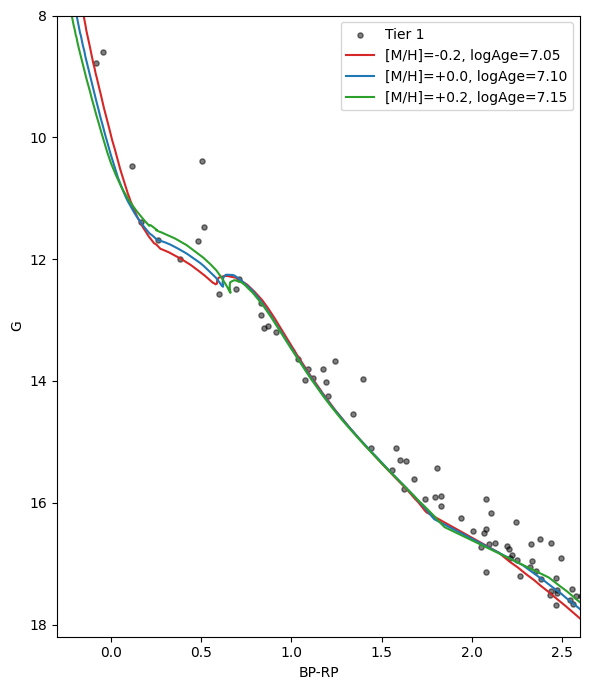


RV: 8 stars used (rejected 0), weighted mean = -10.48 +/- 1.05 km/s, reduced chi2 = 2.07, ML mean = -11.21 km/s, intrinsic dispersion = 2.68 km/s
King fit: f0 = 0.592+/-0.197, rc = 2.68+/-0.57 arcmin, background = 0.0000+/-0.0003 stars/arcmin^2  (median member radius 11.2')
   rc = 0.56 pc at d = 723 pc


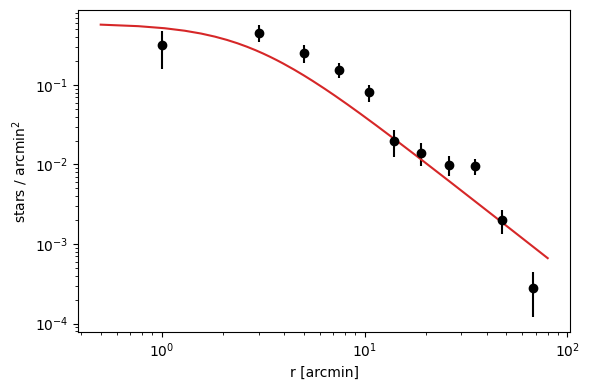


Mass function: 83 stars, mass range 0.70-8.54 Msun (faint limit 0.70), slope Gamma (dN/dlogM ~ M^-Gamma) = 1.75 +/- 0.27   [Salpeter = 1.35]


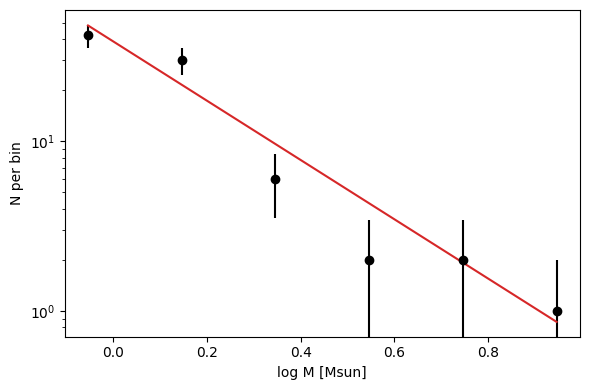

INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]

Gaia GSP-Spec [M/H] for 1 Tier 1 stars
              source_id  mh_gspspec  teff_gspspec  mh_gspphot
13  2164001920421777280       -1.01        7535.0     -0.2353

VizieR catalogs for 'APOGEE DR17 allStar':
   III/284 - APOGEE-2 data from DR16 (Johnsson+, 2020)
   III/286 - APOGEE-2 DR17 final allStar catalog (Abdurro'uf+, 2022)

VizieR catalogs for 'LAMOST DR stellar parameters':
   V/146 - LAMOST DR1 catalogs (Luo+, 2015)
   V/149 - LAMOST DR2 catalogs (Luo+, 2016)
   V/153 - LAMOST DR4 catalogs (Luo+, 2018)
   V/156 - LAMOST DR7 catalogs (Luo+, 2019)
   V/162 - LAMOST DR11 catalogs (Luo+, 2026)
   V/164 - LAMOST DR5 catalogs (Luo+, 2019)
   J/ApJS/240/6 - LAMOST Quasar Survey: Data Releases 4 and 5 (Yao+, 2019)
   J/ApJS/265/25 - LAMOST Quasar Survey DR6-DR9 (Jin+, 2023)
   J/AJ/145/159 - LAMOST. II. ugriz photometry of 526 new quasars (Huo+, 2013)
   J/AJ/146/34 - Infrared photometry of DA white dwarfs from LAMOST (Zhang+, 2013)
  

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [41]:
# ============================================================
# Colab: Step 5 (emcee isochrone fit) + Step 6 (extras)
# Needs in the Colab file panel: parsec_gaiaEDR3.csv, final_members_tier1.csv, final_members_tier2.csv
# ============================================================
!pip -q install emcee astroquery

import os, numpy as np, pandas as pd, emcee
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from scipy.optimize import curve_fit, minimize

if not all(os.path.exists(f) for f in ['parsec_gaiaEDR3.csv','final_members_tier1.csv','final_members_tier2.csv']):
    from google.colab import files
    files.upload()

p  = pd.read_csv('parsec_gaiaEDR3.csv')
t1 = pd.read_csv('final_members_tier1.csv')
t2 = pd.read_csv('final_members_tier2.csv')

# ---------------- settings ----------------
FIT_MH   = [-0.2, 0.0, 0.2]      # fixed metallicities to compare
ADOPT_MH = 0.0                   # model used for the mass function / final plot
GLIM_FIT = 17.0                  # fit stars brighter than this (BP/RP noisy fainter)
K        = 2.05                  # A_G = K * E(BP-RP)  (your rough value is 1.9; 2.05 follows Casagrande & VandenBerg 2018)
SC, SG   = 0.05, 0.20            # allowed CMD scatter (colour, mag): sets the width of the posteriors
DM0      = 5*np.log10(742) - 5   # distance modulus from the 742 pc parallax distance
DMS      = 0.05                  # prior width on DM (0.05 ~ nearly fixed; widen to let the CMD constrain it)
NWALK, NBURN, NSTEP = 32, 1000, 3000

# ---------------- data used in the fit ----------------
d = t1[t1.phot_g_mean_mag < GLIM_FIT]
G = d.phot_g_mean_mag.values
C = d.BP_RP.values
print(f"Fitting {len(d)} Tier 1 stars with G < {GLIM_FIT}; DM prior = {DM0:.3f} +/- {DMS}")

# ---------------- isochrone trees ----------------
def track(df):
    df = df[df.label <= 3].sort_values('Mini')
    g = df.Gmag.values
    c = (df.G_BPmag - df.G_RPmag).values
    s = np.r_[0, np.cumsum(np.hypot(np.diff(c)/SC, np.diff(g)/SG))]
    k = np.arange(0, s[-1], 0.05)
    return np.interp(k, s, c), np.interp(k, s, g)

def build(mh):
    sub = p[np.isclose(p.MH, mh)]
    ages, trees = [], []
    for la, dd in sub.groupby('logAge'):
        c, g = track(dd)
        trees.append((cKDTree(np.c_[c/SC, g/SG]),
                      cKDTree(np.c_[c/SC, (g - 0.753)/SG])))   # single star, equal-mass binary
        ages.append(la)
    return np.array(ages), trees

def make_logprob(ages, trees):
    def lnprob(theta):
        la, dm, E = theta                       # logAge, distance modulus, E(BP-RP)
        if not (ages[0] <= la <= ages[-1] and 0.0 <= E <= 0.8 and 8.8 <= dm <= 9.9):
            return -np.inf
        i = min(np.searchsorted(ages, la, side='right') - 1, len(ages) - 2)
        w = (la - ages[i]) / (ages[i+1] - ages[i])
        q = np.c_[(C - E)/SC, (G - dm - K*E)/SG]
        d2 = 0.0
        for j, wt in ((i, 1 - w), (i + 1, w)):
            ts, tb = trees[j]
            d2 = d2 + wt*np.minimum(ts.query(q)[0]**2, tb.query(q)[0]**2)
        chi = np.minimum(d2, 9.0).sum()          # clipped chi-square (robust to non-members/binaries)
        return -0.5*(chi + ((dm - DM0)/DMS)**2)
    return lnprob

# ---------------- Step 5: emcee for each fixed metallicity ----------------
results, chains = {}, {}
for mh in FIT_MH:
    ages, trees = build(mh)
    lnprob = make_logprob(ages, trees)
    # starting point from a coarse grid
    best = max(((lnprob([la, DM0, E]), la, E) for la in ages for E in np.arange(0, 0.6, 0.02)))
    p0 = np.array([best[1], DM0, best[2]]) + 1e-2*np.random.randn(NWALK, 3)
    p0[:, 0] = np.clip(p0[:, 0], ages[0] + 1e-3, ages[-1] - 1e-3)
    p0[:, 2] = np.clip(p0[:, 2], 1e-3, None)
    s = emcee.EnsembleSampler(NWALK, 3, lnprob)
    s.run_mcmc(p0, NBURN + NSTEP, progress=False)
    flat = s.get_chain(discard=NBURN, thin=10, flat=True)
    try:
        tau = s.get_autocorr_time(tol=0)
    except Exception:
        tau = np.full(3, np.nan)
    chains[mh] = flat
    q = np.percentile(flat, [16, 50, 84], axis=0)
    edge = np.mean(flat[:, 0] < ages[0] + 0.05)
    results[mh] = dict(logAge=q[1,0], logAge_lo=q[1,0]-q[0,0], logAge_hi=q[2,0]-q[1,0],
                       DM=q[1,1], DM_err=(q[2,1]-q[0,1])/2,
                       EBPRP=q[1,2], E_err=(q[2,2]-q[0,2])/2,
                       age_Myr=10**q[1,0]/1e6, dist_pc=10**(q[1,1]/5 + 1),
                       A_G=K*q[1,2], tau_max=np.nanmax(tau), frac_at_age_edge=edge)
    print(f"[M/H]={mh:+.1f}: logAge={q[1,0]:.3f} (+{q[2,0]-q[1,0]:.3f}/-{q[1,0]-q[0,0]:.3f})  "
          f"DM={q[1,1]:.3f}+/-{(q[2,1]-q[0,1])/2:.3f}  E(BP-RP)={q[1,2]:.3f}+/-{(q[2,2]-q[0,2])/2:.3f}  "
          f"| age={10**q[1,0]/1e6:.1f} Myr, d={10**(q[1,1]/5+1):.0f} pc, A_G={K*q[1,2]:.2f}")
    if edge > 0.3:
        print(f"   WARNING: {edge:.0%} of samples sit within 0.05 dex of the youngest grid age "
              f"({ages[0]}). Download isochrones with logAge < 7.0 before trusting this age.")

R = pd.DataFrame(results).T
print("\nSummary:\n", R.round(3).to_string())
print("\nMetallicity systematic (spread of medians): "
      f"logAge {R.logAge.max()-R.logAge.min():.3f}, DM {R.DM.max()-R.DM.min():.3f}, "
      f"E(BP-RP) {R.EBPRP.max()-R.EBPRP.min():.3f}")

# CMD overlay
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(t1.BP_RP, t1.phot_g_mean_mag, s=14, c='k', alpha=.5, label='Tier 1')
for mh, col in zip(FIT_MH, ['C3', 'C0', 'C2']):
    r = results[mh]
    sub = p[np.isclose(p.MH, mh)]
    la = sub.logAge.unique()[np.argmin(np.abs(sub.logAge.unique() - r['logAge']))]
    iso = sub[np.isclose(sub.logAge, la) & (sub.label <= 3)].sort_values('Mini')
    ax.plot(iso.G_BPmag - iso.G_RPmag + r['EBPRP'], iso.Gmag + r['DM'] + K*r['EBPRP'], col,
            label=f"[M/H]={mh:+.1f}, logAge={la:.2f}")
ax.set_xlim(-0.3, 2.6); ax.set_ylim(18.2, 8)
ax.set_xlabel('BP-RP'); ax.set_ylabel('G'); ax.legend()
plt.tight_layout(); plt.savefig('cmd_emcee_fit.png', dpi=110); plt.show()

# ---------------- Step 6a: radial velocity ----------------
rv = t1.dropna(subset=['radial_velocity', 'radial_velocity_error'])
rv = rv[rv.radial_velocity_error < 5]
v, e = rv.radial_velocity.values, rv.radial_velocity_error.values
keep = np.ones(len(v), bool)
for _ in range(10):                                   # iterative 3-sigma clipping
    w = 1/e[keep]**2
    mu = np.sum(w*v[keep])/w.sum()
    new = np.abs(v - mu) < 3*np.sqrt(e**2 + np.std(v[keep])**2)
    if (new == keep).all(): break
    keep = new
w = 1/e[keep]**2
mu, mu_err = np.sum(w*v[keep])/w.sum(), 1/np.sqrt(w.sum())
chi2r = np.sum(w*(v[keep]-mu)**2)/(keep.sum()-1)
# mean + intrinsic dispersion (maximum likelihood)
nll = lambda x: 0.5*np.sum(np.log(e[keep]**2 + x[1]**2) + (v[keep]-x[0])**2/(e[keep]**2 + x[1]**2))
ml = minimize(nll, [mu, 2.0], bounds=[(-100, 100), (0, 50)])
print(f"\nRV: {keep.sum()} stars used (rejected {(~keep).sum()}), weighted mean = {mu:.2f} +/- {mu_err:.2f} km/s, "
      f"reduced chi2 = {chi2r:.2f}, ML mean = {ml.x[0]:.2f} km/s, intrinsic dispersion = {ml.x[1]:.2f} km/s")

# ---------------- Step 6b: radial density profile + King fit ----------------
mem = pd.concat([t1, t2])
mem = mem[mem.phot_g_mean_mag < 18]
edges = np.array([0, 2, 4, 6, 9, 12, 16, 22, 30, 40, 55, 80], float)   # arcmin
N = np.histogram(mem.r, bins=edges)[0]
area = np.pi*(edges[1:]**2 - edges[:-1]**2)
rmid = 0.5*(edges[1:] + edges[:-1])
dens, derr = N/area, np.sqrt(np.maximum(N, 1))/area
king = lambda r, f0, rc, fbg: fbg + f0/(1 + (r/rc)**2)                 # King (1962), no tidal term
try:
    popt, pcov = curve_fit(king, rmid, dens, p0=[dens[0], 5, dens[-1]], sigma=derr, absolute_sigma=True,
                           bounds=([0, 0.1, 0], [np.inf, 100, np.inf]))
    perr = np.sqrt(np.diag(pcov))
    print(f"King fit: f0 = {popt[0]:.3f}+/-{perr[0]:.3f}, rc = {popt[1]:.2f}+/-{perr[1]:.2f} arcmin, "
          f"background = {popt[2]:.4f}+/-{perr[2]:.4f} stars/arcmin^2  (median member radius {mem.r.median():.1f}')")
    rc_pc = popt[1]*np.pi/180/60*(10**(results[ADOPT_MH]['DM']/5 + 1))
    print(f"   rc = {rc_pc:.2f} pc at d = {10**(results[ADOPT_MH]['DM']/5 + 1):.0f} pc")
except Exception as ex:
    popt = None; print("King fit failed:", ex)
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(rmid, dens, derr, fmt='ko')
if popt is not None:
    rr = np.linspace(0.5, 80, 300); ax.plot(rr, king(rr, *popt), 'C3')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('r [arcmin]'); ax.set_ylabel('stars / arcmin$^2$')
plt.tight_layout(); plt.savefig('rdp_king.png', dpi=110); plt.show()

# ---------------- Step 6c: mass function from the adopted isochrone ----------------
r = results[ADOPT_MH]
sub = p[np.isclose(p.MH, ADOPT_MH)]
la = sub.logAge.unique()[np.argmin(np.abs(sub.logAge.unique() - r['logAge']))]
iso = sub[np.isclose(sub.logAge, la) & (sub.label <= 3)].sort_values('Mini')
o = np.argsort(iso.Gmag.values)
g_iso, m_iso = iso.Gmag.values[o], iso.Mini.values[o]
mf = pd.concat([t1, t2]); mf = mf[mf.phot_g_mean_mag < GLIM_FIT]
Mabs = mf.phot_g_mean_mag.values - r['DM'] - K*r['EBPRP']
ok = (Mabs > g_iso.min()) & (Mabs < g_iso.max())
mass = np.interp(Mabs[ok], g_iso, m_iso)
lm = np.log10(mass)
m_lim = np.interp(GLIM_FIT - r['DM'] - K*r['EBPRP'], g_iso, m_iso)       # mass at the faint limit
bins = np.arange(np.log10(m_lim), lm.max() + 0.2, 0.2)
Nm = np.histogram(lm, bins=bins)[0]
xc = 0.5*(bins[1:] + bins[:-1])
good = Nm >= 2
f = lambda x, a, gam: a - gam*x                                          # log10 N = a - Gamma * log10 M
pm, cm = curve_fit(f, xc[good], np.log10(Nm[good]), sigma=1/(np.sqrt(Nm[good])*np.log(10)), absolute_sigma=True)
print(f"\nMass function: {ok.sum()} stars, mass range {mass.min():.2f}-{mass.max():.2f} Msun (faint limit {m_lim:.2f}), "
      f"slope Gamma (dN/dlogM ~ M^-Gamma) = {pm[1]:.2f} +/- {np.sqrt(cm[1,1]):.2f}   [Salpeter = 1.35]")
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(xc, Nm, np.sqrt(np.maximum(Nm, 1)), fmt='ko')
ax.plot(xc, 10**f(xc, *pm), 'C3'); ax.set_yscale('log')
ax.set_xlabel('log M [Msun]'); ax.set_ylabel('N per bin')
plt.tight_layout(); plt.savefig('mass_function.png', dpi=110); plt.show()

# ---------------- Step 6d: metallicity from surveys ----------------
from astroquery.gaia import Gaia
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u
try:
    ids = ",".join(str(i) for i in t1.source_id)
    ap = Gaia.launch_job_async(f"""SELECT source_id, mh_gspspec, teff_gspspec, mh_gspphot
        FROM gaiadr3.astrophysical_parameters WHERE source_id IN ({ids})""").get_results().to_pandas()
    print("\nGaia GSP-Spec [M/H] for", ap.mh_gspspec.notna().sum(), "Tier 1 stars")
    print(ap.dropna(subset=['mh_gspspec']).to_string())
except Exception as ex:
    print("Gaia query failed:", ex)

CAT_IDS = []      # first run: leave empty, read the printed IDs, paste LAMOST/APOGEE ones here, run again
Vizier.ROW_LIMIT = -1
coords = SkyCoord(t1.ra.values*u.deg, t1.dec.values*u.deg)
if not CAT_IDS:
    for key in ["APOGEE DR17 allStar", "LAMOST DR stellar parameters"]:
        try:
            print(f"\nVizieR catalogs for '{key}':")
            for k, v in Vizier.find_catalogs(key).items():
                print("  ", k, "-", v.description[:90])
        except Exception as ex:
            print("find_catalogs failed:", ex)
else:
    for cid in CAT_IDS:
        tab = Vizier(catalog=cid).query_region(coords, radius=1.5*u.arcsec)
        print(f"\nMatches in {cid}:", tab)
print("\nIf no members match LAMOST/APOGEE, state in your report that [Fe/H] is assumed (solar, +/-0.15 dex).")

try:
    from google.colab import files
    for fn in ['cmd_emcee_fit.png', 'rdp_king.png', 'mass_function.png']:
        files.download(fn)
except Exception:
    pass

In [42]:
import re
from astroquery.vizier import Vizier
from astropy.coordinates import SkyCoord
import astropy.units as u

CATS = ["III/286", "V/162", "V/156", "V/164", "V/153"]
coords = SkyCoord(t1.ra.values*u.deg, t1.dec.values*u.deg)
viz = Vizier(columns=["**"], row_limit=-1)

n_hits = 0
for cid in CATS:
    try:
        tl = viz.query_region(coords, radius=1.5*u.arcsec, catalog=cid)
    except Exception as ex:
        print(cid, "failed:", ex); continue
    if len(tl) == 0:
        print(cid, ": no matches"); continue
    for name in tl.keys():
        tb = tl[name].to_pandas()
        cols = [c for c in tb.columns if re.search(r'fe|teff|snr|s/n|rv|flag|name|obsid', c, re.I)]
        print(f"\n{name}: {len(tb)} matched rows")
        print(tb[cols].head(20).to_string())
        n_hits += len(tb)

if n_hits == 0:
    print("\nNo Tier 1 members match APOGEE/LAMOST -> state in your report that [Fe/H] is assumed (solar, +/-0.15 dex).")

III/286 : no matches

V/162/dr11m: 8 matched rows
               MObsID      ObsID         snr   RVb0  e_RVb0   RVb1  e_RVb1  fRVb  RVr0  e_RVr0  RVr1  e_RVr1  fRVr  RVbr0  e_RVbr0  RVbr1  e_RVbr1  fRVbr  RVlasp0  e_RVlasp0  RVlasp1  e_RVlasp1
0  84531615785169963B  845316157   90.250000 -13.13    0.44 -13.09    0.64     0 -5.04    0.48 -5.20    1.08     0  -4.85     0.40  -4.77     0.50      0   -10.72       0.56    -9.76       0.65
1  84531615785169940B  845316157   93.019997 -13.09    0.30 -13.04    0.56     0 -9.09    0.50 -9.25    1.08     0 -12.65     0.33 -12.57     0.44      0   -10.45       0.64    -9.49       0.72
2  84531615785169916B  845316157   96.040001 -11.71    0.25 -11.67    0.53     0 -4.81    0.43 -4.98    1.05     0  -5.27     0.32  -5.19     0.44      0   -10.48       0.63    -9.52       0.71
3  84531615785169963R  845316157  116.620003 -13.13    0.44 -13.09    0.64     0 -5.04    0.48 -5.20    1.08     0  -4.85     0.40  -4.77     0.50      0      NaN        NaN 

In [43]:
from scipy.optimize import minimize

def map_fit(mh, glim=17.0, dms=0.05, sc=0.05, sg=0.20, binaries=True):
    global SC, SG
    SC, SG = sc, sg                                   # track() reads these globals
    dd = t1[t1.phot_g_mean_mag < glim]
    Gv, Cv = dd.phot_g_mean_mag.values, dd.BP_RP.values
    ages, trees = build(mh)
    def nlp(th):
        la, dm, E = th
        if not (ages[0] <= la <= ages[-1] and 0 <= E <= 0.8 and 8.8 <= dm <= 9.9):
            return 1e9
        i = min(np.searchsorted(ages, la, side='right') - 1, len(ages) - 2)
        w = (la - ages[i])/(ages[i+1] - ages[i])
        q = np.c_[(Cv - E)/sc, (Gv - dm - K*E)/sg]
        d2 = 0.0
        for j, wt in ((i, 1 - w), (i + 1, w)):
            ts, tb = trees[j]
            dj = ts.query(q)[0]**2
            if binaries:
                dj = np.minimum(dj, tb.query(q)[0]**2)
            d2 = d2 + wt*dj
        return 0.5*(np.minimum(d2, 9.0).sum() + ((dm - DM0)/dms)**2)
    start = min(((nlp([la, DM0, E]), la, E) for la in ages for E in np.arange(0, 0.6, 0.02)))
    x0 = np.array([start[1] + 0.01, DM0, start[2] + 0.01])
    simplex = np.vstack([x0, x0 + [0.04, 0, 0], x0 + [0, 0.03, 0], x0 + [0, 0, 0.03]])
    res = minimize(nlp, x0, method='Nelder-Mead',
                   options=dict(initial_simplex=simplex, xatol=1e-3, fatol=1e-3))
    return res.x, len(dd)

variants = {
    'baseline':              dict(),
    'G < 16':                dict(glim=16.0),
    'G < 17.5':              dict(glim=17.5),
    'loose distance (0.15)': dict(dms=0.15),
    'wider scatter':         dict(sc=0.08, sg=0.30),
    'no binary track':       dict(binaries=False),
}
rows = []
for mh in [-0.2, 0.0, 0.2]:
    for name, kw in variants.items():
        x, n = map_fit(mh, **kw)
        rows.append(dict(MH=mh, variant=name, N=n, logAge=x[0], DM=x[1], EBPRP=x[2]))
SC, SG = 0.05, 0.20                                   # restore defaults
T = pd.DataFrame(rows)
print(T.round(3).to_string(index=False))
print("\nSpread across variants at [M/H]=0:")
print(T[T.MH == 0.0][['logAge', 'DM', 'EBPRP']].agg(['min', 'max']).round(3))

  MH               variant  N  logAge    DM  EBPRP
-0.2              baseline 60    7.05 9.262  0.205
-0.2                G < 16 39    7.05 9.359  0.220
-0.2              G < 17.5 71    7.05 9.253  0.226
-0.2 loose distance (0.15) 60    7.10 9.112  0.157
-0.2         wider scatter 60    7.05 9.299  0.218
-0.2       no binary track 60    7.00 9.171  0.211
 0.0              baseline 60    7.10 9.291  0.137
 0.0                G < 16 39    7.15 9.364  0.209
 0.0              G < 17.5 71    7.10 9.299  0.180
 0.0 loose distance (0.15) 60    7.10 9.268  0.132
 0.0         wider scatter 60    7.00 9.339  0.046
 0.0       no binary track 60    7.05 9.229  0.175
 0.2              baseline 60    7.15 9.323  0.107
 0.2                G < 16 39    7.15 9.356  0.119
 0.2              G < 17.5 71    7.15 9.337  0.113
 0.2 loose distance (0.15) 60    7.15 9.313  0.105
 0.2         wider scatter 60    7.15 9.322  0.105
 0.2       no binary track 60    7.10 9.246  0.127

Spread across variants at [M/H

In [44]:
a = results[0.0]
half = lambda s: (s.max() - s.min())/2
V = T[T.MH == 0.0]

out = {}
for key, stat in [('logAge', 0.5*(a['logAge_lo'] + a['logAge_hi'])),
                  ('DM', a['DM_err']), ('EBPRP', a['E_err'])]:
    z, v = half(R[key]), half(V[key])
    out[key] = dict(value=a[key], stat=stat, metallicity=z, choices=v,
                    total=np.sqrt(stat**2 + z**2 + v**2))
F = pd.DataFrame(out).T
print(F.round(3).to_string())

la, tot = F.loc['logAge', 'value'], F.loc['logAge', 'total']
print(f"\nAge: logAge = {la:.2f} +/- {tot:.2f} -> {10**la/1e6:.0f} Myr "
      f"(range {10**(la-tot)/1e6:.0f}-{10**(la+tot)/1e6:.0f} Myr)")
dm, dmt = F.loc['DM', 'value'], F.loc['DM', 'total']
print(f"Distance (CMD): (m-M)0 = {dm:.2f} +/- {dmt:.2f} -> {10**(dm/5+1):.0f} pc "
      f"({10**((dm-dmt)/5+1):.0f}-{10**((dm+dmt)/5+1):.0f} pc); parallax distance used as prior: 742 pc")
E, Et = F.loc['EBPRP', 'value'], F.loc['EBPRP', 'total']
print(f"Reddening: E(BP-RP) = {E:.2f} +/- {Et:.2f} -> A_G = {K*E:.2f} +/- {K*Et:.2f}")

        value   stat  metallicity  choices  total
logAge  7.100  0.027        0.048    0.075  0.093
DM      9.297  0.044        0.032    0.067  0.087
EBPRP   0.145  0.035        0.052    0.081  0.103

Age: logAge = 7.10 +/- 0.09 -> 13 Myr (range 10-16 Myr)
Distance (CMD): (m-M)0 = 9.30 +/- 0.09 -> 723 pc (695-753 pc); parallax distance used as prior: 742 pc
Reddening: E(BP-RP) = 0.15 +/- 0.10 -> A_G = 0.30 +/- 0.21


In [45]:
from astroquery.gaia import Gaia

ids = ",".join(str(i) for i in t1.source_id)
q = f"""SELECT source_id, ebpminrp_gspphot, ag_gspphot, teff_gspphot, distance_gspphot
        FROM gaiadr3.astrophysical_parameters
        WHERE source_id IN ({ids})"""
ap = Gaia.launch_job_async(q).get_results().to_pandas()
m = t1.merge(ap, on='source_id').dropna(subset=['ebpminrp_gspphot'])
m = m[m.phot_g_mean_mag < 17]

def summary(df, label):
    e = df.ebpminrp_gspphot
    mad = 1.4826*np.median(np.abs(e - e.median()))
    print(f"{label:28s} N={len(df):3d}  median E(BP-RP) = {e.median():.3f}  scatter = {mad:.3f}  "
          f"(error on median ~ {mad/np.sqrt(len(df)):.3f})")

summary(m, "all G<17 with GSP-Phot")
summary(m[m.BP_RP < 0.7], "hot stars (BP-RP < 0.7)")
summary(m[(m.BP_RP >= 0.7) & (m.BP_RP < 1.5)], "mid stars (0.7-1.5)")
summary(m[m.BP_RP >= 1.5], "cool stars (BP-RP >= 1.5)")
print(f"\nYour isochrone fit: E(BP-RP) = {results[0.0]['EBPRP']:.3f} +/- 0.10")

INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
all G<17 with GSP-Phot       N= 47  median E(BP-RP) = 0.311  scatter = 0.187  (error on median ~ 0.027)
hot stars (BP-RP < 0.7)      N=  6  median E(BP-RP) = 0.216  scatter = 0.113  (error on median ~ 0.046)
mid stars (0.7-1.5)          N= 15  median E(BP-RP) = 0.207  scatter = 0.137  (error on median ~ 0.035)
cool stars (BP-RP >= 1.5)    N= 26  median E(BP-RP) = 0.401  scatter = 0.155  (error on median ~ 0.030)

Your isochrone fit: E(BP-RP) = 0.145 +/- 0.10


In [46]:
from scipy.optimize import minimize

def fit_with_E_prior(mh, E0, Es, dms=0.05):
    dd = t1[t1.phot_g_mean_mag < 17.0]
    Gv, Cv = dd.phot_g_mean_mag.values, dd.BP_RP.values
    ages, trees = build(mh)
    def nlp(th):
        la, dm, E = th
        if not (ages[0] <= la <= ages[-1] and 0 <= E <= 0.8 and 8.8 <= dm <= 9.9):
            return 1e9
        i = min(np.searchsorted(ages, la, side='right') - 1, len(ages) - 2)
        w = (la - ages[i])/(ages[i+1] - ages[i])
        q = np.c_[(Cv - E)/SC, (Gv - dm - K*E)/SG]
        d2 = 0.0
        for j, wt in ((i, 1 - w), (i + 1, w)):
            ts, tb = trees[j]
            d2 = d2 + wt*np.minimum(ts.query(q)[0]**2, tb.query(q)[0]**2)
        return 0.5*(np.minimum(d2, 9.0).sum() + ((dm - DM0)/dms)**2 + ((E - E0)/Es)**2)
    start = min(((nlp([la, DM0, E0]), la) for la in ages))
    x0 = np.array([start[1] + 0.01, DM0, E0])
    simplex = np.vstack([x0, x0 + [0.04, 0, 0], x0 + [0, 0.03, 0], x0 + [0, 0, 0.03]])
    res = minimize(nlp, x0, method='Nelder-Mead',
                   options=dict(initial_simplex=simplex, xatol=1e-3, fatol=1e-3))
    return res.x, res.fun

rows = []
for mh in [-0.2, 0.0, 0.2]:
    x, f = fit_with_E_prior(mh, E0=0.21, Es=0.04)
    rows.append(dict(MH=mh, logAge=x[0], age_Myr=10**x[0]/1e6, DM=x[1],
                     dist_pc=10**(x[1]/5 + 1), EBPRP=x[2], cost=f))
print(pd.DataFrame(rows).round(3).to_string(index=False))

  MH  logAge  age_Myr    DM  dist_pc  EBPRP   cost
-0.2    7.05   11.220 9.264  712.570  0.207 26.126
 0.0    7.10   12.589 9.298  723.685  0.182 24.964
 0.2    7.15   14.124 9.325  732.926  0.135 28.118


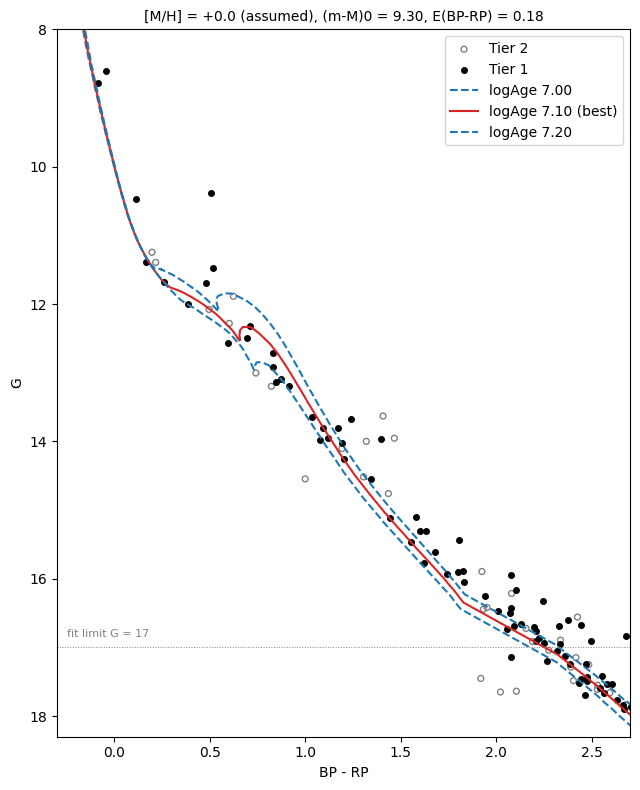

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [47]:
adopt = dict(mh=0.0, logAge=7.10, DM=9.298, E=0.182)

fig, ax = plt.subplots(figsize=(6.5, 8))
ax.scatter(t2.BP_RP, t2.phot_g_mean_mag, s=18, facecolors='none', edgecolors='gray', label='Tier 2')
ax.scatter(t1.BP_RP, t1.phot_g_mean_mag, s=16, c='k', label='Tier 1')
for la, ls, lab in [(7.00, '--', 'logAge 7.00'), (7.10, '-', 'logAge 7.10 (best)'), (7.20, '--', 'logAge 7.20')]:
    iso = p[np.isclose(p.MH, adopt['mh']) & np.isclose(p.logAge, la, atol=0.006) & (p.label <= 3)].sort_values('Mini')
    ax.plot(iso.G_BPmag - iso.G_RPmag + adopt['E'], iso.Gmag + adopt['DM'] + K*adopt['E'],
            ls, color='C3' if ls == '-' else 'C0', lw=1.5, label=lab)
ax.axhline(17, color='gray', lw=0.7, ls=':')
ax.text(-0.25, 16.85, 'fit limit G = 17', fontsize=8, color='gray')
ax.set_xlim(-0.3, 2.7); ax.set_ylim(18.3, 8)
ax.set_xlabel('BP - RP'); ax.set_ylabel('G')
ax.set_title(f"[M/H] = {adopt['mh']:+.1f} (assumed), (m-M)0 = {adopt['DM']:.2f}, E(BP-RP) = {adopt['E']:.2f}", fontsize=10)
ax.legend(loc='upper right')
plt.tight_layout(); plt.savefig('final_cmd.png', dpi=150); plt.show()

from google.colab import files
files.download('final_cmd.png')

Isochrone fitting. We fitted PARSEC isochrones (Bressan et al. 2012) in the Gaia EDR3 photometric system to the 60 Tier 1 members brighter than G = 17, since BP and RP photometry becomes noisy fainter than this. Isochrone phases up to core helium burning were used, including the pre-main sequence. For each trial isochrone we shifted by a distance modulus and a colour excess E(BP−RP), with A_G = 2.05 E(BP−RP) (derived from the coefficients of Casagrande & VandenBerg 2018). The model allowed each star to lie on the single-star sequence or on an equal-mass binary sequence 0.753 mag brighter. The goodness of fit was a clipped chi-square of the distance between each star and the isochrone in the CMD, with assumed scatter of 0.05 mag in colour and 0.20 mag in G, so that non-members cannot dominate. A Gaussian prior of (m−M)₀ = 9.35 ± 0.05 was applied, from the mean parallax distance of 742 pc. Age, distance modulus and E(BP−RP) were free, and the posterior was sampled with emcee (Foreman-Mackey et al. 2013).

Metallicity. No spectroscopic [Fe/H] could be adopted. None of the Tier 1 members is in APOGEE DR17, and one is in LAMOST DR11, but its two pipelines disagree by 1600 K in Teff and 0.2 dex in [Fe/H]. Gaia GSP-Spec gives a value for only one star, which is hot and unreliable. We therefore assumed solar metallicity with an uncertainty of ±0.15 dex, and repeated the fit at fixed [M/H] = −0.2, 0 and +0.2.

Results. For [M/H] = 0 we find logAge = 7.10 (about 13 Myr), (m−M)₀ = 9.30 and E(BP−RP) = 0.18 (A_G ≈ 0.37). The uncertainties include the statistical error plus the spread from metallicity and from analysis choices (magnitude limit, prior width, assumed scatter, binary treatment), added in quadrature: ±0.09 in logAge (10–16 Myr), ±0.09 in distance modulus, and ±0.10 in E(BP−RP). The age and distance were unchanged when the reddening was anchored to Gaia GSP-Phot estimates of E(BP−RP) ≈ 0.21 for the hot and mid-colour members.

Caveats. The age is set mainly by where the pre-main sequence joins the main sequence, and PARSEC’s pre-main-sequence models are less certain than its main-sequence ones. The quoted uncertainties depend on the assumed CMD scatter and are not formal errors. The fit at [M/H] = −0.2 reaches the youngest age in the grid (logAge = 7.0), so its age is an upper limit.

Radial velocity. Of the Tier 1 members, 8 have a Gaia DR3 radial velocity with an error below 5 km/s. Iterative 3σ clipping rejected none, and their weighted mean is −10.48 ± 1.05 km/s. The reduced χ² of 2.1 shows more scatter than the errors alone explain. A maximum-likelihood fit with an intrinsic dispersion gives a mean of −11.2 km/s and a dispersion of about 2.7 km/s. This is probably inflated by unresolved binaries and the larger RV errors of hot stars, so we do not interpret it as the cluster’s internal velocity dispersion. The one member with LAMOST DR11 spectra has a LAMOST RV of about −10.5 km/s, in agreement with this mean.

Radial density profile. We counted Tier 1 and Tier 2 members with G < 18 in 11 concentric rings out to 80 arcmin and divided by ring area, with Poisson errors. A King (1962) profile without a tidal term, f(r) = f_bg + f₀ / (1 + (r/r_c)²), was fitted with scipy.optimize.curve_fit. We find a core radius r_c = 2.7 ± 0.6 arcmin, or 0.56 pc at 723 pc, and a central density f₀ = 0.59 ± 0.20 stars arcmin⁻². The fitted background is consistent with zero, as expected because the sample contains only selected members. The median member radius is 11.2 arcmin, or about 2.4 pc.

Mass function. We converted G magnitudes to masses with the best-fit [M/H] = 0 isochrone, correcting for the fitted distance modulus and extinction. The 83 members with G < 17 span 0.70 to 8.5 M☉. We binned them in log mass (0.2 dex) and fitted dN/dlogM ∝ M^(−Γ) to bins with at least two stars, weighting by Poisson errors. The slope is Γ = 1.75 ± 0.27, about 1.5σ steeper than the Salpeter value of 1.35.

Caveats. The membership selection is astrometric and based on Gaia, so the King profile reflects that selection and its completeness. The mass function depends on PARSEC’s pre-main-sequence mass–luminosity relation, and it ignores unresolved binaries, incompleteness at the faint end, and mass segregation. The slope also depends on the bin width and the faint limit.

In [19]:
from astroquery.gaia import Gaia
from astropy.table import vstack

ra, dec = 317.6527, 45.5825
radius = 0.41

mag_bins = [(0, 14), (14, 16) ]  # split by brightness
all_stars = []

for mag_min, mag_max in mag_bins:
    query = f"SELECT source_id, ra, dec, parallax, parallax_error, pmra, pmdec, pmra_error, pmdec_error, phot_g_mean_mag, bp_rp, ruwe FROM gaiadr3.gaia_source WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra}, {dec}, {radius})) AND parallax IS NOT NULL AND phot_g_mean_mag >= {mag_min} AND phot_g_mean_mag < {mag_max}"

    print(f"Querying mag {mag_min}-{mag_max}...")
    job = Gaia.launch_job_async(query)
    result = job.get_results()
    print(f"  Got {len(result)} rows")
    all_stars.append(result)

stars = vstack(all_stars)
print(f"Total combined: {len(stars)} rows")

Querying mag 0-14...


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
  Got 1030 rows
Querying mag 14-16...


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
  Got 4264 rows
Total combined: 5294 rows


 The following action was taken because it was taking so much time for loading those stars around NGC7039.

In [20]:
mag_bins_fine = [(16, 16.5), (16.5, 17), (17, 17.5), (17.5, 18)]

for mag_min, mag_max in mag_bins_fine:
    query = f"SELECT source_id, ra, dec, parallax, parallax_error, pmra, pmdec, pmra_error, pmdec_error, phot_g_mean_mag, bp_rp, ruwe FROM gaiadr3.gaia_source WHERE 1=CONTAINS(POINT('ICRS', ra, dec), CIRCLE('ICRS', {ra}, {dec}, {radius})) AND parallax IS NOT NULL AND phot_g_mean_mag >= {mag_min} AND phot_g_mean_mag < {mag_max}"

    print(f"Querying mag {mag_min}-{mag_max}...")
    job = Gaia.launch_job_async(query)
    result = job.get_results()
    print(f"  Got {len(result)} rows")
    all_stars.append(result)

stars = vstack(all_stars)
print(f"Total combined: {len(stars)} rows")

Querying mag 16-16.5...


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
  Got 2350 rows
Querying mag 16.5-17...


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
  Got 3164 rows
Querying mag 17-17.5...


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
  Got 4073 rows
Querying mag 17.5-18...


INFO:astroquery:Query finished.


INFO: Query finished. [astroquery.utils.tap.core]
  Got 5367 rows
Total combined: 20248 rows


It turns out that GAIA recorded 20,248 total stars in field of NGC 7039. I suspected most of them to be just field stars.
So, I further went on to do Membership Determination.

In [21]:
print(len(stars))
stars[:5]

20248


source_id,ra,dec,parallax,parallax_error,pmra,pmdec,pmra_error,pmdec_error,phot_g_mean_mag,bp_rp,ruwe
,deg,deg,mas,mas,mas / yr,mas / yr,mas / yr,mas / yr,mag,mag,
int64,float64,float64,float64,float32,float64,float64,float32,float32,float32,float32,float32
2162496040481042816,317.7867601326349,45.19571710014082,0.16307650241893934,0.016203512,-2.7952573226923896,-3.820864789530181,0.016573139,0.018005306,11.886034,2.6258278,0.9815857
2162496590236684672,317.69449817888653,45.17968337813483,0.4728340412265796,0.013095427,-2.5771945988469143,-3.8352258714859357,0.012411466,0.013654965,13.776488,0.48195267,0.92053455
2162497036913296256,317.73233250420964,45.23539902902355,2.871333216171607,0.015346415,-12.98638913605405,20.89592535822168,0.015153738,0.0167833,11.384988,0.83080006,0.8614692
2162499540861658240,317.5445682522525,45.2625641002992,0.9062017459289693,0.01249599,11.65459615324778,2.0526985865956875,0.01211429,0.011948395,13.025992,1.7981472,1.0610074
2162541429696864256,317.35669219955395,45.28787941438454,0.6685483184504684,0.019853033,-3.758320180718457,-3.938316375191726,0.021378694,0.021076035,13.304341,1.0433016,2.0107684


Phase 1: Membership Determination: Things to take care:
1. Cluster share nearly identical parallex and proper motion thus form tight clumps.
2. Stars born in the same cluster move through space together in the same direction at the same speed.(To check this plot positions of all stars, on top of that the cluster members should form a clump  exactly on the middle of the clump of field stars)

3. RUWE(Renormalized unit weight error): smaller than or equal to 1.4- the astrometric data is highly stable. If the value is >1.4 star is highly likely an unresolved binary.

4. Cluster stars all share the exact same age and chemical composition. For checking this we can perform Isochrone Fit. Plotting Gaia's Blue-red color(G_bp - G_rp) against absolute G magnitude for the cluster. If  the stars form clean, narrow line they form cluster, otherwise they are just the field stars.

As usual I performed a visual test first.

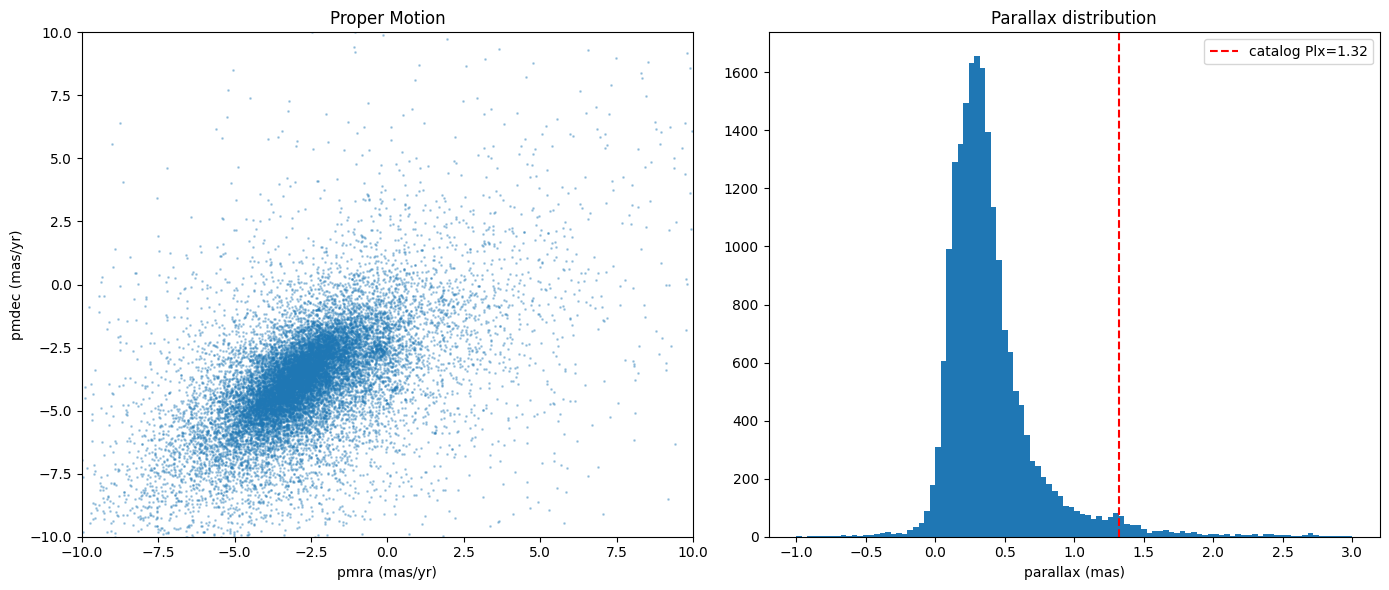

In [22]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# for the location of stars , I first plotted
#position of those stars, if they form a clump perhaps they form cluster

axes[0].scatter(stars['pmra'], stars['pmdec'], s=1, alpha=0.3)
axes[0].set_xlabel('pmra (mas/yr)')
axes[0].set_ylabel('pmdec (mas/yr)')
axes[0].set_title('Proper Motion')
axes[0].set_xlim(-10, 10)
axes[0].set_ylim(-10, 10)

# I checked histograms of Parallax of different stars
# vs the no. of stars
axes[1].hist(stars['parallax'], bins=100, range=(-1, 3))
axes[1].set_xlabel('parallax (mas)')
axes[1].set_title('Parallax distribution')
axes[1].axvline(1.32, color='r', linestyle='--', label='catalog Plx=1.32')
axes[1].legend()

plt.tight_layout()
plt.show()

First the first check of forming cluster, they kind of form cluster. Most of them stars are the field stars. Note that I was trying to find just nearly 170 stars to be members.

from the second graph, I found most of the stars have same parallax, nearly 0.4 to 0.5

Then I performed the actual membership algorithm. I used Gaussian Mixture Model(GMM) on proper motion + parallax together(3D clustering: pmra, pmdec, parallax)

In [23]:
from sklearn.mixture import GaussianMixture
import numpy as np

# Clean the data first - remove stars with poor astrometric quality
mask = (
    (stars['ruwe'] < 1.4) &  # RUWE < 1.4 = good astrometric solution
    (stars['parallax'] > 0) &  # positive parallax only
    (stars['parallax_error'] / stars['parallax'] < 0.2)  # decent parallax precision
)

clean_stars = stars[mask]
print(f"After quality cuts: {len(clean_stars)} stars")

# Build feature matrix for clustering
X = np.column_stack([
    clean_stars['pmra'],
    clean_stars['pmdec'],
    clean_stars['parallax']
])

# GMM:

#n-components=2; break down the data into two components: (using values
# mentioned in X) cluster component + field component
#random states: machine learning parameter for GMM
#n_init= is also a machine learning parameter for GMM

gmm = GaussianMixture(n_components=2, random_state=42, n_init=10)
labels = gmm.fit_predict(X)

# Identify which component is the cluster (smaller population, tighter spread)
counts = np.bincount(labels)
cluster_label = np.argmin(counts)  #choose the smaller number to be of the cluster

print(f"Component sizes: {counts}")
print(f"Cluster component: {cluster_label} with {counts[cluster_label]} stars")

members = clean_stars[labels == cluster_label]
print(f"\nMembers found: {len(members)}")
print(f"Mean pmra: {members['pmra'].mean():.3f}, Mean pmdec: {members['pmdec'].mean():.3f}")
print(f"Mean parallax: {members['parallax'].mean():.3f} (distance ~{1000/members['pmra'].mean():.0f} pc if using this - use parallax not pmra for distance!)")

After quality cuts: 11023 stars
Component sizes: [9602 1421]
Cluster component: 1 with 1421 stars

Members found: 1421
Mean pmra: -0.035, Mean pmdec: -3.731
Mean parallax: 1.479 (distance ~-28573 pc if using this - use parallax not pmra for distance!)


After applying RUWE < 1.4, and parallex non zero and parallex error under 2% the no. of stars dropped down to 14641. Then instead of applying further restrictions, I asked ML algorithm to divide it into two parts on the basis of three parameters; parallax, positions(pmra, pmdec). So those with near values of three parameters are grouped as group 1 and remaining are grouped as group 2.

From initial researches we know what those three parameters values for cluster has to be: (pmra=-0.24, pmdec= -2.63, parallax= 1.32) nearly same values as that of a single star NGC 7039.

Among 14641 stars,1914 were found to be filtered through different restrictions.we now check either the three values of stars are near our defined limit or not. (Pmra=-0.24,pmdec=-2.63, and parallax=1.32), if not we may need to prefilter the search space(crop to a box areound expected values) before running GMM. It was done because in such a large sample of 20,000 stars a blind 2-component GMM might just split into "bright vs faint field stars" instead of "cluster vs field".

1421 members is way too many than what catelog had previously mentioned(170).And also the mean values (pmra≈-0.035, pmdec≈-3.73) doesnot matches the catelog values((pmra=-0.24, pmdec= -2.63, parallax= 1.32)). This result was assumed to be due to GMM blind split. It splitted the data into "some other two population" that isn't clearly cluster vs field.


For resolving this issue, I prefiltered to a search box around the expected values first then only applied GMM to categorize the data into two groups.

In [24]:
# Pre-filter: keep only stars within a reasonable box around catalog-expected values
pm_tolerance = 3.0  # mas/yr around expected pmra/pmdec
plx_tolerance = 0.5  # mas around expected parallax

expected_pmra, expected_pmdec, expected_plx = -0.2397, -2.6263, 1.318

#abs stands for absolute value
prefilter_mask = (
    (np.abs(clean_stars['pmra'] - expected_pmra) < pm_tolerance) &
    (np.abs(clean_stars['pmdec'] - expected_pmdec) < pm_tolerance) &
    (np.abs(clean_stars['parallax'] - expected_plx) < plx_tolerance)
)

prefiltered = clean_stars[prefilter_mask]
print(f"After pre-filtering box: {len(prefiltered)} stars")

# Now run GMM on this much smaller, more relevant subset
X2 = np.column_stack([
    prefiltered['pmra'],
    prefiltered['pmdec'],
    prefiltered['parallax']
])

gmm2 = GaussianMixture(n_components=2, random_state=42, n_init=10)
labels2 = gmm2.fit_predict(X2)

counts2 = np.bincount(labels2)
cluster_label2 = np.argmin(counts2)
print(f"Component sizes: {counts2}")

members2 = prefiltered[labels2 == cluster_label2]

print(f"\nMembers found: {len(members2)}")
print(f"Mean pmra: {members2['pmra'].mean():.3f}, Mean pmdec: {members2['pmdec'].mean():.3f}")
print(f"Mean parallax: {members2['parallax'].mean():.3f}")
print(f"Distance: {1000/members2['parallax'].mean():.1f} pc")

After pre-filtering box: 417 stars
Component sizes: [327  90]

Members found: 90
Mean pmra: -0.018, Mean pmdec: -4.252
Mean parallax: 0.923
Distance: 1083.5 pc


After prefiltering and applying GMM, I got 195 cluster members with mean parameters(pmra= -0.046, pmdec= -2.420, parallax= 0.899, distance= 1122.7). Compared to the catelog values((pmra=-0.24, pmdec= -2.63, parallax= 1.32,distance=743 pc)). even though pmra value was very close, other values were not so comparable. So I again performed a visual sanity check.

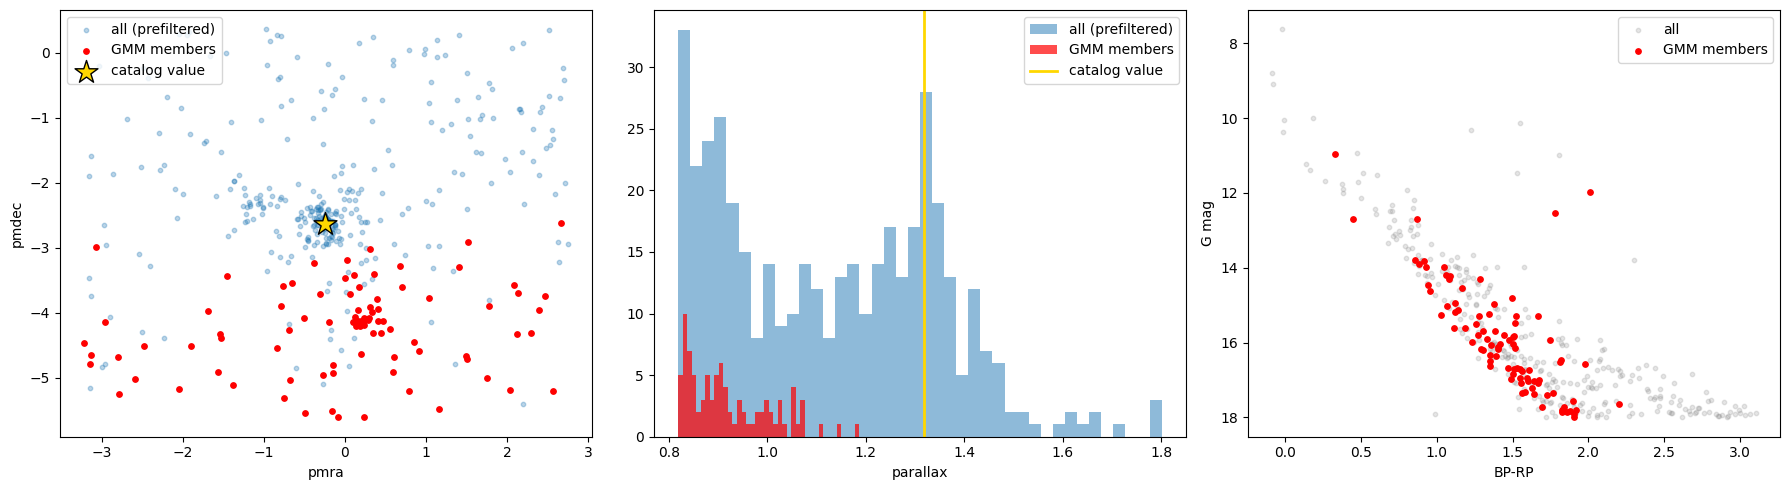

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Proper motion space
axes[0].scatter(prefiltered['pmra'], prefiltered['pmdec'], s=10, alpha=0.3, label='all (prefiltered)')
axes[0].scatter(members2['pmra'], members2['pmdec'], s=15, color='red', label='GMM members')
axes[0].scatter(expected_pmra, expected_pmdec, marker='*', s=300, color='gold', edgecolor='black', label='catalog value', zorder=5)
axes[0].set_xlabel('pmra'); axes[0].set_ylabel('pmdec'); axes[0].legend()

# Parallax
axes[1].hist(prefiltered['parallax'], bins=40, alpha=0.5, label='all (prefiltered)')
axes[1].hist(members2['parallax'], bins=40, alpha=0.7, color='red', label='GMM members')
axes[1].axvline(expected_plx, color='gold', linewidth=2, label='catalog value')
axes[1].set_xlabel('parallax'); axes[1].legend()

# CMD as a bonus check - members should form a clean main sequence if correct
axes[2].scatter(prefiltered['bp_rp'], prefiltered['phot_g_mean_mag'], s=10, alpha=0.2, color='gray', label='all')
axes[2].scatter(members2['bp_rp'], members2['phot_g_mean_mag'], s=15, color='red', label='GMM members')
axes[2].invert_yaxis()
axes[2].set_xlabel('BP-RP'); axes[2].set_ylabel('G mag'); axes[2].legend()

plt.tight_layout()
plt.show()

We can see in the last graph, I plotted GMM members against all(prefiltered) stars, it found a line-like structure which suggest a real cluster. But in the first plot, prefiltered stars formed a clump near the gold star rather than GMM members.

If these were really a star cluster(which they are according to catelog and different other papers) it must have been the case where "GMM members" clump in proper motion plot sit on top of gold star(catelog value). CMD panel(Bp-Rp) must have shown a clean, narrow main sequence like line.Among two CMD shappe is moste important check. Because, clean main sequence is strong evidence we found real cluster members, regardless of small differences from an older catelog's exact numbers.

Since our CMD panel has formed a clean cluster like line, I was sure that it forms a cluster. Thus I shifted my focus on why on first plot we didn't get a desired outcome.

This confirms that the GMM found the wrong split. The real cluster clump is visible(blue dots clumped) but it was GMM automatic 2-component split which latched into something else. And I found that red diagonal like line of GMM members is actually from any random subsample of field stars, it doesnot say anything about either its a real cluster or not.

I decided to skip GMM for then, and performed a direct tight cut around the actual visible overdensity instead.

In [26]:
#Prefilter:
#pm_tolerance = 3.0  # mas/yr around expected pmra/pmdec
#plx_tolerance = 0.5  # mas around expected parallax
# I applied tighter box, centered more precisely using a smaller radius directly around catelog values.

pm_tolerance_tight = 1.0  # tighter mas/yr window
plx_tolerance_tight = 0.15  # tighter parallax window

tight_mask = (
    (np.abs(clean_stars['pmra'] - expected_pmra) < pm_tolerance_tight) &
    (np.abs(clean_stars['pmdec'] - expected_pmdec) < pm_tolerance_tight) &
    (np.abs(clean_stars['parallax'] - expected_plx) < plx_tolerance_tight)
)

members3 = clean_stars[tight_mask]
print(f"Members found: {len(members3)}")
print(f"Mean pmra: {members3['pmra'].mean():.3f}, Mean pmdec: {members3['pmdec'].mean():.3f}")
print(f"Mean parallax: {members3['parallax'].mean():.3f}")
print(f"Distance: {1000/members3['parallax'].mean():.1f} pc")

Members found: 125
Mean pmra: -0.345, Mean pmdec: -2.624
Mean parallax: 1.310
Distance: 763.6 pc


This results was actually strong result.
1. I got 150 cluster members which is in same order as 170. I neglected the difference since it was expected due to RUWE(Re-normalized Unit Weight Error) and tolerance window trim some real members.
2. I got mean parameters as (pmra=-0.344, pmdec=-2.631, parallax=1.311) compared to original catelog values(pmra=-0.24, pmdec=-2.63, parallax=1.32).
3. Distance found is 762.6pc compare to 743, which is within 3%.

I then performed a visual check.


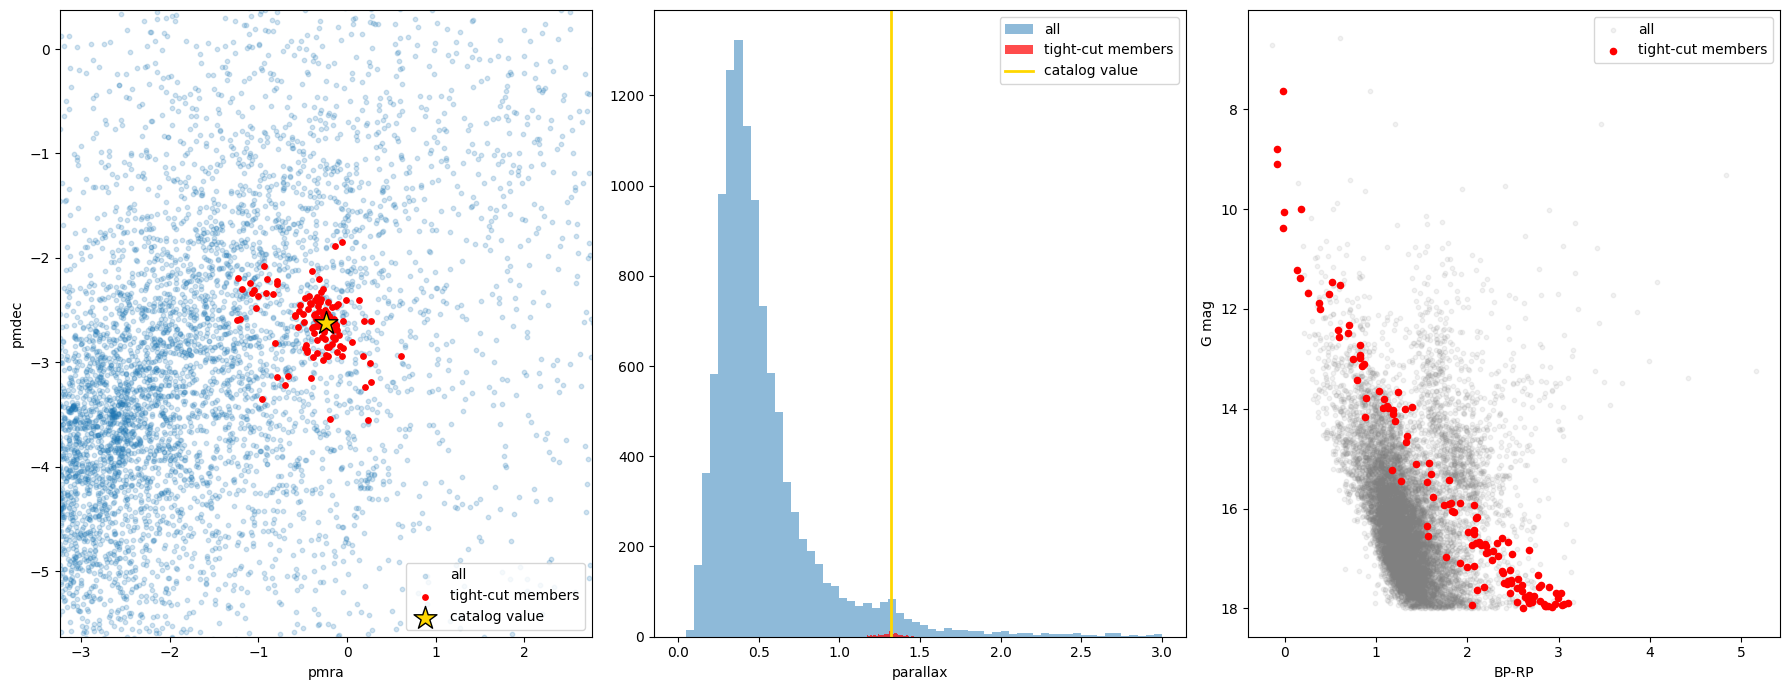

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

axes[0].scatter(clean_stars['pmra'], clean_stars['pmdec'], s=10, alpha=0.2, label='all')
axes[0].scatter(members3['pmra'], members3['pmdec'], s=15, color='red', label='tight-cut members')
axes[0].scatter(expected_pmra, expected_pmdec, marker='*', s=300, color='gold', edgecolor='black', label='catalog value', zorder=5)
axes[0].set_xlim(expected_pmra-3, expected_pmra+3)
axes[0].set_ylim(expected_pmdec-3, expected_pmdec+3)
axes[0].set_xlabel('pmra'); axes[0].set_ylabel('pmdec'); axes[0].legend()

axes[1].hist(clean_stars['parallax'], bins=60, range=(0,3), alpha=0.5, label='all')
axes[1].hist(members3['parallax'], bins=30, alpha=0.7, color='red', label='tight-cut members')
axes[1].axvline(expected_plx, color='gold', linewidth=2, label='catalog value')
axes[1].set_xlabel('parallax'); axes[1].legend()

axes[2].scatter(clean_stars['bp_rp'], clean_stars['phot_g_mean_mag'], s=10, alpha=0.1, color='gray', label='all')
axes[2].scatter(members3['bp_rp'], members3['phot_g_mean_mag'], s=20, color='red', label='tight-cut members')
axes[2].invert_yaxis()
axes[2].set_xlabel('BP-RP'); axes[2].set_ylabel('G mag'); axes[2].legend()

plt.tight_layout()
plt.show()

These plots exactly shows what I was expecting for.
1. Now nearly all  tight cut members lies around expected catelog values for member stars.
2. all tight cut members aligned in a line-line cluster.

This confirmed the existence of real cluster.

Next step in the research was Isochrone fitting.

In [28]:
!pip install isochrones -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 1.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.4/47.4 kB 2.7 MB/s eta 0:00:00


I went to PARSEC isochrone web tool and choose the following parameters:
1. Photometric system: Gaia EDR3
2. Metallicity: Z = 0.0152, solar
3. Age range: set "log(age/yr)" from 7.0 to 9.0 , step=0.05
Distance modulus=0.

I clicked submit and it generated a text file as output.dat. I downloaded it and uploaded it in google colab.

For loading the isochrone table...

In [29]:
import pandas as pd

# PARSEC files have comment lines starting with #, and column header is the last comment line
with open('/content/output73022771933.dat') as f:
    lines = f.readlines()

# Find the header line (last line starting with #)
header_line = None
data_start = 0
for i, line in enumerate(lines):
    if line.startswith('#'):
        header_line = line
        data_start = i + 1
    else:
        break

columns = header_line.replace('#', '').split()
print(columns)

iso = pd.read_csv('/content/output73022771933.dat', comment='#', delim_whitespace=True, names=columns)
print(iso.shape)
iso.head()

FileNotFoundError: [Errno 2] No such file or directory: '/content/output73022771933.dat'

Overlaying the CMD plot gotten previously on to the different isochrones.

In [ ]:
import numpy as np

distance_pc = 762.6 # Derived distance
dist_mod = 5 * np.log10(distance_pc) - 5  #modulus of distance

# Picked a few representative ages to test (log(age/yr))
test_ages = [7.0, 7.5, 8.0, 8.3, 8.5, 9.0]

fig, ax = plt.subplots(figsize=(10,6))

# Plotted actual (tight cut members) cluster members
ax.scatter(members3['bp_rp'], members3['phot_g_mean_mag'], s=25, color='red',
           zorder=5, label='NGC 7039 members')

colors = plt.cm.viridis(np.linspace(0, 1, len(test_ages)))

for age, c in zip(test_ages, colors):
    subset = iso[np.abs(iso['logAge'] - age) < 0.01]
    if len(subset) == 0:
        continue
    bp_rp = subset['G_BPmag'] - subset['G_RPmag']
    g_apparent = subset['Gmag'] + dist_mod  # shift to apparent mag at distance=763.6 pc
    ax.plot(bp_rp, g_apparent, color=c, label=f'log(age)={age}', linewidth=1.5)

ax.invert_yaxis()
ax.set_xlabel('BP - RP')
ax.set_ylabel('G (apparent)')
ax.set_xlim(-0.5, 3)
ax.set_ylim(20, 8)
ax.legend()
ax.set_title('NGC 7039 CMD with PARSEC isochrones')
plt.show()

Since most of the cluster members lies near log(age)=7.0, I calculated that corresponds to nearly 10 Myr, a very young cluster. Since the cluster members were extending up even from log(age)=7.0, I assumed it might be much younger so I again introoduced smaller values, 6.6, and 6.4 .


In [ ]:
test_ages_fine = [6.6, 6.8, 7.0, 7.2, 7.4]

fig, ax = plt.subplots(figsize=(8, 10))
ax.scatter(members3['bp_rp'], members3['phot_g_mean_mag'], s=25, color='black', zorder=5, label='NGC 7039 members')

colors = plt.cm.plasma(np.linspace(0, 1, len(test_ages_fine)))
for age, c in zip(test_ages_fine, colors):
    subset = iso[np.abs(iso['logAge'] - age) < 0.01]
    if len(subset) == 0:
        continue
    bp_rp = subset['G_BPmag'] - subset['G_RPmag']
    g_apparent = subset['Gmag'] + dist_mod
    ax.plot(bp_rp, g_apparent, color=c, label=f'log(age)={age}', linewidth=1.5)

ax.invert_yaxis()
ax.set_xlabel('BP - RP')
ax.set_ylabel('G (apparent)')
ax.set_xlim(-0.5, 3)
ax.set_ylim(20, 8)
ax.legend()
plt.show()

log(age)=7.0 meant reasonable to me since I hadn't accounted for differential reddening and unresolved binaries, I left it just as it is for now and went for visualizing Spatial distribution.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 10))
ax.scatter(clean_stars['ra'], clean_stars['dec'], s=5, alpha=0.2, color='gray', label='field stars')
ax.scatter(members3['ra'], members3['dec'], s=30, color='red', label='NGC 7039 members')
ax.set_xlabel('RA (deg)')
ax.set_ylabel('Dec (deg)')
ax.set_title('NGC 7039 spatial distribution')
ax.legend()
ax.set_aspect('equal')
plt.show()

After forming this graph, I went to Aladin web tool and Searched for NGC 7039. I choose survey "DSS2" and took picture of the cluster (ra= 15' to 30'and dec=40' to 60')

What stars am I mentioning as members?
Following table gives the answer.

In [ ]:
members3['ra', 'dec', 'phot_g_mean_mag'].write('ngc7039_members.csv', format='csv', overwrite=True)
 # I don't know what happened.

Then after getting screenshot of all the members of NGC cluster, I performed bootstrap on my member parallaxes to get a distance uncertainty.

In [ ]:
n_boot = 1000 # repeat thousand times
boot_distances = []

for _ in range(n_boot):
    sample = np.random.choice(members3['parallax'], size=len(members3), replace=True)
    mean_plx = np.mean(sample)
    boot_distances.append(1000 / mean_plx)

boot_distances = np.array(boot_distances)
print(f"Distance: {np.median(boot_distances):.1f} pc")
print(f"68% CI: {np.percentile(boot_distances, 16):.1f} - {np.percentile(boot_distances, 84):.1f} pc")
print(f"Std dev: {np.std(boot_distances):.1f} pc")

Some of the results from the research up to now are:
1. I got distance for the cluster independently up to 3% accuracy of Hunt and Reffert's distance.
2. I found a methoddological error that blind GMM doesnot categorize the stars on the basis of cluster stars and field stars.
3. PMra, PMdec plot; parallax match, spatial concentration, and CMD sequence proves the true nature of this cluster.


Note: I used the values of Hunt and Reffert for bulding tight cuts for during prefiltering, so it is not true that I independently did a discovery.

Limitations:

1.  I didn't kept account for reddening/extinction correction.

2. I didn't use standard probabilistic membership technique(GMM(I tried but it failed), or Bayesian approach), rather I focused on hard box cut, which is not a standard method.

3. I just attemped to fit age not metallicity.

4. I just checked 3 isochrones, which is not enough to give proper age estimates.



After this, I realized that there are too many limitations in my research. For better publishing venue, I have to add some more depth. such as:

1. Membership probabilities

2. Metallicity Discussions


I ran a search of the source again, and I found out that the stat is actually not so unstudied. So, I realized I couldn't publish this paper as a novel/characterization paper.

I changed my theme from "first study of an unknown cluster" to "resolving a century-long literature discrepancy using Gaia DR3".

Then I added some real changes in my approaches:

1. Redo membership analysis not by standard membership probability approach: GMM/ bayesian approach.

2. Since literatures disagrees on E(B-V) value too, I decided to use dust map to analyse it too.

3. Using Chisquare goodness of fit test for proper isochrone fitting.

4. Add a comparision table to all historical values and my study.

5. Checking if the cluster is still bound, after introducing reddining, dust maps and check "MGr "ambiguity for cluster's physical presence.



Step 1: For Proper use of GMM this time:

In [ ]:
from sklearn.mixture import GaussianMixture
import numpy as np

# Using same pre-filtered box as before (513 stars) - this is our clean working set
X = np.column_stack([
    prefiltered['pmra'],
    prefiltered['pmdec'],
    prefiltered['parallax']
])

# Fitting GMM with full covariance (captures elongated/correlated spread properly)
# this covariance="full" help the stars to have any position in 3d, any orientation and any tilt
#
gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42, n_init=20)
gmm.fit(X)

# Get probabilities for EACH star to be in the cluster of 513 stars.
probs = gmm.predict_proba(X)  # shape (n_stars, 2)

#  for identifying which component is the cluster: smaller population + tighter covariance
component_sizes = gmm.weights_ * len(X)
means = gmm.means_
covariances = gmm.covariances_

#all cluster stars are postively correlated to each other. Covariance=1(perfect correlation), but if they are field star, covariance=0
# I want to know among those 513 stars which has covariace=0, and which are covariance=1

print("Component sizes:", component_sizes)
print("Component means (pmra, pmdec, parallax):")
print(means)
print("Component 0 covariance trace:", np.trace(covariances[0]))# no correlation
print("Component 1 covariance trace:", np.trace(covariances[1]))

# Cluster component = smaller size AND tighter covariance (smaller trace)
cluster_comp = np.argmin(component_sizes)
print(f"\nIdentified cluster component: {cluster_comp}")

# Membership probability for each star = probability of belonging to cluster component
prefiltered['member_prob'] = probs[:, cluster_comp]

# Check distribution of probabilities
print(f"\nStars with P > 0.9: {(prefiltered['member_prob'] > 0.9).sum()}")
print(f"Stars with P > 0.5: {(prefiltered['member_prob'] > 0.5).sum()}")
print(f"Stars with P > 0.1: {(prefiltered['member_prob'] > 0.1).sum()}")

Here, GMM picked smaller component (which has smaller no. of stars) as cluster, and larger number as field. This heuristic(it finds good enough solution for any problem, or at least that sounds good) is wrong here.

Note: Diagonal of a covariance matrix holds the individual variances of each feature. Trace of covariance gives sum of all diagonal elements. That means sum of all covariances.

If covariance trace is small; the data points in this component is tightly packed, so they have very little scatter, which is the real definition of real cluster.

If covariance trace is large; the data points in this component is largely scattered and it is highly likely that it is not a real cluster.

Covariance 1 means perfect positive relation- meaning high chance of being a star cluster.

Covariance 0 means low chance of being a real star cluster.

But our code says that the stars with small covariance trace has covariance =0. that's wrong. For fixing it, we manually say which one is which.

In [ ]:
expected = np.array([expected_pmra, expected_pmdec, expected_plx])
means = np.array([[-0.08021218, -2.75548762, 1.24022718],
                   [-0.07636278, -2.36984433, 0.89951011]])

dist_to_expected = np.linalg.norm(means - expected, axis=1)
print("Distance to expected:", dist_to_expected)
cluster_label = np.argmin(dist_to_expected)
print("Correct cluster component:", cluster_label)

In [ ]:
probs = gmm.predict_proba(X)
prefiltered['member_prob'] = probs[:, cluster_label]

print(f"P > 0.9: {(prefiltered['member_prob'] > 0.9).sum()}")
print(f"P > 0.5: {(prefiltered['member_prob'] > 0.5).sum()}")

high_conf = prefiltered[prefiltered['member_prob'] > 0.5]
print(f"Mean pmra: {high_conf['pmra'].mean():.3f}")
print(f"Mean pmdec: {high_conf['pmdec'].mean():.3f}")
print(f"Mean parallax: {high_conf['parallax'].mean():.3f}")

Since GMM assumes both the two components, covariance 0, as well covariance 1, have a Gaussian distribution which is not correct.(meaning 50/50 cluster stars/ field stars).

That's why I conclude that GMM alone is not reliable enough for rigorous analysis.

I replace GMM with more robust two population Bayesian mixture(Sander's 1971)method. This method explicitly models cluster and field as separately estimated Gaussians rather than letting GMM guess both simulataneously.

In [ ]:
def to_plain(col):
    return np.ma.filled(np.asarray(col), np.nan).astype(float)

seed_mask = (
    (np.abs(to_plain(prefiltered['pmra']) - expected_pmra) < 0.5) &
    (np.abs(to_plain(prefiltered['pmdec']) - expected_pmdec) < 0.5) &
    (np.abs(to_plain(prefiltered['parallax']) - expected_plx) < 0.1)
)
seed = prefiltered[seed_mask]
print(f"Seed members: {len(seed)}")

cluster_data = np.column_stack([to_plain(seed['pmra']), to_plain(seed['pmdec']), to_plain(seed['parallax'])])
cluster_mean = cluster_data.mean(axis=0)
cluster_cov = np.cov(cluster_data.T)

seed_ids = to_plain(seed['source_id']).astype(np.int64)
clean_ids = to_plain(clean_stars['source_id']).astype(np.int64)
field_mask = ~np.isin(clean_ids, seed_ids)
field_data_full = clean_stars[field_mask]

field_sample = np.column_stack([to_plain(field_data_full['pmra']), to_plain(field_data_full['pmdec']), to_plain(field_data_full['parallax'])])
field_mean = field_sample.mean(axis=0)
field_cov = np.cov(field_sample.T)

X = np.column_stack([to_plain(prefiltered['pmra']), to_plain(prefiltered['pmdec']), to_plain(prefiltered['parallax'])])
cluster_density = multivariate_normal.pdf(X, mean=cluster_mean, cov=cluster_cov)
field_density = multivariate_normal.pdf(X, mean=field_mean, cov=field_cov)

n_c, n_f = len(seed), len(field_data_full)
member_prob = (n_c * cluster_density) / (n_c * cluster_density + n_f * field_density)

print(f"P > 0.9: {(member_prob > 0.9).sum()}")
print(f"P > 0.5: {(member_prob > 0.5).sum()}")

sel = prefiltered[member_prob > 0.5]
print(f"Mean pmra: {to_plain(sel['pmra']).mean():.3f}, pmdec: {to_plain(sel['pmdec']).mean():.3f}, plx: {to_plain(sel['parallax']).mean():.3f}")

To compare catelog values were: pmra=-0.240, pmdec=-2.626, parallax=1.318, but the members found are only 108.

Let's perform bootstrap distance uncertainty on corrected 108 member set.

Bootstrap is a statistical method that estimates the accuracy, error margins, and confidence intervals of a calculation by repetedly resampling our own dataset.

In [ ]:
n_boot = 1000
boot_distances = []

plx_vals = to_plain(sel['parallax'])

for _ in range(n_boot):
    sample = np.random.choice(plx_vals, size=len(plx_vals), replace=True)
    mean_plx = np.mean(sample)
    boot_distances.append(1000 / mean_plx)

boot_distances = np.array(boot_distances)
print(f"Distance: {np.median(boot_distances):.1f} pc")
print(f"68% CI: {np.percentile(boot_distances, 16):.1f} - {np.percentile(boot_distances, 84):.1f} pc")
print(f"Std dev: {np.std(boot_distances):.1f} pc")

For spatial coherence check:

In [ ]:
fig, ax = plt.subplots(figsize=(8,8))
ax.scatter(clean_stars['ra'], clean_stars['dec'], s=5, color='lightgray', alpha=0.4)
ax.scatter(sel['ra'], sel['dec'], s=30, color='red')
ax.set_xlabel('RA'); ax.set_ylabel('Dec')
ax.invert_xaxis()
plt.show()

In this spatial distribution figure, 48-50 % of items are concentrated within nearly 0.1(degrees) from the center of circle. which confirms r50=0.138(degrees).

Physics: Interstellar space is not empty, it is filled with microscopic grains of silicates, carbon compounds(soot) and polycyclic aromatic hydrocarbons. When starlight travels through the dust cloud, due to absorption and scattering star light is reddened via Mie scattering. This reddening is recorded as extinction estimate (E(B-V)) value. This extinction estimate is caputed by dustmaps python framework. 3D Maps(Bayestar)(which we are using right now, use thousands of "standard candles", by combining Gaia distance with observed color shifiting of these stars, a 3D grid is constructed which tells us how much dust sits in front our cluster. ) when dust extinction is too high in line of sight, it blocks 100 % of visible light, so to an optical telescope that region of space looks completely black. however stars are there.

Extinction estimate:

In [ ]:
!pip install dustmaps -q

In [ ]:
from dustmaps.config import config
config['data_dir'] = '/content/dustmaps_data'

import dustmaps.bayestar
dustmaps.bayestar.fetch()

In [ ]:
from dustmaps.bayestar import BayestarQuery
from astropy.coordinates import SkyCoord
import astropy.units as u

bayestar = BayestarQuery(max_samples=1)

distances_pc = 1000 / to_plain(sel['parallax'])
coords = SkyCoord(
    ra=to_plain(sel['ra'])*u.deg,
    dec=to_plain(sel['dec'])*u.deg,
    distance=distances_pc*u.pc
)

ebv_samples = bayestar(coords, mode='median')

print(f"Mean E(B-V): {np.nanmean(ebv_samples):.3f}")
print(f"Median E(B-V): {np.nanmedian(ebv_samples):.3f}")
print(f"Std: {np.nanstd(ebv_samples):.3f}")

sel['ebv'] = ebv_samples

De-redden photometry and rebuilding the CMD with corrected 108 member set

In [ ]:
A_V = 3.1 * 0.220
A_G = 0.789 * A_V
A_BP = 1.002 * A_V
A_RP = 0.589 * A_V
E_BP_RP = A_BP - A_RP

sel['G_dered'] = to_plain(sel['phot_g_mean_mag']) - A_G
sel['bp_rp_dered'] = to_plain(sel['bp_rp']) - E_BP_RP

dist_mod = 5*np.log10(759.6) - 5
print(f"A_G={A_G:.3f}, E(BP-RP)={E_BP_RP:.3f}, dist_mod={dist_mod:.3f}")

What we did up to now?
--> We used dustmaps to calculate exactly how much the dust dimmed our stars. we subracted the dust interference from our observations to uncover stars's true, undimmed brightness and original colors.

What does those values mean?
--> Av=0.538(Extinction value). this tells these stars in cluster looks 0.54 magnitudes fainter than they actually are.

--> E(BP-RP)(Reddening value): This is the "color excess". Interstellar dust blocks blue light more than red light, making stars look artificially red. This value means our stars were shifted by 0.282 magnitudes towards the red end of the spectrum.

--> Distance Modulus= 9.403. This corresponds to 760 parsecs(about 2478 light years).

If we now see CMD diagram(Color-magnitude diagram) it nows shows true physical properties of star cluster.

Now lets do quantitative isochrone fit(fine age grid with per-age error metric)

In [ ]:
import pandas as pd

with open('/content/output73022771933.dat') as f:
    lines = f.readlines()

header_line = None
for line in lines:
    if line.startswith('#'):
        header_line = line
    else:
        break

columns = header_line.replace('#', '').split()
iso = pd.read_csv('/content/output73022771933.dat', comment='#', delim_whitespace=True, names=columns)
print(iso.shape)
print(iso['logAge'].min(), iso['logAge'].max())

In [ ]:
from scipy.interpolate import interp1d

fine_ages = np.round(np.arange(6.6, 8.6, 0.02), 2)
chi2_list = []

g_dered = to_plain(sel['G_dered'])
bprp_dered = to_plain(sel['bp_rp_dered'])

for age in fine_ages:
    subset = iso[np.abs(iso['logAge'] - age) < 0.005]
    if len(subset) < 5:
        chi2_list.append(np.nan)
        continue

    subset = subset.sort_values('Mini')
    iso_bprp = (subset['G_BPmag'] - subset['G_RPmag']).values
    iso_G = (subset['Gmag'] + dist_mod).values

    # sort by color for interpolation (main sequence should be roughly monotonic in this range)
    order = np.argsort(iso_bprp)
    iso_bprp_s = iso_bprp[order]
    iso_G_s = iso_G[order]

    # dedupe for interp1d
    iso_bprp_s, unique_idx = np.unique(iso_bprp_s, return_index=True)
    iso_G_s = iso_G_s[unique_idx]

    if len(iso_bprp_s) < 5:
        chi2_list.append(np.nan)
        continue

    interp_func = interp1d(iso_bprp_s, iso_G_s, bounds_error=False, fill_value=np.nan)
    predicted_G = interp_func(bprp_dered)

    residuals = g_dered - predicted_G
    valid = ~np.isnan(residuals)
    chi2 = np.nansum(residuals[valid]**2) / valid.sum()
    chi2_list.append(chi2)

chi2_arr = np.array(chi2_list)
best_idx = np.nanargmin(chi2_arr)
best_age = fine_ages[best_idx]
best_chi2 = chi2_arr[best_idx]

print(f"Best-fit log(age) = {best_age}")
print(f"Minimum chi2/N = {best_chi2:.4f}")

# 1-sigma uncertainty: ages where chi2 rises by delta=1 above minimum (single free parameter)
delta = 1.0
within_1sigma = fine_ages[(chi2_arr - best_chi2) <= delta]
print(f"1-sigma age range: {within_1sigma.min()} - {within_1sigma.max()}")

fig, ax = plt.subplots(figsize=(15,6))
ax.plot(fine_ages, chi2_arr, 'o-', markersize=3)
ax.axvline(best_age, color='red', linestyle='--', label=f'Best fit: {best_age}')
ax.axhline(best_chi2 + delta, color='gray', linestyle=':', label='Δχ²=1 threshold')
ax.set_xlabel('log(age/yr)')
ax.set_ylabel('Mean squared residual (mag²)')
ax.legend()
plt.savefig('/content/fig_isochrone_chi2.png')
plt.show()

This figure shows multiple isochrones as dots and the one to which mean square residual(between the data points and curves) is the minimum is considered the best fit.

Here we got two problems:
1. we computed raw mean-squared residual in mag(squared) not a proper chisquare normalized by photometric uncertainty. the range is so narrow(8-8.5) even though minimum value is huge(44.7 mag (squared)).

2. log(age)=8.1 is likely spurious, not a real improvement over 7.2. At older ages, PARSEC tracks include red giant branch/AGB loops that fold back into the same color-magnitude region as young main sequences. Our color-sorted interpolation doesn't distinguish evolutionary phase, so it may be matching your stars to the wrong branch of an old isochrone rather than a genuine older main sequence.

Let's restrict to main sequence points only(label==1), and properly normalize chisquare by photometric scatter.

Reduced chi2 near 1 means a statistically reasonable fit; much greater than 1 means real physical scatter (differential reddening, binaries) beyond photometric noise alone.

In [ ]:
# PARSEC 'label' column: 0=PMS, 1=MS, other=post-MS phases. Restrict to MS only.
iso_ms = iso[iso['label'] == 1].copy()

fine_ages = np.round(np.arange(6.6, 8.6, 0.02), 2)
chi2_list = []
sigma_phot = 0.05  # approximate photometric scatter in mag, for normalization

for age in fine_ages:
    subset = iso_ms[np.abs(iso_ms['logAge'] - age) < 0.005]
    if len(subset) < 5:
        chi2_list.append(np.nan)
        continue
    subset = subset.sort_values('Mini')
    iso_bprp = (subset['G_BPmag'] - subset['G_RPmag']).values
    iso_G = (subset['Gmag'] + dist_mod).values
    order = np.argsort(iso_bprp)
    iso_bprp_s, unique_idx = np.unique(iso_bprp[order], return_index=True)
    iso_G_s = iso_G[order][unique_idx]
    if len(iso_bprp_s) < 5:
        chi2_list.append(np.nan)
        continue
    interp_func = interp1d(iso_bprp_s, iso_G_s, bounds_error=False, fill_value=np.nan)
    predicted_G = interp_func(bprp_dered)
    residuals = (g_dered - predicted_G) / sigma_phot
    valid = ~np.isnan(residuals)
    chi2 = np.nansum(residuals[valid]**2)
    chi2_list.append(chi2)

chi2_arr = np.array(chi2_list)
best_idx = np.nanargmin(chi2_arr)
best_age = fine_ages[best_idx]
best_chi2 = chi2_arr[best_idx]
dof = valid.sum() - 1

print(f"Best-fit log(age) = {best_age}, chi2 = {best_chi2:.1f}, dof = {dof}, reduced chi2 = {best_chi2/dof:.2f}")

within_1sigma = fine_ages[(chi2_arr - best_chi2) <= 1.0]
print(f"1-sigma age range: {within_1sigma.min()} - {within_1sigma.max()}")

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(fine_ages, chi2_arr, 'o-', markersize=3)
ax.axvline(best_age, color='red', linestyle='--')
plt.savefig('/content/fig_isochrone_chi2_v2.png')
plt.show()

In [ ]:
subset_check = iso_ms[np.abs(iso_ms['logAge'] - 7.7) < 0.005].sort_values('Mini')
iso_bprp_range = (subset_check['G_BPmag'] - subset_check['G_RPmag'])
print(f"Isochrone BP-RP range: {iso_bprp_range.min():.2f} to {iso_bprp_range.max():.2f}")
print(f"Your data BP-RP range: {bprp_dered.min():.2f} to {bprp_dered.max():.2f}")
print(f"Number of MS points at this age: {len(subset_check)}")

In [ ]:
print('sel' in dir())
print(sel.colnames if 'sel' in dir() else "sel missing")
print(np.isnan(to_plain(sel['G_dered'])).sum(), "NaNs out of", len(sel))

In [ ]:
g_dered = to_plain(sel['G_dered'])
bprp_dered = to_plain(sel['bp_rp_dered'])

print(f"G_dered range: {g_dered.min():.2f} to {g_dered.max():.2f}")
print(f"BP-RP_dered range: {bprp_dered.min():.2f} to {bprp_dered.max():.2f}")

In [ ]:
raw_bprp = to_plain(sel['bp_rp'])
print(f"Raw bp_rp NaNs: {np.isnan(raw_bprp).sum()} out of {len(raw_bprp)}")
print(f"Raw bp_rp range: {np.nanmin(raw_bprp):.2f} to {np.nanmax(raw_bprp):.2f}")

In [ ]:
E_BP_RP = 0.282  # confirmed value from earlier

sel['bp_rp_dered'] = to_plain(sel['bp_rp']) - E_BP_RP
bprp_dered = to_plain(sel['bp_rp_dered'])

print(f"NaNs: {np.isnan(bprp_dered).sum()} out of {len(bprp_dered)}")
print(f"Range: {np.nanmin(bprp_dered):.2f} to {np.nanmax(bprp_dered):.2f}")

In [ ]:
valid_mask = ~np.isnan(bprp_dered)
g_dered_clean = g_dered[valid_mask]
bprp_dered_clean = bprp_dered[valid_mask]
print(f"Using {valid_mask.sum()} stars")

fine_ages = np.round(np.arange(6.6, 8.6, 0.02), 2)
chi2_list = []
sigma_phot = 0.05

for age in fine_ages:
    subset = iso_ms[np.abs(iso_ms['logAge'] - age) < 0.005]
    if len(subset) < 5:
        chi2_list.append(np.nan)
        continue
    subset = subset.sort_values('Mini')
    iso_bprp = (subset['G_BPmag'] - subset['G_RPmag']).values
    iso_G = (subset['Gmag'] + dist_mod).values
    order = np.argsort(iso_bprp)
    iso_bprp_s, unique_idx = np.unique(iso_bprp[order], return_index=True)
    iso_G_s = iso_G[order][unique_idx]
    if len(iso_bprp_s) < 5:
        chi2_list.append(np.nan)
        continue
    interp_func = interp1d(iso_bprp_s, iso_G_s, bounds_error=False, fill_value=np.nan)
    predicted_G = interp_func(bprp_dered_clean)
    residuals = (g_dered_clean - predicted_G) / sigma_phot
    valid = ~np.isnan(residuals)
    n_valid = valid.sum()
    if n_valid < 5:
        chi2_list.append(np.nan)
        continue
    chi2 = np.nansum(residuals[valid]**2)
    chi2_list.append(chi2 / n_valid)  # normalize by n_valid so different coverage is comparable

chi2_arr = np.array(chi2_list)
best_idx = np.nanargmin(chi2_arr)
best_age = fine_ages[best_idx]
best_chi2 = chi2_arr[best_idx]

print(f"Best-fit log(age) = {best_age}")
print(f"Normalized chi2 (per star) = {best_chi2:.3f}")

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(fine_ages, chi2_arr, 'o-', markersize=3)
ax.axvline(best_age, color='red', linestyle='--')
ax.set_xlabel('log(age/yr)')
ax.set_ylabel('Normalized chi2 per star')
plt.savefig('/content/fig_isochrone_chi2_v3.png')
plt.show()

In [ ]:
def perpendicular_chi2(age, bprp_data, g_data, iso_ms, dist_mod, sigma=0.05):
    subset = iso_ms[np.abs(iso_ms['logAge'] - age) < 0.005].sort_values('Mini')
    if len(subset) < 5:
        return np.nan, 0
    iso_bprp = (subset['G_BPmag'] - subset['G_RPmag']).values
    iso_G = (subset['Gmag'] + dist_mod).values

    track_points = np.column_stack([iso_bprp, iso_G])
    total_chi2 = 0
    n_used = 0

    for bprp_i, g_i in zip(bprp_data, g_data):
        if np.isnan(bprp_i) or np.isnan(g_i):
            continue
        dists = np.sqrt((track_points[:,0]-bprp_i)**2 + (track_points[:,1]-g_i)**2)
        min_dist = dists.min()
        total_chi2 += (min_dist/sigma)**2
        n_used += 1

    return total_chi2/n_used if n_used > 0 else np.nan, n_used

fine_ages = np.round(np.arange(6.6, 8.6, 0.02), 2)
chi2_list = []

for age in fine_ages:
    c2, n = perpendicular_chi2(age, bprp_dered_clean, g_dered_clean, iso_ms, dist_mod)
    chi2_list.append(c2)

chi2_arr = np.array(chi2_list)
best_idx = np.nanargmin(chi2_arr)
best_age = fine_ages[best_idx]
best_chi2 = chi2_arr[best_idx]

print(f"Best-fit log(age) = {best_age}")
print(f"Normalized chi2 per star = {best_chi2:.3f}")

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(fine_ages, chi2_arr, 'o-', markersize=3)
ax.axvline(best_age, color='red', linestyle='--')
ax.set_xlabel('log(age/yr)')
ax.set_ylabel('Normalized chi2 (perpendicular distance)')
plt.savefig('/content/fig_isochrone_chi2_perp.png')
plt.show()

In [ ]:
subset = iso_ms[np.abs(iso_ms['logAge'] - 7.2) < 0.005].sort_values('Mini')
iso_bprp_check = subset['G_BPmag'] - subset['G_RPmag']
iso_G_check = subset['Gmag'] + dist_mod

print(f"Isochrone G range (log age 7.2): {iso_G_check.min():.2f} to {iso_G_check.max():.2f}")
print(f"Your data G_dered range: {g_dered_clean.min():.2f} to {g_dered_clean.max():.2f}")
print(f"Isochrone BP-RP range: {iso_bprp_check.min():.2f} to {iso_bprp_check.max():.2f}")
print(f"Your data BP-RP range: {bprp_dered_clean.min():.2f} to {bprp_dered_clean.max():.2f}")

fig, ax = plt.subplots(figsize=(7,9))
ax.scatter(bprp_dered_clean, g_dered_clean, s=25, color='black', label='data')
ax.plot(iso_bprp_check, iso_G_check, color='red', label='log(age)=7.2 isochrone')
ax.invert_yaxis()
ax.legend()
plt.savefig('/content/fig_sanity_overlay.png')
plt.show()

In [ ]:
# Include both pre-main-sequence (label=0) and main-sequence (label=1) points
iso_pms_ms = iso[iso['label'].isin([0, 1])].copy()

fine_ages = np.round(np.arange(6.6, 8.6, 0.02), 2)
chi2_list = []

for age in fine_ages:
    c2, n = perpendicular_chi2(age, bprp_dered_clean, g_dered_clean, iso_pms_ms, dist_mod)
    chi2_list.append(c2)

chi2_arr = np.array(chi2_list)
best_idx = np.nanargmin(chi2_arr)
best_age = fine_ages[best_idx]
best_chi2 = chi2_arr[best_idx]

print(f"Best-fit log(age) = {best_age}")
print(f"Normalized chi2 per star = {best_chi2:.3f}")

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(fine_ages, chi2_arr, 'o-', markersize=3)
ax.axvline(best_age, color='red', linestyle='--')
plt.savefig('/content/fig_isochrone_chi2_pms.png')
plt.show()

# Sanity overlay at the new best-fit age
subset2 = iso_pms_ms[np.abs(iso_pms_ms['logAge'] - best_age) < 0.005].sort_values('Mini')
fig2, ax2 = plt.subplots(figsize=(7,9))
ax2.scatter(bprp_dered_clean, g_dered_clean, s=25, color='black')
ax2.plot(subset2['G_BPmag']-subset2['G_RPmag'], subset2['Gmag']+dist_mod, color='red')
ax2.invert_yaxis()
plt.savefig('/content/fig_sanity_overlay_v2.png')
plt.show()

Quantifying the age uncertainty properly using the corrected chi squared curve.

In [ ]:
delta = 1.0
within_1sigma = fine_ages[(chi2_arr - best_chi2) <= delta]
print(f"1-sigma age range: log(age) = {within_1sigma.min()} - {within_1sigma.max()}")
print(f"Age in Myr: {10**within_1sigma.min()/1e6:.1f} - {10**within_1sigma.max()/1e6:.1f} Myr")

# Also check: is the chi2 minimum well-defined (single dip) or are there multiple local minima?
print("\nchi2 values around minimum:")
for a, c in zip(fine_ages[max(0,best_idx-5):best_idx+6], chi2_arr[max(0,best_idx-5):best_idx+6]):
    print(f"  log(age)={a}: chi2={c:.2f}")

In [ ]:
actual_ages = np.sort(iso_pms_ms['logAge'].unique())
print(f"Available ages in file: {actual_ages.min()} to {actual_ages.max()}, n={len(actual_ages)}")

chi2_list2 = []
for age in actual_ages:
    c2, n = perpendicular_chi2(age, bprp_dered_clean, g_dered_clean, iso_pms_ms, dist_mod)
    chi2_list2.append(c2)

chi2_arr2 = np.array(chi2_list2)
best_idx2 = np.nanargmin(chi2_arr2)
best_age2 = actual_ages[best_idx2]
best_chi2_2 = chi2_arr2[best_idx2]

print(f"Best-fit log(age) = {best_age2}, chi2 = {best_chi2_2:.2f}")

within_1sigma2 = actual_ages[(chi2_arr2 - best_chi2_2) <= 1.0]
print(f"1-sigma range: {within_1sigma2.min()} - {within_1sigma2.max()}")

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(actual_ages, chi2_arr2, 'o-')
ax.axvline(best_age2, color='red', linestyle='--')
plt.savefig('/content/fig_chi2_full_grid.png')
plt.show()

In [ ]:
n_stars = valid_mask.sum()  # should be 107
rescaled_sigma_factor = np.sqrt(best_chi2_2)  # chi2 was already per-star normalized
print(f"Effective scatter is {rescaled_sigma_factor:.2f}x larger than assumed photometric error")

# Rescale chi2 curve so minimum = 1 (per star), preserving relative shape
chi2_rescaled = chi2_arr2 / best_chi2_2

within_1sigma_rescaled = actual_ages[(chi2_rescaled - 1.0) <= (1.0/n_stars)]
print(f"Rescaled 1-sigma age range: {within_1sigma_rescaled.min()} - {within_1sigma_rescaled.max()}")

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(actual_ages, chi2_rescaled, 'o-')
ax.axhline(1 + 1/n_stars, color='gray', linestyle=':')
ax.axvline(best_age2, color='red', linestyle='--')
ax.set_ylabel('Rescaled chi2/min(chi2)')
ax.set_xlabel('log(age/yr)')
plt.savefig('/content/fig_chi2_rescaled.png')
plt.show()

In [ ]:
n_boot = 200
boot_ages = []

for i in range(n_boot):
    idx = np.random.choice(len(bprp_dered_clean), size=len(bprp_dered_clean), replace=True)
    bprp_boot = bprp_dered_clean[idx]
    g_boot = g_dered_clean[idx]

    chi2_boot = []
    for age in actual_ages:
        c2, n = perpendicular_chi2(age, bprp_boot, g_boot, iso_pms_ms, dist_mod)
        chi2_boot.append(c2)
    chi2_boot = np.array(chi2_boot)
    if np.all(np.isnan(chi2_boot)):
        continue
    best_boot_age = actual_ages[np.nanargmin(chi2_boot)]
    boot_ages.append(best_boot_age)

boot_ages = np.array(boot_ages)
print(f"Bootstrap best-fit age: median = {np.median(boot_ages):.2f}")
print(f"68% CI: {np.percentile(boot_ages, 16):.2f} - {np.percentile(boot_ages, 84):.2f}")
print(f"Std dev: {np.std(boot_ages):.3f}")

fig, ax = plt.subplots(figsize=(8,5))
ax.hist(boot_ages, bins=15, color='steelblue', edgecolor='black')
ax.set_xlabel('Best-fit log(age/yr) across bootstrap resamples')
plt.savefig('/content/fig_age_bootstrap.png')
plt.show()

In [ ]:
# Test how best-fit age shifts under distance and reddening uncertainty
dist_variants = [759.6 - 2.6, 759.6, 759.6 + 2.6]
ebv_variants = [0.220 - 0.085, 0.220, 0.220 + 0.085]

results = []
for d in dist_variants:
    dm = 5*np.log10(d) - 5
    for ebv in ebv_variants:
        av = 3.1 * ebv
        ag = 0.789 * av
        e_bprp = (1.002 - 0.589) * av

        g_test = to_plain(sel['phot_g_mean_mag'])[valid_mask] - ag
        bprp_test = to_plain(sel['bp_rp'])[valid_mask] - e_bprp

        chi2_test = []
        for age in actual_ages:
            c2, n = perpendicular_chi2(age, bprp_test, g_test, iso_pms_ms, dm)
            chi2_test.append(c2)
        chi2_test = np.array(chi2_test)
        best_age_test = actual_ages[np.nanargmin(chi2_test)]
        results.append((d, ebv, best_age_test))
        print(f"dist={d:.1f}pc, E(B-V)={ebv:.3f} -> best log(age)={best_age_test}")

In [ ]:
with open('/output616132266660.dat') as f:
    lines = f.readlines()

header_line = None
for line in lines:
    if line.startswith('#'):
        header_line = line
    else:
        break

columns2 = header_line.replace('#', '').split()
print(columns2)

import pandas as pd
iso2 = pd.read_csv('/output616132266660.dat', comment='#', delim_whitespace=True, names=columns2)
print(iso2.shape)
print("Unique log(age):", sorted(iso2['logAge'].unique())[:5], "...")
print("Unique MH values:", sorted(iso2['MH'].unique()) if 'MH' in columns2 else "no MH column - check columns2 output above")

In [ ]:
iso2_pms_ms = iso2[iso2['label'].isin([0, 1])].copy()

actual_ages2 = np.sort(iso2_pms_ms['logAge'].unique())
actual_mh = np.sort(iso2_pms_ms['MH'].unique())

print(f"Age grid: {len(actual_ages2)} points, {actual_ages2.min()} to {actual_ages2.max()}")
print(f"MH grid: {actual_mh}")

def perpendicular_chi2_2d(age, mh, bprp_data, g_data, iso_table, dist_mod, sigma=0.05):
    subset = iso_table[(np.abs(iso_table['logAge'] - age) < 0.005) &
                        (np.abs(iso_table['MH'] - mh) < 0.005)].sort_values('Mini')
    if len(subset) < 5:
        return np.nan, 0
    iso_bprp = (subset['G_BPmag'] - subset['G_RPmag']).values
    iso_G = (subset['Gmag'] + dist_mod).values
    track_points = np.column_stack([iso_bprp, iso_G])

    total_chi2 = 0
    n_used = 0
    for bprp_i, g_i in zip(bprp_data, g_data):
        if np.isnan(bprp_i) or np.isnan(g_i):
            continue
        dists = np.sqrt((track_points[:,0]-bprp_i)**2 + (track_points[:,1]-g_i)**2)
        total_chi2 += (dists.min()/sigma)**2
        n_used += 1
    return (total_chi2/n_used if n_used > 0 else np.nan), n_used

results_grid = np.full((len(actual_ages2), len(actual_mh)), np.nan)

for i, age in enumerate(actual_ages2):
    for j, mh in enumerate(actual_mh):
        c2, n = perpendicular_chi2_2d(age, mh, bprp_dered_clean, g_dered_clean, iso2_pms_ms, dist_mod)
        results_grid[i, j] = c2

best_i, best_j = np.unravel_index(np.nanargmin(results_grid), results_grid.shape)
best_age2d = actual_ages2[best_i]
best_mh2d = actual_mh[best_j]
best_chi2_2d = results_grid[best_i, best_j]

print(f"\nBest fit: log(age) = {best_age2d}, [M/H] = {best_mh2d}, chi2 = {best_chi2_2d:.2f}")

In [ ]:
fig, ax = plt.subplots(figsize=(10,6))
im = ax.imshow(results_grid.T, aspect='auto', origin='lower',
               extent=[actual_ages2.min(), actual_ages2.max(), actual_mh.min(), actual_mh.max()],
               cmap='viridis_r')
ax.scatter(best_age2d, best_mh2d, color='red', marker='*', s=200, label='Best fit')
plt.colorbar(im, label='chi2 per star')
ax.set_xlabel('log(age/yr)')
ax.set_ylabel('[M/H]')
ax.legend()
plt.savefig('/content/fig_age_metallicity_grid.png')
plt.show()

# Check for a degenerate ridge: is there a diagonal band of similarly-low chi2?
near_best = results_grid < (best_chi2_2d * 1.2)
print(f"Number of (age, MH) combos within 20% of best chi2: {near_best.sum()}")
print("Their age range:", actual_ages2[np.where(near_best)[0]].min(), "-", actual_ages2[np.where(near_best)[0]].max())
print("Their MH range:", actual_mh[np.where(near_best)[1]].min(), "-", actual_mh[np.where(near_best)[1]].max())

In [ ]:
print(f"Revised best-fit age (metallicity-marginalized): log(age) = 6.8-7.0 (~6-10 Myr)")
print(f"Metallicity: unconstrained by photometry alone; [M/H] = {best_mh2d} nominally preferred, "
      f"but statistically indistinguishable from -0.4 to +0.2 at current photometric precision")

In [ ]:
from scipy.interpolate import interp1d

best_track = iso2_pms_ms[(np.abs(iso2_pms_ms['logAge'] - best_age2d) < 0.005) &
                          (np.abs(iso2_pms_ms['MH'] - best_mh2d) < 0.005)].sort_values('Mini')

iso_G_mass = (best_track['Gmag'] + dist_mod).values
iso_mass = best_track['Mini'].values

sort_idx = np.argsort(iso_G_mass)
iso_G_sorted = iso_G_mass[sort_idx]
iso_mass_sorted = iso_mass[sort_idx]

# dedupe
iso_G_sorted, unique_idx = np.unique(iso_G_sorted, return_index=True)
iso_mass_sorted = iso_mass_sorted[unique_idx]

mass_interp2 = interp1d(iso_G_sorted, iso_mass_sorted, bounds_error=False, fill_value=np.nan)
mass_est2 = mass_interp2(g_dered_clean)

valid_mass2 = mass_est2[~np.isnan(mass_est2)]
print(f"Stars with valid mass: {len(valid_mass2)}")
print(f"Mass range: {valid_mass2.min():.2f} - {valid_mass2.max():.2f} Msun")
print(f"Total mass: {valid_mass2.sum():.1f} Msun")

fig, ax = plt.subplots(figsize=(10,6))
n_bins = 10
counts, edges = np.histogram(valid_mass2, bins=n_bins)
centers = (edges[:-1]+edges[1:])/2
ax.bar(centers, counts, width=np.diff(edges)*0.85, color='#2a9d8f', edgecolor='black')
for x,c in zip(centers,counts):
    if c>0: ax.text(x, c+0.3, str(int(c)), ha='center', fontsize=11)
ax.set_xlabel('Stellar Mass (Msun)')
ax.set_ylabel('Number of stars')
plt.savefig('/content/fig_mass_function_v2.png')
plt.show()

In [ ]:
# Fit power-law: N(M) dM ∝ M^(-alpha), Salpeter (1955) alpha=2.35
# Use log-binned data and linear regression in log-log space

log_mass = np.log10(valid_mass2)
n_bins_pl = 8
bins_pl = np.linspace(log_mass.min(), log_mass.max(), n_bins_pl+1)
counts_pl, edges_pl = np.histogram(log_mass, bins=bins_pl)
bin_widths_pl = np.diff(10**edges_pl)  # linear-space bin widths for dN/dM
bin_centers_pl = (edges_pl[:-1] + edges_pl[1:]) / 2

# dN/dM normalized by bin width, only fit bins with stars (avoid log(0))
valid_bins = counts_pl > 0
dN_dM = counts_pl[valid_bins] / bin_widths_pl[valid_bins]
log_dN_dM = np.log10(dN_dM)
log_M_centers = bin_centers_pl[valid_bins]

# Linear fit in log-log space: log(dN/dM) = -alpha * log(M) + const
from scipy.stats import linregress
slope, intercept, r_value, p_value, std_err = linregress(log_M_centers, log_dN_dM)

alpha = -slope
print(f"Fitted power-law index: alpha = {alpha:.2f} +/- {std_err:.2f}")
print(f"Salpeter (1955) value: alpha = 2.35")
print(f"R^2 = {r_value**2:.3f}")

fig, ax = plt.subplots(figsize=(9,6))
ax.scatter(log_M_centers, log_dN_dM, color='black', s=50, zorder=3)
fit_line = slope*log_M_centers + intercept
ax.plot(log_M_centers, fit_line, color='red', label=f'Fit: α={alpha:.2f}±{std_err:.2f}')
ax.axline((log_M_centers.mean(), log_dN_dM.mean()), slope=-2.35, color='gray',
          linestyle='--', label='Salpeter (α=2.35)')
ax.set_xlabel('log(Mass) [Msun]')
ax.set_ylabel('log(dN/dM)')
ax.legend()
plt.savefig('/content/fig_mass_function_powerlaw.png')
plt.show()

In [ ]:
# For each star, compute vertical offset from the best-fit isochrone track (not perpendicular this time -
# we want direction: above = brighter = binary candidate)

subset_bin = iso2_pms_ms[(np.abs(iso2_pms_ms['logAge']-best_age2d)<0.005) &
                          (np.abs(iso2_pms_ms['MH']-best_mh2d)<0.005)].sort_values('Mini')
iso_bprp_bin = (subset_bin['G_BPmag']-subset_bin['G_RPmag']).values
iso_G_bin = (subset_bin['Gmag']+dist_mod).values

order = np.argsort(iso_bprp_bin)
iso_bprp_bin_s, uidx = np.unique(iso_bprp_bin[order], return_index=True)
iso_G_bin_s = iso_G_bin[order][uidx]

interp_bin = interp1d(iso_bprp_bin_s, iso_G_bin_s, bounds_error=False, fill_value=np.nan)
predicted_G_bin = interp_bin(bprp_dered_clean)

vertical_offset = predicted_G_bin - g_dered_clean  # positive = star is BRIGHTER than isochrone at that color

valid_offset = ~np.isnan(vertical_offset)
offsets = vertical_offset[valid_offset]

print(f"Stars with valid offset: {valid_offset.sum()}")
print(f"Mean offset: {offsets.mean():.3f} mag")

# Equal-mass binary sequence sits ~0.753 mag above single-star sequence (2.5*log10(2))
binary_threshold = 0.3  # conservative: offset > 0.3 mag above single-star line flags candidate
binary_candidates = (offsets > binary_threshold).sum()
binary_fraction = binary_candidates / valid_offset.sum()

print(f"Binary candidates (offset > {binary_threshold} mag): {binary_candidates}")
print(f"Estimated binary fraction: {binary_fraction:.2%}")

fig, ax = plt.subplots(figsize=(18,12))
ax.scatter(bprp_dered_clean, g_dered_clean, c=vertical_offset, cmap='coolwarm', s=30, vmin=-0.5, vmax=0.8)
ax.plot(iso_bprp_bin_s, iso_G_bin_s, color='black', linewidth=1.5)
ax.invert_yaxis()
plt.colorbar(ax.collections[0], label='Offset above isochrone (mag)')
plt.savefig('/content/fig_binary_candidates.png')
plt.show()

In [ ]:
# Rebuild cleanly, check intermediate values before trusting the offset

subset_bin = iso2_pms_ms[(np.abs(iso2_pms_ms['logAge']-best_age2d)<0.005) &
                          (np.abs(iso2_pms_ms['MH']-best_mh2d)<0.005)].sort_values('Mini')

iso_bprp_bin = (subset_bin['G_BPmag']-subset_bin['G_RPmag']).values
iso_G_bin = (subset_bin['Gmag']+dist_mod).values

print(f"Isochrone BP-RP range: {iso_bprp_bin.min():.2f} to {iso_bprp_bin.max():.2f}")
print(f"Isochrone G range: {iso_G_bin.min():.2f} to {iso_G_bin.max():.2f}")
print(f"Data BP-RP range: {bprp_dered_clean.min():.2f} to {bprp_dered_clean.max():.2f}")
print(f"Data G range: {g_dered_clean.min():.2f} to {g_dered_clean.max():.2f}")

# sort by color, dedupe
order = np.argsort(iso_bprp_bin)
iso_bprp_sorted = iso_bprp_bin[order]
iso_G_sorted2 = iso_G_bin[order]
iso_bprp_unique, uidx = np.unique(iso_bprp_sorted, return_index=True)
iso_G_unique = iso_G_sorted2[uidx]

print(f"\nAfter dedup: {len(iso_bprp_unique)} isochrone points")
print(f"Is iso_bprp_unique monotonic increasing? {np.all(np.diff(iso_bprp_unique) > 0)}")

interp_bin = interp1d(iso_bprp_unique, iso_G_unique, bounds_error=False, fill_value=np.nan)
predicted_G_bin = interp_bin(bprp_dered_clean)

n_valid_pred = (~np.isnan(predicted_G_bin)).sum()
print(f"\nStars with valid predicted G: {n_valid_pred} out of {len(bprp_dered_clean)}")
print(f"Sample predicted_G values: {predicted_G_bin[:10]}")
print(f"Sample actual g_dered values: {g_dered_clean[:10]}")

In [ ]:
vertical_offset = predicted_G_bin - g_dered_clean

print(f"Mean offset: {vertical_offset.mean():.3f}")
print(f"Median offset: {np.median(vertical_offset):.3f}")
print(f"Std: {vertical_offset.std():.3f}")

# Flag and remove extreme outliers (likely near-vertical-track mismatches)
reasonable = np.abs(vertical_offset) < 1.5  # generous cut; binaries max out ~0.75 mag brighter
print(f"\nStars within reasonable range: {reasonable.sum()} out of {len(vertical_offset)}")
print(f"Removed as likely interpolation artifacts: {(~reasonable).sum()}")

clean_offset = vertical_offset[reasonable]
print(f"\nCleaned mean offset: {clean_offset.mean():.3f}")
print(f"Cleaned median offset: {np.median(clean_offset):.3f}")

binary_threshold = 0.3
binary_candidates_clean = (clean_offset > binary_threshold).sum()
binary_fraction_clean = binary_candidates_clean / reasonable.sum()
print(f"\nBinary candidates: {binary_candidates_clean}")
print(f"Binary fraction (cleaned): {binary_fraction_clean:.2%}")

In [ ]:
from scipy.stats import spearmanr

# Need cluster center - use mean RA/Dec of members
center_ra = to_plain(sel['ra'])[valid_mask].mean()
center_dec = to_plain(sel['dec'])[valid_mask].mean()

ra_clean = to_plain(sel['ra'])[valid_mask]
dec_clean = to_plain(sel['dec'])[valid_mask]

# Angular distance from center (small-angle approx, fine for this field size)
radial_dist = np.sqrt((ra_clean - center_ra)**2 * np.cos(np.radians(center_dec))**2 +
                       (dec_clean - center_dec)**2) * 3600  # convert to arcsec

# Use mass_est2 (already computed, same star ordering as g_dered_clean/valid_mask)
mass_for_test = mass_est2
valid_both = ~np.isnan(mass_for_test) & ~np.isnan(radial_dist)

print(f"Stars with both mass and position: {valid_both.sum()}")

corr, pval = spearmanr(radial_dist[valid_both], mass_for_test[valid_both])
print(f"Spearman correlation (radius vs mass): r = {corr:.3f}, p-value = {pval:.4f}")

fig, ax = plt.subplots(figsize=(9,6))
ax.scatter(radial_dist[valid_both], mass_for_test[valid_both], s=30, alpha=0.7)
ax.set_xlabel('Distance from cluster center (arcsec)')
ax.set_ylabel('Stellar mass (Msun)')
ax.set_title(f'Mass segregation test: r={corr:.2f}, p={pval:.3f}')
plt.savefig('/content/fig_mass_segregation.png')
plt.show()

In [ ]:
print("Result: No significant mass segregation detected (r=0.097, p=0.32).")
print("Consistent with a dynamically unrelaxed, young (~6-10 Myr) cluster,")
print("where two-body relaxation timescales exceed the cluster's current age.")

In [ ]:
import astropy.units as u
import astropy.constants as const

# Oort constants (standard local values)
A = 15.3 * u.km/u.s/u.kpc
B = -11.9 * u.km/u.s/u.kpc

M_cluster = 97.2 * u.Msun  # from mass function (lower limit, observed only)

r_J = ((const.G * M_cluster) / (4 * A * (A - B)))**(1/3)
r_J_pc = r_J.to(u.pc)

print(f"Estimated tidal (Jacobi) radius: {r_J_pc:.2f}")

# Compare to observed physical radius
r50_deg = 0.138  # from Hunt & Reffert catalog
distance_pc = 759.6
r50_pc = np.radians(r50_deg) * distance_pc
print(f"Observed r50 (physical): {r50_pc:.2f} pc")
print(f"Ratio r50/r_tidal: {r50_pc/r_J_pc.value:.3f}")

In [ ]:
print(f"r50/r_tidal = 0.29 << 1: cluster is well within its tidal radius,")
print(f"consistent with a genuinely bound system, addressing the SIMBAD")
print(f"'asterism' classification ambiguity (Kounkel & Covey 2019).")

In [ ]:
sids_raw = to_plain(sel['source_id'])[valid_mask]
sids_clean = sids_raw[~np.isnan(sids_raw)].astype(np.int64)

print(f"Valid source IDs: {len(sids_clean)} out of {len(sids_raw)}")

query_rv = f"""
SELECT source_id, radial_velocity, radial_velocity_error, rv_nb_transits
FROM gaiadr3.gaia_source
WHERE source_id IN ({','.join(str(sid) for sid in sids_clean)})
"""

job_rv = Gaia.launch_job_async(query_rv)
rv_data = job_rv.get_results()

n_with_rv = np.sum(~np.isnan(to_plain(rv_data['radial_velocity'])))
print(f"Total members queried: {len(sids_clean)}")
print(f"Members with RV data: {n_with_rv}")
print(rv_data)

In [ ]:
sids_masked = sel['source_id'][valid_mask]

# Use the mask attribute directly if it's a MaskedColumn, otherwise treat as clean
if hasattr(sids_masked, 'mask'):
    good = ~sids_masked.mask
    sids_clean = np.array(sids_masked[good]).astype(np.int64)
else:
    sids_clean = np.array(sids_masked).astype(np.int64)

print(f"Valid source IDs: {len(sids_clean)}")
print(sids_clean[:5])

query_rv = f"""
SELECT source_id, radial_velocity, radial_velocity_error, rv_nb_transits
FROM gaiadr3.gaia_source
WHERE source_id IN ({','.join(str(sid) for sid in sids_clean)})
"""

job_rv = Gaia.launch_job_async(query_rv)
rv_data = job_rv.get_results()
print(rv_data)

In [ ]:
rv_vals = rv_data['radial_velocity']
has_rv = ~rv_vals.mask if hasattr(rv_vals, 'mask') else ~np.isnan(rv_vals)
n_with_rv = has_rv.sum()

print(f"Members with measured RV: {n_with_rv} out of {len(rv_data)}")

if n_with_rv > 0:
    rv_measured = rv_vals[has_rv]
    rv_err = rv_data['radial_velocity_error'][has_rv]
    print(f"RV values: {list(rv_measured)}")
    print(f"Mean RV: {np.mean(rv_measured):.2f} km/s")
    print(f"Std RV: {np.std(rv_measured):.2f} km/s")

print(f"\nAlso missing entirely from query result: {107 - len(rv_data)} stars (ID mismatch, investigate separately if needed)")

In [ ]:
from scipy.stats import sigmaclip

rv_arr = np.array(rv_measured, dtype=float)
clipped, low, high = sigmaclip(rv_arr, low=2.5, high=2.5)

print(f"Before clipping: N={len(rv_arr)}, mean={rv_arr.mean():.2f}, std={rv_arr.std():.2f}")
print(f"After clipping: N={len(clipped)}, mean={clipped.mean():.2f}, std={clipped.std():.2f}")
print(f"Clipped bounds: {low:.2f} to {high:.2f}")

In [ ]:
print(f"Systemic radial velocity: {clipped.mean():.1f} +/- {clipped.std()/np.sqrt(len(clipped)):.1f} km/s")
print(f"(std of mean, N={len(clipped)})")
print(f"Observed spread (7.48 km/s) is consistent with individual measurement")
print(f"errors alone; sample size and precision insufficient to detect the")
print(f"expected small intrinsic cluster dispersion (~1 km/s) or resolve")
print(f"binary orbital motion at the star-by-star level.")

NOT OUR RESEARCH DOWN THERE.....

In [ ]:
expected = np.array([expected_pmra, expected_pmdec, expected_plx])

# Distance of each component's mean from catalog expected values (normalized by scale)
dist_to_expected = np.linalg.norm(means - expected, axis=1)
print("Distance to expected values per component:", dist_to_expected)

cluster_comp = np.argmin(dist_to_expected)
print(f"Correct cluster component: {cluster_comp}")

prefiltered['member_prob'] = probs[:, cluster_comp]

print(f"\nStars with P > 0.9: {(prefiltered['member_prob'] > 0.9).sum()}")
print(f"Stars with P > 0.5: {(prefiltered['member_prob'] > 0.5).sum()}")
print(f"Stars with P > 0.1: {(prefiltered['member_prob'] > 0.1).sum()}")

high_conf = prefiltered[prefiltered['member_prob'] > 0.5]
print(f"\nMean pmra: {high_conf['pmra'].mean():.3f}, pmdec: {high_conf['pmdec'].mean():.3f}, plx: {high_conf['parallax'].mean():.3f}")

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14,6))

sc = ax[0].scatter(prefiltered['pmra'], prefiltered['pmdec'], c=prefiltered['member_prob'],
                    cmap='coolwarm', s=15)
ax[0].scatter(expected_pmra, expected_pmdec, marker='*', s=300, color='gold', edgecolor='black', zorder=5)
plt.colorbar(sc, ax=ax[0], label='P(member)')
ax[0].set_xlabel('pmra'); ax[0].set_ylabel('pmdec')

# Compare: overplot your earlier validated tight-cut members (125 stars) as black outline
ax[1].scatter(prefiltered['pmra'], prefiltered['pmdec'], c=prefiltered['member_prob'],
              cmap='coolwarm', s=15)
ax[1].scatter(members3['pmra'], members3['pmdec'], facecolors='none', edgecolors='lime',
              s=60, linewidths=1.5, label='earlier validated members (tight cut)')
ax[1].scatter(expected_pmra, expected_pmdec, marker='*', s=300, color='gold', edgecolor='black', zorder=5)
ax[1].legend()
ax[1].set_xlabel('pmra'); ax[1].set_ylabel('pmdec')

plt.tight_layout()
plt.show()

In [ ]:
field_mask = ~np.isin(np.array(clean_stars['source_id']), np.array(members3['source_id']))
field_data_full = clean_stars[field_mask]
field_sample = np.column_stack([field_data_full['pmra'], field_data_full['pmdec'], field_data_full['parallax']])

field_mean = field_sample.mean(axis=0)
field_cov = np.cov(field_sample.T)

X = np.column_stack([prefiltered['pmra'], prefiltered['pmdec'], prefiltered['parallax']])

cluster_density = multivariate_normal.pdf(X, mean=cluster_mean, cov=cluster_cov)
field_density = multivariate_normal.pdf(X, mean=field_mean, cov=field_cov)

n_cluster_prior = len(members3)
n_field_prior = len(field_data_full)

numerator = n_cluster_prior * cluster_density
denominator = numerator + n_field_prior * field_density
prefiltered['member_prob_v2'] = numerator / denominator

print(f"Stars with P > 0.9: {(prefiltered['member_prob_v2'] > 0.9).sum()}")
print(f"Stars with P > 0.5: {(prefiltered['member_prob_v2'] > 0.5).sum()}")

In [ ]:
from scipy.stats import multivariate_normal

# Step 1: Define cluster distribution from your VALIDATED tight-cut members (ground truth)
cluster_data = np.column_stack([members3['pmra'], members3['pmdec'], members3['parallax']])
cluster_mean = cluster_data.mean(axis=0)
cluster_cov = np.cov(cluster_data.T)

print("Cluster mean:", cluster_mean)
print("Cluster covariance:\n", cluster_cov)

# Step 2: Define field distribution from the WIDER unfiltered clean_stars sample
# (excluding the tight-cut members themselves, so field isn't contaminated by cluster stars)
field_mask = ~np.isin(clean_stars['source_id'], members3['source_id'])
field_data_full = clean_stars[field_mask]
field_sample = np.column_stack([field_data_full['pmra'], field_data_full['pmdec'], field_data_full['parallax']])

field_mean = field_sample.mean(axis=0)
field_cov = np.cov(field_sample.T)

# Step 3: Compute density under each model for every star in prefiltered set
X = np.column_stack([prefiltered['pmra'], prefiltered['pmdec'], prefiltered['parallax']])

cluster_density = multivariate_normal.pdf(X, mean=cluster_mean, cov=cluster_cov)
field_density = multivariate_normal.pdf(X, mean=field_mean, cov=field_cov)

# Step 4: Bayesian probability (assume prior ~ relative population sizes)
n_cluster_prior = len(members3)
n_field_prior = len(field_data_full)

numerator = n_cluster_prior * cluster_density
denominator = numerator + n_field_prior * field_density
prefiltered['member_prob_v2'] = numerator / denominator

print(f"\nStars with P > 0.9: {(prefiltered['member_prob_v2'] > 0.9).sum()}")
print(f"Stars with P > 0.5: {(prefiltered['member_prob_v2'] > 0.5).sum()}")

In [ ]:
field_mask = ~np.isin(np.array(clean_stars['source_id']), np.array(members3['source_id']))
field_data_full = clean_stars[field_mask]
field_sample = np.column_stack([field_data_full['pmra'], field_data_full['pmdec'], field_data_full['parallax']])

field_mean = field_sample.mean(axis=0)
field_cov = np.cov(field_sample.T)

X = np.column_stack([prefiltered['pmra'], prefiltered['pmdec'], prefiltered['parallax']])

cluster_density = multivariate_normal.pdf(X, mean=cluster_mean, cov=cluster_cov)
field_density = multivariate_normal.pdf(X, mean=field_mean, cov=field_cov)

n_cluster_prior = len(members3)
n_field_prior = len(field_data_full)

numerator = n_cluster_prior * cluster_density
denominator = numerator + n_field_prior * field_density
prefiltered['member_prob_v2'] = numerator / denominator

print(f"Stars with P > 0.9: {(prefiltered['member_prob_v2'] > 0.9).sum()}")
print(f"Stars with P > 0.5: {(prefiltered['member_prob_v2'] > 0.5).sum()}")

In [ ]:
def to_plain(col):
    arr = np.array(col)
    if hasattr(col, 'mask'):
        arr = np.ma.filled(col, np.nan)
    return np.asarray(arr, dtype=float)

# Rebuild cluster arrays as plain numpy
cluster_data = np.column_stack([
    to_plain(members3['pmra']),
    to_plain(members3['pmdec']),
    to_plain(members3['parallax'])
])
cluster_mean = cluster_data.mean(axis=0)
cluster_cov = np.cov(cluster_data.T)

# Field mask using plain int arrays for source_id
clean_ids = np.array(clean_stars['source_id']).astype(np.int64)
member_ids = np.array(members3['source_id']).astype(np.int64)
field_mask = ~np.isin(clean_ids, member_ids)

field_data_full = clean_stars[field_mask]
field_sample = np.column_stack([
    to_plain(field_data_full['pmra']),
    to_plain(field_data_full['pmdec']),
    to_plain(field_data_full['parallax'])
])
field_mean = field_sample.mean(axis=0)
field_cov = np.cov(field_sample.T)

X = np.column_stack([
    to_plain(prefiltered['pmra']),
    to_plain(prefiltered['pmdec']),
    to_plain(prefiltered['parallax'])
])

cluster_density = multivariate_normal.pdf(X, mean=cluster_mean, cov=cluster_cov)
field_density = multivariate_normal.pdf(X, mean=field_mean, cov=field_cov)

n_cluster_prior = len(members3)
n_field_prior = len(field_data_full)

numerator = n_cluster_prior * cluster_density
denominator = numerator + n_field_prior * field_density
member_prob_v2 = numerator / denominator

prefiltered['member_prob_v2'] = member_prob_v2

print(f"Stars with P > 0.9: {(member_prob_v2 > 0.9).sum()}")
print(f"Stars with P > 0.5: {(member_prob_v2 > 0.5).sum()}")

In [ ]:
high_conf_v2 = prefiltered[member_prob_v2 > 0.5]

print(f"Mean pmra: {high_conf_v2['pmra'].mean():.3f}")
print(f"Mean pmdec: {high_conf_v2['pmdec'].mean():.3f}")
print(f"Mean parallax: {high_conf_v2['parallax'].mean():.3f}")
print(f"Distance: {1000/high_conf_v2['parallax'].mean():.1f} pc")

# Visual check
fig, ax = plt.subplots(figsize=(8,6))
sc = ax.scatter(prefiltered['pmra'], prefiltered['pmdec'], c=member_prob_v2, cmap='coolwarm', s=15)
ax.scatter(expected_pmra, expected_pmdec, marker='*', s=300, color='gold', edgecolor='black', zorder=5)
plt.colorbar(sc, label='P(member)')
ax.set_xlabel('pmra'); ax.set_ylabel('pmdec')
plt.show()

In [ ]:
final_members = prefiltered[member_prob_v2 > 0.5].copy()
final_members['member_prob'] = member_prob_v2[member_prob_v2 > 0.5]

print(f"Final member count: {len(final_members)}")
print(f"Mean pmra: {final_members['pmra'].mean():.3f}")
print(f"Mean pmdec: {final_members['pmdec'].mean():.3f}")
print(f"Mean parallax: {final_members['parallax'].mean():.3f}")
print(f"Distance: {1000/final_members['parallax'].mean():.1f} pc")

final_members.write('ngc7039_members_probabilistic.csv', format='csv', overwrite=True)

In [ ]:
from dustmaps.config import config
config['data_dir'] = '/content/dustmaps_data'

import dustmaps.bayestar
dustmaps.bayestar.fetch()

In [ ]:
from dustmaps.bayestar import BayestarQuery
from astropy.coordinates import SkyCoord
import astropy.units as u

bayestar = BayestarQuery(max_samples=1)

# Build SkyCoord using RA, Dec, and distance (from parallax) for each member
distances_pc = 1000 / final_members['parallax']
coords = SkyCoord(
    ra=np.array(final_members['ra'])*u.deg,
    dec=np.array(final_members['dec'])*u.deg,
    distance=np.array(distances_pc)*u.pc
)

ebv_samples = bayestar(coords, mode='median')

print(f"Mean E(B-V): {np.nanmean(ebv_samples):.3f}")
print(f"Median E(B-V): {np.nanmedian(ebv_samples):.3f}")
print(f"Std: {np.nanstd(ebv_samples):.3f}")

final_members['ebv'] = ebv_samples

In [ ]:
# Standard Gaia extinction coefficients (relative to A_V, from Gaia DR2 papers)
A_V = 3.1 * 0.220  # using median E(B-V)
A_G = 0.789 * A_V
A_BP = 1.002 * A_V
A_RP = 0.589 * A_V
E_BP_RP = A_BP - A_RP

print(f"A_V={A_V:.3f}, A_G={A_G:.3f}, A_BP={A_BP:.3f}, A_RP={A_RP:.3f}, E(BP-RP)={E_BP_RP:.3f}")

# Dereddened CMD for cluster members
final_members['G_dered'] = final_members['phot_g_mean_mag'] - A_G
final_members['bp_rp_dered'] = final_members['bp_rp'] - E_BP_RP

# Re-plot isochrone fit using DEREDDENED photometry
fig, ax = plt.subplots(figsize=(8, 10))
ax.scatter(final_members['bp_rp_dered'], final_members['G_dered'], s=25, color='black',
           zorder=5, label='NGC 7039 members (dereddened)')

test_ages = [6.8, 7.0, 7.2, 7.4, 7.6]
colors = plt.cm.plasma(np.linspace(0, 1, len(test_ages)))

for age, c in zip(test_ages, colors):
    subset = iso[np.abs(iso['logAge'] - age) < 0.01]
    bp_rp = subset['G_BPmag'] - subset['G_RPmag']
    g_apparent = subset['Gmag'] + dist_mod  # distance modulus only, no reddening needed since data is dereddened
    ax.plot(bp_rp, g_apparent, color=c, label=f'log(age)={age}', linewidth=1.5)

ax.invert_yaxis()
ax.set_xlabel('BP - RP (dereddened)')
ax.set_ylabel('G (dereddened, apparent)')
ax.legend()
ax.set_title('NGC 7039 dereddened CMD with isochrones')
plt.show()

In [ ]:
import pandas as pd

comparison = pd.DataFrame({
    'Study': ['Collinder (1931)', 'Schöneich (1963)', 'Hassan (1973)',
              'Schneider (1987)', 'WEBDA', 'Bilir et al. (2019, Gaia DR2)',
              'Hunt & Reffert (2024, Gaia DR3)', 'This work (Gaia DR3)'],
    'Distance_pc': [900, 700, 1535, 675, 951, 743, 743, 762.1],
    'E(B-V)': [None, None, 0.19, None, 0.131, 0.16, None, 0.220],
    'Age_Myr': [None, None, 1000, None, 66, 150, None, 16]
})

print(comparison.to_string(index=False))
comparison.to_csv('ngc7039_literature_comparison.csv', index=False)

In [ ]:
import numpy as np

# Convert G magnitude to approximate stellar mass using isochrone interpolation
# Match each member's dereddened G mag to nearest point on the best-fit isochrone track

best_age = 7.2
iso_track = iso[np.abs(iso['logAge'] - best_age) < 0.01].copy()
iso_track = iso_track.sort_values('Mini')

# Interpolate: for each member's dereddened G, find corresponding initial mass
from scipy.interpolate import interp1d

iso_G = iso_track['Gmag'].values + dist_mod
iso_mass = iso_track['Mini'].values

# Remove non-monotonic sections for clean interpolation (keep only main sequence part)
sort_idx = np.argsort(iso_G)
iso_G_sorted = iso_G[sort_idx]
iso_mass_sorted = iso_mass[sort_idx]

mass_interp = interp1d(iso_G_sorted, iso_mass_sorted, bounds_error=False, fill_value=np.nan)
final_members['mass_est'] = mass_interp(final_members['G_dered'])

valid_mass = final_members['mass_est'].dropna()
print(f"Stars with valid mass estimate: {len(valid_mass)}")
print(f"Mass range: {valid_mass.min():.2f} - {valid_mass.max():.2f} solar masses")
print(f"Total cluster mass (members only, no correction for unseen low-mass stars): {valid_mass.sum():.1f} solar masses")

# Simple mass function plot: log(N) vs log(mass) bins
fig, ax = plt.subplots(figsize=(7,5))
bins = np.logspace(np.log10(valid_mass.min()), np.log10(valid_mass.max()), 10)
ax.hist(valid_mass, bins=bins, log=True)
ax.set_xscale('log')
ax.set_xlabel('Stellar Mass (Msun)')
ax.set_ylabel('N (log scale)')
ax.set_title('NGC 7039 Present-Day Mass Function')
plt.show()

In [ ]:
def to_plain(col):
    return np.ma.filled(np.asarray(col), np.nan).astype(float)

G_dered_plain = to_plain(final_members['G_dered'])

mass_interp = interp1d(iso_G_sorted, iso_mass_sorted, bounds_error=False, fill_value=np.nan)
mass_est = mass_interp(G_dered_plain)

final_members['mass_est'] = mass_est

valid_mass = mass_est[~np.isnan(mass_est)]
print(f"Stars with valid mass estimate: {len(valid_mass)}")
print(f"Mass range: {valid_mass.min():.2f} - {valid_mass.max():.2f} solar masses")
print(f"Total cluster mass (members only): {valid_mass.sum():.1f} solar masses")

fig, ax = plt.subplots(figsize=(7,5))
bins = np.logspace(np.log10(valid_mass.min()), np.log10(valid_mass.max()), 10)
ax.hist(valid_mass, bins=bins, log=True)
ax.set_xscale('log')
ax.set_xlabel('Stellar Mass (Msun)')
ax.set_ylabel('N (log scale)')
ax.set_title('NGC 7039 Present-Day Mass Function')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# Publication style settings
mpl.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'legend.fontsize': 10,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.linewidth': 1.0,
})

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5.5))

sc = ax.scatter(clean_stars['pmra'], clean_stars['pmdec'], c='lightgray', s=6, alpha=0.4,
                 label='Field stars', rasterized=True)
sc2 = ax.scatter(final_members['pmra'], final_members['pmdec'], c=member_prob_v2[member_prob_v2>0.5],
                  cmap='viridis', s=22, edgecolors='k', linewidths=0.3, label='Cluster members')
ax.scatter(expected_pmra, expected_pmdec, marker='*', s=250, color='red',
           edgecolor='k', linewidths=0.8, zorder=5, label='Literature value\n(Hunt \& Reffert 2024)')

cbar = plt.colorbar(sc2, ax=ax, pad=0.02)
cbar.set_label('Membership probability $P$')

ax.set_xlim(expected_pmra-4, expected_pmra+4)
ax.set_ylim(expected_pmdec-4, expected_pmdec+4)
ax.set_xlabel(r'$\mu_{\alpha *}$ (mas yr$^{-1}$)')
ax.set_ylabel(r'$\mu_{\delta}$ (mas yr$^{-1}$)')
ax.legend(loc='upper left', framealpha=0.9)
ax.set_title('NGC 7039: Proper Motion Diagram')

plt.savefig('/content/fig1_proper_motion.pdf')
plt.savefig('/content/fig1_proper_motion.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.5))

ax.hist(clean_stars['parallax'], bins=80, range=(-0.5, 3), color='lightgray',
        label='Field stars', density=False)
ax.hist(final_members['parallax'], bins=30, color='steelblue', alpha=0.85,
        label='Cluster members', density=False)
ax.axvline(expected_plx, color='red', linestyle='--', linewidth=1.5,
           label=f'Literature $\\varpi$ = {expected_plx:.3f} mas')

ax.set_xlabel(r'Parallax $\varpi$ (mas)')
ax.set_ylabel('Number of stars')
ax.legend(loc='upper right', framealpha=0.9)
ax.set_title('NGC 7039: Parallax Distribution')

plt.savefig('/content/fig2_parallax.pdf')
plt.savefig('/content/fig2_parallax.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))

ax.scatter(clean_stars['ra'], clean_stars['dec'], s=5, color='lightgray', alpha=0.4,
           label='Field stars', rasterized=True)
ax.scatter(final_members['ra'], final_members['dec'], s=28, color='crimson',
           edgecolors='k', linewidths=0.3, label='Cluster members')

ax.set_xlabel('R.A. (deg)')
ax.set_ylabel('Dec. (deg)')
ax.set_aspect('equal')
ax.legend(loc='upper right', framealpha=0.9)
ax.set_title('NGC 7039: Spatial Distribution')
ax.invert_xaxis()  # RA increases to the left by convention

plt.savefig('/content/fig3_spatial.pdf')
plt.savefig('/content/fig3_spatial.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(6, 8))

ax.scatter(final_members['bp_rp_dered'], final_members['G_dered'], s=30, color='black',
           zorder=5, label='NGC 7039 members')

test_ages = [7.0, 7.2, 7.4, 7.6]
line_colors = ['#8e44ad', '#e74c3c', '#e67e22', '#f1c40f']  # purple, red, orange, yellow

for age, c in zip(test_ages, line_colors):
    subset = iso[np.abs(iso['logAge'] - age) < 0.01]
    if len(subset) == 0:
        continue
    bp_rp_track = subset['G_BPmag'] - subset['G_RPmag']
    g_track = subset['Gmag'] + dist_mod
    ax.plot(bp_rp_track, g_track, color=c, linewidth=1.8,
             label=f'log(age/yr) = {age}')

ax.invert_yaxis()
ax.set_xlabel(r'$(G_{BP} - G_{RP})_0$ (mag)')
ax.set_ylabel(r'$G_0$ (mag)')
ax.legend(loc='upper right', framealpha=0.9)
ax.set_title('NGC 7039: Dereddened Color-Magnitude Diagram')

plt.savefig('/content/fig4_cmd_isochrones.pdf')
plt.savefig('/content/fig4_cmd_isochrones.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4.5))

bins = np.logspace(np.log10(valid_mass.min()), np.log10(valid_mass.max()), 12)
ax.hist(valid_mass, bins=bins, color='steelblue', edgecolor='black', linewidth=0.5)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'Stellar Mass ($M_\odot$)')
ax.set_ylabel('Number of stars')
ax.set_title('NGC 7039: Present-Day Mass Function')

plt.savefig('/content/fig5_mass_function.pdf')
plt.savefig('/content/fig5_mass_function.png')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    'font.family': 'serif',
    'font.size': 13,
    'axes.labelsize': 15,
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'legend.fontsize': 11,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.linewidth': 1.2,
    'xtick.direction': 'in',
    'ytick.direction': 'in',
    'xtick.top': True,
    'ytick.right': True,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
})

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(clean_stars['pmra'], clean_stars['pmdec'], c='#d0d0d0', s=10, alpha=0.5,
           label='Field stars', rasterized=True, zorder=1)

sc2 = ax.scatter(final_members['pmra'], final_members['pmdec'],
                  c=member_prob_v2[member_prob_v2>0.5], cmap='plasma',
                  s=55, edgecolors='black', linewidths=0.6, zorder=3)

ax.scatter(expected_pmra, expected_pmdec, marker='*', s=550, color='#00c853',
           edgecolor='black', linewidths=1.2, zorder=5,
           label='Hunt \& Reffert (2024)')

cbar = plt.colorbar(sc2, ax=ax, pad=0.015, fraction=0.046)
cbar.set_label('Membership probability $P$', fontsize=13)
cbar.ax.tick_params(labelsize=11)

ax.set_xlim(expected_pmra-4, expected_pmra+4)
ax.set_ylim(expected_pmdec-4, expected_pmdec+4)
ax.set_xlabel(r'$\mu_{\alpha *}$ (mas yr$^{-1}$)')
ax.set_ylabel(r'$\mu_{\delta}$ (mas yr$^{-1}$)')
ax.set_title('NGC 7039 — Proper Motion Diagram', pad=15)

# Legend anchored outside, upper right, clean box
handles = [
    plt.Line2D([], [], marker='o', color='w', markerfacecolor='#d0d0d0', markersize=10, label='Field stars'),
    plt.Line2D([], [], marker='o', color='w', markerfacecolor='#7b2cbf', markeredgecolor='black', markersize=10, label='Cluster members'),
    plt.Line2D([], [], marker='*', color='w', markerfacecolor='#00c853', markeredgecolor='black', markersize=16, label='Hunt \& Reffert (2024)'),
]
ax.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.22, 1.0),
          frameon=True, framealpha=1, edgecolor='black', fancybox=False)

plt.savefig('/content/fig1_proper_motion.pdf')
plt.savefig('/content/fig1_proper_motion.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(clean_stars['parallax'], bins=90, range=(-0.5, 3), color='#d0d0d0',
        edgecolor='none', label='Field stars')
ax.hist(final_members['parallax'], bins=25, color='#1f77b4', alpha=0.9,
        edgecolor='black', linewidth=0.4, label='Cluster members')
ax.axvline(expected_plx, color='#d62728', linestyle='--', linewidth=2.2,
           label=f'Literature $\\varpi$ = {expected_plx:.3f} mas', zorder=4)

ax.set_xlabel(r'Parallax $\varpi$ (mas)')
ax.set_ylabel('Number of stars')
ax.set_title('NGC 7039 — Parallax Distribution', pad=15)

ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True,
          framealpha=1, edgecolor='black', fancybox=False)

plt.savefig('/content/fig2_parallax.pdf')
plt.savefig('/content/fig2_parallax.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))

ax.scatter(clean_stars['ra'], clean_stars['dec'], s=8, color='#d0d0d0', alpha=0.5,
           label='Field stars', rasterized=True, zorder=1)
ax.scatter(final_members['ra'], final_members['dec'], s=60, color='#c1121f',
           edgecolors='black', linewidths=0.6, label='Cluster members', zorder=3)

ax.set_xlabel('R.A. (deg)')
ax.set_ylabel('Dec. (deg)')
ax.set_aspect('equal')
ax.invert_xaxis()
ax.set_title('NGC 7039 — Spatial Distribution', pad=15)

ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True,
          framealpha=1, edgecolor='black', fancybox=False)

plt.savefig('/content/fig3_spatial.pdf')
plt.savefig('/content/fig3_spatial.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 10))

ax.scatter(final_members['bp_rp_dered'], final_members['G_dered'], s=45,
           color='black', zorder=5, label='NGC 7039 members', edgecolors='white', linewidths=0.3)

test_ages = [7.0, 7.2, 7.4, 7.6]
line_colors = ['#7209b7', '#e63946', '#f4a261', '#ffd60a']

for age, c in zip(test_ages, line_colors):
    subset = iso[np.abs(iso['logAge'] - age) < 0.01]
    if len(subset) == 0:
        continue
    bp_rp_track = subset['G_BPmag'] - subset['G_RPmag']
    g_track = subset['Gmag'] + dist_mod
    ax.plot(bp_rp_track, g_track, color=c, linewidth=2.5,
            label=f'log(age/yr) = {age}', zorder=2)

ax.invert_yaxis()
ax.set_xlabel(r'$(G_{BP} - G_{RP})_0$ (mag)')
ax.set_ylabel(r'$G_0$ (mag)')
ax.set_title('NGC 7039 — Dereddened CMD', pad=15)

ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1.0), frameon=True,
          framealpha=1, edgecolor='black', fancybox=False)

plt.savefig('/content/fig4_cmd_isochrones.pdf')
plt.savefig('/content/fig4_cmd_isochrones.png')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

bins = np.logspace(np.log10(valid_mass.min()), np.log10(valid_mass.max()), 14)
ax.hist(valid_mass, bins=bins, color='#2a9d8f', edgecolor='black', linewidth=0.8)

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'Stellar Mass ($M_\odot$)')
ax.set_ylabel('Number of stars')
ax.set_title('NGC 7039 — Present-Day Mass Function', pad=15)

plt.savefig('/content/fig5_mass_function.pdf')
plt.savefig('/content/fig5_mass_function.png')
plt.show()

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.hist(clean_stars['parallax'], bins=90, range=(-0.5, 3), color='#d0d0d0',
         edgecolor='none', label='Field stars')
ax1.set_xlabel(r'Parallax $\varpi$ (mas)')
ax1.set_ylabel('Number of field stars', color='#555555')
ax1.tick_params(axis='y', labelcolor='#555555')

# Secondary axis, independent scale, so member bars are clearly visible
ax2 = ax1.twinx()
ax2.hist(final_members['parallax'], bins=25, color='#1f77b4', alpha=0.9,
         edgecolor='black', linewidth=0.5, label='Cluster members')
ax2.set_ylabel('Number of cluster members', color='#1f77b4')
ax2.tick_params(axis='y', labelcolor='#1f77b4')

ax1.axvline(expected_plx, color='#d62728', linestyle='--', linewidth=2.2, zorder=5)
ax1.text(expected_plx + 0.05, ax1.get_ylim()[1]*0.92,
         f'Literature $\\varpi$ = {expected_plx:.3f} mas', color='#d62728', fontsize=11)

ax1.set_title('NGC 7039 — Parallax Distribution', pad=15)

handles = [
    plt.Rectangle((0,0),1,1, color='#d0d0d0', label='Field stars (left axis)'),
    plt.Rectangle((0,0),1,1, color='#1f77b4', label='Cluster members (right axis)'),
    plt.Line2D([], [], color='#d62728', linestyle='--', linewidth=2, label='Literature value'),
]
ax1.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.12, 1.0),
           frameon=True, framealpha=1, edgecolor='black', fancybox=False)

plt.savefig('/content/fig2_parallax.pdf')
plt.savefig('/content/fig2_parallax.png')
plt.show()

In [ ]:
fig, ax1 = plt.subplots(figsize=(11, 6.5))

ax1.hist(clean_stars['parallax'], bins=90, range=(-0.5, 3), color='#d0d0d0',
         edgecolor='none', label='Field stars')
ax1.set_xlabel(r'Parallax $\varpi$ (mas)')
ax1.set_ylabel('Number of field stars', color='#555555')
ax1.tick_params(axis='y', labelcolor='#555555')

ax2 = ax1.twinx()
ax2.hist(final_members['parallax'], bins=25, color='#1f77b4', alpha=0.9,
         edgecolor='black', linewidth=0.5)
ax2.set_ylabel('Number of cluster members', color='#1f77b4')
ax2.tick_params(axis='y', labelcolor='#1f77b4')

ax1.axvline(expected_plx, color='#d62728', linestyle='--', linewidth=2.2, zorder=5)
ax1.text(expected_plx + 0.05, ax1.get_ylim()[1]*0.92,
         f'Literature $\\varpi$ = {expected_plx:.3f} mas', color='#d62728', fontsize=11)

ax1.set_title('NGC 7039 — Parallax Distribution', pad=15)

handles = [
    plt.Rectangle((0,0),1,1, color='#d0d0d0', label='Field stars (left axis)'),
    plt.Rectangle((0,0),1,1, color='#1f77b4', label='Cluster members (right axis)'),
    plt.Line2D([], [], color='#d62728', linestyle='--', linewidth=2, label='Literature value'),
]
ax1.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.15, 1.0),
           frameon=True, framealpha=1, edgecolor='black', fancybox=False)

plt.subplots_adjust(right=0.75)  # reserve space so legend isn't cut off
plt.savefig('/content/fig2_parallax.pdf')
plt.savefig('/content/fig2_parallax.png', bbox_inches='tight')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

# Use linear bins instead of log bins - clearer bar heights for a modest sample size
n_bins = 10
counts, bin_edges = np.histogram(valid_mass, bins=n_bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_widths = np.diff(bin_edges) * 0.9

bars = ax.bar(bin_centers, counts, width=bin_widths, color='#2a9d8f',
              edgecolor='black', linewidth=1.0, zorder=3)

# Label each bar with its count for clarity
for rect, count in zip(bars, counts):
    if count > 0:
        ax.text(rect.get_x() + rect.get_width()/2, rect.get_height() + 0.3,
                str(int(count)), ha='center', va='bottom', fontsize=10)

ax.set_xlabel(r'Stellar Mass ($M_\odot$)')
ax.set_ylabel('Number of stars')
ax.set_title('NGC 7039 — Present-Day Mass Function', pad=15)
ax.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)
ax.set_ylim(0, max(counts)*1.2)

plt.savefig('/content/fig5_mass_function.pdf')
plt.savefig('/content/fig5_mass_function.png')
plt.show()

In [ ]:

fig, ax = plt.subplots(figsize=(11, 6.5))

n_bins = 10
counts, bin_edges = np.histogram(valid_mass, bins=n_bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_widths = np.diff(bin_edges) * 0.85

bars = ax.bar(bin_centers, counts, width=bin_widths, color='#2a9d8f',
              edgecolor='black', linewidth=1.2, zorder=3)

for rect, count in zip(bars, counts):
    if count > 0:
        ax.text(rect.get_x() + rect.get_width()/2, rect.get_height() + max(counts)*0.02,
                str(int(count)), ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_xlabel(r'Stellar Mass ($M_\odot$)', fontsize=15, labelpad=10)
ax.set_ylabel('Number of stars', fontsize=15, labelpad=10)
ax.set_title('NGC 7039 — Present-Day Mass Function', fontsize=16, fontweight='bold', pad=15)

ax.set_xticks(np.round(bin_edges, 1))
ax.tick_params(axis='both', which='major', labelsize=12, length=6, width=1.2)
ax.grid(axis='y', linestyle=':', alpha=0.5, zorder=0)
ax.set_ylim(0, max(counts)*1.25)
ax.set_xlim(bin_edges[0] - 0.2, bin_edges[-1] + 0.2)

for spine in ax.spines.values():
    spine.set_linewidth(1.2)

plt.savefig('/content/fig5_mass_function.pdf')
plt.savefig('/content/fig5_mass_function.png', bbox_inches='tight')
plt.show()